# Bài thực hành dữ liệu đặt phòng khách sạn — Notebook khung

**Phiên bản 2.0 · Dành cho sinh viên · Chưa có lời giải**

| Thông tin nhóm | Điền vào đây |
|---|---|
| Mã nhóm | Nhom19 |
| Phạm Ngọc Hoàng Anh (11250869) — phần phụ trách | câu hỏi, insight |
| Nguyễn Minh Vũ (11258998) — phần phụ trách | B, C, câu hỏi |
| Vũ Huy Phát (11256744) — phần phụ trách | A, câu hỏi, insight |
| Ngày chạy lại toàn bộ lần cuối | … |

**Trước khi nộp:** đổi tên tệp thành `hotel_analysis.ipynb`.

## Cách dùng notebook này

Notebook đi theo đúng 5 giai đoạn của đề bài: **A Khảo sát → B Làm sạch → C Bảng sạch & kiểm tra → D Phân tích 10 câu → E Xuất & nộp**.

| Ký hiệu | Ý nghĩa | Bạn cần làm gì |
|---|---|---|
| 📋 Thẻ nhiệm vụ | Bảng đầu mỗi mục: mục tiêu, đầu vào/ra, các bước, bẫy | Đọc trước khi viết mã |
| `# TODO` | Chỗ nhóm phải viết mã | Thay bằng mã của nhóm; xóa chữ TODO khi xong |
| `= None` | Biến đầu ra nhóm phải tạo | Gán DataFrame thật, **giữ đúng tên biến** |
| ✅ / ❌ | Kết quả ô tự kiểm tra | ❌ nghĩa là chưa xong hoặc chưa đúng quy ước — đọc gợi ý in kèm |
| ✍️ | Ô văn bản nhóm phải viết | Viết bằng số liệu thật, có mẫu số |

**Ba quy tắc vàng**

1. **Không sửa tay** `hotel_bookings_dirty.csv`, không thay bằng bộ dữ liệu gốc sạch.
2. **Không xóa các ô kiểm tra** (✅/❌). Chúng giúp bạn và giảng viên thấy tiến độ.
3. Cuối mỗi buổi: **Runtime/Kernel → Restart & Run all**. Notebook phải chạy được từ đầu đến cuối.

Notebook vẫn chạy hết khi còn dang dở: các ô kiểm tra chỉ in ❌, không làm dừng chương trình.

## 0 · Thiết lập

**Colab:** File → Upload notebook; mở bảng 📁 Files, tải `hotel_bookings_dirty.csv` lên. Có thể tải thêm `kiem_tra_nop_bai.py` để tự kiểm tra ở cuối.
**Máy cá nhân:** giữ cấu trúc thư mục của gói bài tập (notebook ở thư mục gốc, dữ liệu trong `data/`).

Ô 0.1 chứa công cụ hỗ trợ dùng chung. **Không cần sửa**, chỉ cần chạy.

In [248]:
# 0.1 CÔNG CỤ HỖ TRỢ — KHÔNG CẦN SỬA
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ttest_ind, t
import seaborn as sns
from scipy.stats import spearmanr

pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 40)

# ---- Đường dẫn: tự tìm dữ liệu ở data/ hoặc cùng thư mục notebook (Colab) ----
CANDIDATES = [Path('data/hotel_bookings_dirty.csv'), Path('hotel_bookings_dirty.csv')]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])
OUTPUT_DIR = Path('outputs')
for sub in ['', 'figures', 'tables']:
    (OUTPUT_DIR / sub).mkdir(parents=True, exist_ok=True)

# ---- Quy ước của đề (Mục 5) ----
SNAPSHOT_DATE = pd.Timestamp('2017-09-14')
MISSING_TOKENS = ['NULL', 'N/A', 'NA', '?', 'unknown', '-']        # so sánh không phân biệt hoa thường
HOTEL_COLORS = {'City Hotel': '#2F4858', 'Resort Hotel': '#E07A1F'}  # dùng cho MỌI hình có hotel
STATUS_COLORS = {'Check-Out': '#5B8E7D', 'Canceled': '#B81D24', 'No-Show': '#F2A541'}
FIGSIZE = (9, 5)

# ===================== BỘ KIỂM TRA ĐẦU RA (dùng chung notebook + tools) =====================
# Bộ kiểm tra chỉ xác nhận CẤU TRÚC, KHÓA, MIỀN GIÁ TRỊ và TÍNH NHẤT QUÁN theo quy ước trong đề.
# Nó KHÔNG chứa đáp án và KHÔNG chứng minh kết quả phân tích của nhóm là đúng.
import pandas as pd

HOTELS = ['City Hotel', 'Resort Hotel']
MEALS = ['BB', 'HB', 'FB', 'SC']
SEGMENTS = ['Online TA', 'Offline TA/TO', 'Groups', 'Direct', 'Corporate', 'Complementary', 'Aviation']
CHANNELS = ['TA/TO', 'Direct', 'Corporate', 'GDS']
DEPOSITS = ['No Deposit', 'Non Refund', 'Refundable']
CUSTOMERS = ['Transient', 'Transient-Party', 'Contract', 'Group']
STATUSES = ['Check-Out', 'Canceled', 'No-Show']
ROOM_TYPES = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'P']
LEAD_GROUPS = ['0-7', '8-30', '31-90', '91-180', '181+']

ARRIVAL_MIN, ARRIVAL_MAX = pd.Timestamp('2015-07-01'), pd.Timestamp('2017-08-31')
STATUS_MIN, STATUS_MAX = pd.Timestamp('2014-10-01'), pd.Timestamp('2017-09-14')
LEAD_MIN, LEAD_MAX = 0, 800
WEEKEND_MAX, WEEK_MAX = 20, 50
GUEST_MAX = 10
ADR_MIN, ADR_MAX = 0, 1000
REQ_MAX = 5
N_RAW_ROWS = 10325

CLEAN_REQUIRED = ['booking_id', 'hotel', 'is_canceled', 'lead_time', 'arrival_date', 'stays_in_weekend_nights',
                  'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment',
                  'distribution_channel', 'is_repeated_guest', 'reserved_room_type', 'assigned_room_type',
                  'deposit_type', 'customer_type', 'adr', 'total_of_special_requests', 'reservation_status',
                  'reservation_status_date',
                  'arrival_year', 'arrival_month', 'total_nights', 'total_guests', 'lead_time_group',
                  'room_changed_flag', 'revenue_est']
SUMMARY_COLUMNS = ['hotel', 'arrival_year', 'arrival_month', 'n_bookings', 'n_canceled',
                   'cancel_rate_pct', 'room_nights']
LOG_COLUMNS = ['step', 'field', 'issue', 'detection_rule', 'action', 'affected_rows',
               'changed_cells', 'removed_rows', 'example_row_ids', 'reason', 'check_after']
LINEAGE_COLUMNS = ['row_id', 'booking_id', 'status']
LINEAGE_STATUS = ['kept', 'merged', 'dropped']
QUALITY_COLUMNS = ['column', 'stage', 'denominator_rows', 'missing_count', 'invalid_count', 'missing_pct']

CORE_FILES = ['bookings_clean.csv', 'monthly_summary.csv', 'cleaning_log.csv', 'row_lineage.csv',
              'quality_report.csv']
FIGURE_FILES = ['fig01_hotel_cancel.png', 'fig02_monthly_arrivals_2016.png', 'fig03_leadtime_cancel.png',
                'fig04_top10_country.png', 'fig05_segment_cancel.png', 'fig06_deposit_cancel.png',
                'fig07_adr_hist.png', 'fig08_stay_nights.png']
TABLE_FILES = ['a_missing_survey.csv', 'a_issue_catalog.csv', 'q01_before_after.csv',
               'q02_hotel_cancel.csv', 'q03_monthly_arrivals_2016.csv', 'q04_leadtime_stats.csv',
               'q04_leadtime_cancel.csv', 'q05_top10_country.csv', 'q06_segment_cancel.csv',
               'q07_deposit_cancel.csv', 'q08_adr_stats_by_hotel.csv', 'q09_stay_nights.csv',
               'q10_room_change_by_hotel.csv', 'q10_room_change_by_reserved_type.csv']


def _blank(s):
    """True khi ô thiếu: NaN/None/NA hoặc chuỗi rỗng sau khi bỏ khoảng trắng."""
    return s.isna() | s.astype('string').str.strip().fillna('').eq('')


def _num(s):
    return pd.to_numeric(s.where(~_blank(s)), errors='coerce')


def _int_ok(s, lo, hi):
    """Ô có dữ liệu phải là số nguyên trong [lo, hi]. Trả về (đạt?, số ô sai)."""
    present = ~_blank(s)
    v = _num(s)
    bad = present & (v.isna() | (v % 1 != 0) | (v < lo) | (v > hi))
    return int(bad.sum()) == 0, int(bad.sum())


def _bool(s):
    m = {'true': True, 'false': False, '1': True, '0': False, '1.0': True, '0.0': False}
    return s.astype('string').str.strip().str.lower().map(m)


def _date(s):
    txt = s.astype('string').str.strip()
    return pd.to_datetime(txt.where(~_blank(s)), format='%Y-%m-%d', errors='coerce')


def _cat_ok(s, allowed, allow_missing=True):
    present = ~_blank(s)
    bad = sorted(set(s[present].astype(str)) - set(allowed))
    miss = int((~present).sum())
    ok = not bad and (allow_missing or miss == 0)
    return ok, ('Nhãn lạ: ' + ', '.join(bad[:6]) if bad else '') + ('' if allow_missing or miss == 0 else f' {miss} ô thiếu')


def validate_outputs(clean, monthly, row_lineage, cleaning_log, quality_report, raw_row_ids=None):
    """Chạy toàn bộ kiểm tra. Trả về DataFrame: nhom, kiem_tra, ket_qua, chi_tiet."""
    res = []

    def add(group, name, ok, detail=''):
        res.append({'nhom': group, 'kiem_tra': name,
                    'ket_qua': 'ĐẠT' if ok else 'CHƯA ĐẠT', 'chi_tiet': detail})

    def safe(group, name, fn):
        try:
            ok, detail = fn()
        except Exception as e:  # thiếu cột, sai kiểu... -> báo lỗi thân thiện
            ok, detail = False, f'Lỗi khi kiểm tra: {type(e).__name__}: {e}'
        add(group, name, ok, detail)

    frames = {'bookings_clean': clean, 'monthly_summary': monthly, 'row_lineage': row_lineage,
              'cleaning_log': cleaning_log, 'quality_report': quality_report}
    for k, v in frames.items():
        add('0 Tồn tại', f'{k} đã được tạo', v is not None and len(v) > 0,
            '' if v is not None else 'Biến/tệp còn trống (None).')

    # ---------------- Bảng chính: khóa và nhãn ----------------
    if clean is not None:
        c = clean
        G = '1 Khóa & nhãn'
        safe(G, 'Đủ các cột bắt buộc',
             lambda: (not (miss := [x for x in CLEAN_REQUIRED if x not in c.columns]),
                      'Thiếu: ' + ', '.join(miss) if miss else f'{len(c.columns)} cột'))
        safe(G, 'booking_id không thiếu, dạng BK + 6 chữ số',
             lambda: ((n := int((_blank(c['booking_id']) | ~c['booking_id'].astype('string').str.fullmatch(r'BK\d{6}').fillna(False)).sum())) == 0,
                      f'{n} ô thiếu hoặc sai dạng'))
        safe(G, 'booking_id không trùng (1 dòng / đặt phòng)',
             lambda: ((n := int(c['booking_id'].duplicated().sum())) == 0, f'{n} booking_id lặp'))
        safe(G, 'hotel chỉ gồm City Hotel, Resort Hotel (không thiếu)', lambda: _cat_ok(c['hotel'], HOTELS, False))
        for col, allowed in [('meal', MEALS), ('market_segment', SEGMENTS), ('distribution_channel', CHANNELS),
                             ('deposit_type', DEPOSITS), ('customer_type', CUSTOMERS), ('reservation_status', STATUSES),
                             ('reserved_room_type', ROOM_TYPES), ('assigned_room_type', ROOM_TYPES)]:
            safe(G, f'{col} thuộc tập nhãn hợp lệ hoặc thiếu', lambda col=col, allowed=allowed: _cat_ok(c[col], allowed))
        safe(G, 'country là mã 2–3 chữ in hoa hoặc thiếu',
             lambda: ((n := int((~_blank(c['country']) & ~c['country'].astype('string').str.fullmatch(r'[A-Z]{2,3}').fillna(False)).sum())) == 0,
                      f'{n} ô sai dạng'))
        safe(G, 'is_canceled, is_repeated_guest chỉ là 0/1 hoặc thiếu',
             lambda: ((a := _int_ok(c['is_canceled'], 0, 1))[0] and (b := _int_ok(c['is_repeated_guest'], 0, 1))[0],
                      f'is_canceled sai: {a[1]}; is_repeated_guest sai: {b[1]}'))

        # ---------------- Số đo và ngày ----------------
        G = '2 Số & ngày'
        for col, lo, hi in [('lead_time', LEAD_MIN, LEAD_MAX), ('stays_in_weekend_nights', 0, WEEKEND_MAX),
                            ('stays_in_week_nights', 0, WEEK_MAX), ('adults', 0, GUEST_MAX), ('children', 0, GUEST_MAX),
                            ('babies', 0, GUEST_MAX), ('total_of_special_requests', 0, REQ_MAX)]:
            safe(G, f'{col} nguyên trong {lo}–{hi}', lambda col=col, lo=lo, hi=hi: ((r := _int_ok(c[col], lo, hi))[0], f'{r[1]} ô sai'))

        def _adr():
            present = ~_blank(c['adr'])
            v = _num(c['adr'])
            bad = present & (v.isna() | (v < ADR_MIN) | (v > ADR_MAX))
            return int(bad.sum()) == 0, f'{int(bad.sum())} ô không phải số trong 0–1000'
        safe(G, 'adr là số (EUR) trong 0–1000 hoặc thiếu', _adr)

        def _dates(col, lo, hi):
            s = c[col]
            present = ~_blank(s)
            fmt_bad = present & ~s.astype('string').str.strip().str.fullmatch(r'\d{4}-\d{2}-\d{2}').fillna(False)
            d = _date(s)
            rng_bad = present & (d.isna() | (d < lo) | (d > hi))
            n = int((fmt_bad | rng_bad).sum())
            return n == 0, f'{n} ô sai định dạng YYYY-MM-DD hoặc ngoài {lo:%Y-%m-%d}..{hi:%Y-%m-%d}'
        safe(G, 'arrival_date dạng YYYY-MM-DD, trong 2015-07-01..2017-08-31',
             lambda: _dates('arrival_date', ARRIVAL_MIN, ARRIVAL_MAX))
        safe(G, 'reservation_status_date dạng YYYY-MM-DD, trong 2014-10-01..2017-09-14',
             lambda: _dates('reservation_status_date', STATUS_MIN, STATUS_MAX))

        def _cons():
            st = c['reservation_status'].astype('string')
            ic = _num(c['is_canceled'])
            exp = st.map({'Check-Out': 0, 'Canceled': 1, 'No-Show': 1})
            bad = exp.notna() & (ic.astype('Float64') != exp.astype('Float64')).fillna(True)
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng is_canceled mâu thuẫn reservation_status'
        safe(G, 'is_canceled nhất quán với reservation_status', _cons)

        # ---------------- Cột dẫn xuất ----------------
        G = '3 Cột dẫn xuất'

        def _ym():
            d = _date(c['arrival_date'])
            bad = (d.dt.year.astype('Float64').fillna(-1) != _num(c['arrival_year']).fillna(-1)) | \
                  (d.dt.month.astype('Float64').fillna(-1) != _num(c['arrival_month']).fillna(-1))
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng không khớp arrival_date'
        safe(G, 'arrival_year, arrival_month lấy từ arrival_date', _ym)

        def _sum(target, parts):
            exp = sum(_num(c[p]) for p in parts)
            bad = exp.fillna(-999) != _num(c[target]).fillna(-999)
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai (thiếu một thành phần → kết quả thiếu)'
        safe(G, 'total_nights = weekend + week nights', lambda: _sum('total_nights', ['stays_in_weekend_nights', 'stays_in_week_nights']))
        safe(G, 'total_guests = adults + children + babies', lambda: _sum('total_guests', ['adults', 'children', 'babies']))

        def _lead():
            lt = _num(c['lead_time'])
            exp = pd.cut(lt, bins=[-0.5, 7.5, 30.5, 90.5, 180.5, float('inf')], labels=LEAD_GROUPS).astype('string')
            got = c['lead_time_group'].astype('string').where(~_blank(c['lead_time_group']))
            bad = exp.fillna('∅') != got.fillna('∅')
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai nhóm (nhãn: {", ".join(LEAD_GROUPS)})'
        safe(G, 'lead_time_group đúng 5 nhóm quy ước', _lead)

        def _room():
            r, a = c['reserved_room_type'], c['assigned_room_type']
            exp = (~_blank(r) & ~_blank(a) & (r.astype('string') != a.astype('string'))).fillna(False)
            got = _bool(c['room_changed_flag'])
            bad = got.isna() | (got.astype('boolean') != exp.astype('boolean'))
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai hoặc thiếu cờ (chỉ dùng True/False)'
        safe(G, 'room_changed_flag đúng quy tắc', _room)

        def _rev():
            adr, n, ic = _num(c['adr']), _num(c['total_nights']), _num(c['is_canceled'])
            exp = (adr * n).where(ic == 0).round(2)
            got = _num(c['revenue_est']).round(2)
            same = (exp.isna() & got.isna()) | ((exp - got).abs() <= 0.011).fillna(False)
            bad = ~same
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai (chỉ tính khi is_canceled = 0 và adr, total_nights hợp lệ)'
        safe(G, 'revenue_est = adr × total_nights (chỉ đặt phòng không hủy)', _rev)

    # ---------------- Bảng tổng hợp theo tháng ----------------
    if monthly is not None:
        m = monthly
        G = '4 Bảng tháng'
        safe(G, 'monthly_summary đúng 7 cột',
             lambda: (list(m.columns) == SUMMARY_COLUMNS, f'Cột hiện có: {list(m.columns)}'))
        safe(G, 'Không trùng khóa (hotel, arrival_year, arrival_month)',
             lambda: ((n := int(m.duplicated(['hotel', 'arrival_year', 'arrival_month']).sum())) == 0, f'{n} khóa lặp'))
        if clean is not None:
            def _recompute():
                c = clean.copy()
                c['_y'], c['_m'] = _num(c['arrival_year']), _num(c['arrival_month'])
                c['_ic'], c['_n'] = _num(c['is_canceled']), _num(c['total_nights'])
                c = c[c['_y'].notna()]
                g = c.groupby([c['hotel'].astype(str), '_y', '_m'])
                exp = pd.DataFrame({'n_bookings': g.size(), 'n_canceled': g['_ic'].apply(lambda s: (s == 1).sum()),
                                    'known': g['_ic'].apply(lambda s: s.notna().sum()),
                                    'room_nights': g.apply(lambda x: x.loc[x['_ic'] == 0, '_n'].sum())}).reset_index()
                exp.columns = ['hotel', 'arrival_year', 'arrival_month', 'n_bookings', 'n_canceled', 'known', 'room_nights']
                exp['cancel_rate_pct'] = (exp['n_canceled'] / exp['known'] * 100).round(2)
                got = m.copy()
                for col in ['arrival_year', 'arrival_month', 'n_bookings', 'n_canceled', 'cancel_rate_pct', 'room_nights']:
                    got[col] = _num(got[col])
                got['hotel'] = got['hotel'].astype(str)
                j = exp.merge(got, on=['hotel', 'arrival_year', 'arrival_month'], how='outer', suffixes=('_e', '_g'), indicator=True)
                miss = int((j['_merge'] != 'both').sum())
                b = j[j['_merge'] == 'both']
                bad = int(((b['n_bookings_e'] != b['n_bookings_g']) | (b['n_canceled_e'] != b['n_canceled_g']) |
                           ~(((b['cancel_rate_pct_e'] - b['cancel_rate_pct_g']).abs() <= 0.011) |
                             (b['cancel_rate_pct_e'].isna() & b['cancel_rate_pct_g'].isna())) |
                           ((b['room_nights_e'] - b['room_nights_g']).abs() > 0.5)).sum())
                return miss == 0 and bad == 0, f'{miss} tháng thiếu/thừa; {bad} tháng lệch số liệu so với bảng chính'
            safe(G, 'Số liệu khớp khi tính lại từ bookings_clean', _recompute)

    # ---------------- Truy vết ----------------
    if row_lineage is not None:
        rl = row_lineage
        G = '5 Truy vết'
        safe(G, 'row_lineage có cột row_id, booking_id, status',
             lambda: (all(x in rl.columns for x in LINEAGE_COLUMNS), f'Cột hiện có: {list(rl.columns)}'))
        safe(G, 'Mỗi row_id xuất hiện đúng 1 lần',
             lambda: ((n := int(rl['row_id'].duplicated().sum())) == 0, f'{n} row_id lặp'))
        if raw_row_ids is not None:
            safe(G, f'Phủ đủ {N_RAW_ROWS} row_id gốc',
                 lambda: ((mm := len(set(raw_row_ids) - set(rl['row_id']))) == 0 and
                          (x := len(set(rl['row_id']) - set(raw_row_ids))) == 0,
                          f'Thiếu {mm} row_id gốc; thừa {x} row_id lạ'))
        safe(G, 'status thuộc kept / merged / dropped',
             lambda: (not (bad := sorted(set(rl['status'].astype(str)) - set(LINEAGE_STATUS))),
                      'Giá trị lạ: ' + ', '.join(bad[:5]) if bad else ''))
        if clean is not None:
            safe(G, 'Mỗi booking_id trong bảng chính có đúng 1 dòng kept',
                 lambda: ((k := rl.loc[rl['status'] == 'kept', 'booking_id']).is_unique and
                          set(k) == set(clean['booking_id']),
                          f'{int(k.duplicated().sum())} booking_id có >1 kept; '
                          f'{len(set(clean["booking_id"]) - set(k))} booking_id không có kept'))
            safe(G, 'Dòng kept/merged trỏ tới booking_id có trong bảng chính',
                 lambda: ((n := int((rl['status'].isin(['kept', 'merged']) &
                                     ~rl['booking_id'].isin(clean['booking_id'])).sum())) == 0, f'{n} dòng trỏ sai'))

    # ---------------- Nhật ký & chất lượng ----------------
    G = '6 Nhật ký'
    if cleaning_log is not None:
        lg = cleaning_log
        safe(G, 'cleaning_log đúng 11 cột theo mẫu',
             lambda: (list(lg.columns) == LOG_COLUMNS, f'Cột hiện có: {list(lg.columns)}'))
        safe(G, 'Có ít nhất 10 quy tắc được ghi', lambda: (len(lg) >= 10, f'{len(lg)} dòng'))
        safe(G, 'affected_rows, changed_cells, removed_rows là số nguyên ≥ 0',
             lambda: (all(_int_ok(lg[x], 0, 10**7)[0] and (~_blank(lg[x])).all()
                          for x in ['affected_rows', 'changed_cells', 'removed_rows']), ''))
        safe(G, 'Mỗi quy tắc có lý do (reason) và kiểm tra sau (check_after)',
             lambda: ((n := int((_blank(lg['reason']) | _blank(lg['check_after'])).sum())) == 0, f'{n} dòng thiếu'))
    if quality_report is not None:
        q = quality_report
        safe(G, 'quality_report có các cột bắt buộc',
             lambda: (not (mm := [x for x in QUALITY_COLUMNS if x not in q.columns]), 'Thiếu: ' + ', '.join(mm) if mm else ''))
        safe(G, 'quality_report có cả before và after',
             lambda: ({'before', 'after'} <= set(q['stage'].astype(str)), f'stage: {sorted(set(q["stage"].astype(str)))}'))

    return pd.DataFrame(res)


def print_report(report):
    n_ok = int((report['ket_qua'] == 'ĐẠT').sum())
    for _, r in report.iterrows():
        mark = '✅' if r['ket_qua'] == 'ĐẠT' else '❌'
        extra = f'  — {r["chi_tiet"]}' if r['chi_tiet'] and r['ket_qua'] != 'ĐẠT' else ''
        print(f'{mark} [{r["nhom"]}] {r["kiem_tra"]}{extra}')
    print(f'\nTỔNG KẾT: {n_ok}/{len(report)} kiểm tra đạt.')
    return n_ok == len(report)
# =============================================================================================


# ---- Hàm tiện ích ----
cleaning_log_rows = []   # mỗi phần tử là 1 dict = 1 dòng nhật ký

def example_ids(frame, mask, k=5):
    """Trả về tối đa k row_id (ngăn bằng '; ') của các dòng thỏa mask — dùng cho cột example_row_ids."""
    return '; '.join(frame.loc[mask, 'row_id'].astype(str).head(k))

def log_step(step, field, issue, detection_rule, action, affected_rows, changed_cells,
             removed_rows, example_row_ids, reason, check_after):
    """Thêm 1 dòng vào nhật ký làm sạch. Gọi lại với cùng step+field+issue sẽ GHI ĐÈ dòng cũ (an toàn khi chạy lại ô)."""
    row = dict(step=step, field=field, issue=issue, detection_rule=detection_rule, action=action,
               affected_rows=int(affected_rows), changed_cells=int(changed_cells),
               removed_rows=int(removed_rows), example_row_ids=example_row_ids,
               reason=reason, check_after=check_after)
    cleaning_log_rows[:] = [r for r in cleaning_log_rows
                            if not (r['step'] == step and r['field'] == field and r['issue'] == issue)]
    cleaning_log_rows.append(row)
    print(f'📝 Đã ghi nhật ký: [{step}] {field} — {issue} ({int(affected_rows)} dòng)')

def check(name, condition, hint=''):
    """In ✅ hoặc ❌. condition là hàm không tham số (lambda) để không báo lỗi khi biến chưa sẵn sàng."""
    try:
        ok = bool(condition())
        err = ''
    except Exception as e:
        ok, err = False, f' (chưa sẵn sàng: {type(e).__name__})'
    print(('✅ ' if ok else '❌ ') + name + ('' if ok else err + (f'\n   ↳ Gợi ý: {hint}' if hint else '')))
    return ok

def save_table(frame, name):
    """Lưu bảng nguồn vào outputs/tables/<name>.csv. Dùng đúng tên trong đề (Mục 12)."""
    if frame is None:
        print(f'⏳ Chưa có bảng {name} — bỏ qua.'); return
    if name + '.csv' not in TABLE_FILES:
        print(f'⚠️  Tên {name}.csv không có trong danh sách chuẩn: kiểm tra lại chính tả.')
    frame.to_csv(OUTPUT_DIR / 'tables' / f'{name}.csv', index=False, encoding='utf-8-sig')
    print(f'💾 outputs/tables/{name}.csv  ({len(frame)} dòng)')

def save_fig(fig, name):
    """Lưu hình PNG 150 dpi vào outputs/figures/<name>.png."""
    if name + '.png' not in FIGURE_FILES:
        print(f'⚠️  Tên {name}.png không có trong danh sách chuẩn: kiểm tra lại chính tả.')
    fig.savefig(OUTPUT_DIR / 'figures' / f'{name}.png', dpi=150, bbox_inches='tight')
    print(f'🖼️  outputs/figures/{name}.png')

def finish_chart(ax, title, xlabel, ylabel, note=None):
    """Định dạng chuẩn: tiêu đề, nhãn trục, ghi chú mẫu số/nguồn dưới hình, bỏ khung thừa."""
    ax.set_title(title, fontsize=13, fontweight='bold', loc='left')
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.spines[['top', 'right']].set_visible(False)
    if note:
        ax.figure.text(0.01, -0.04, note, fontsize=9, color='#555555', ha='left', va='top', wrap=True)

def show_progress():
    """Bảng tiến độ: các tệp bắt buộc đã có trong outputs/ hay chưa."""
    items = [('Dữ liệu', f, OUTPUT_DIR / f) for f in CORE_FILES] + \
            [('Bảng', f, OUTPUT_DIR / 'tables' / f) for f in TABLE_FILES] + \
            [('Hình', f, OUTPUT_DIR / 'figures' / f) for f in FIGURE_FILES]
    t = pd.DataFrame([(g, f, '✅' if p.exists() else '⬜') for g, f, p in items], columns=['Nhóm', 'Tệp', 'Có'])
    done = (t['Có'] == '✅').sum()
    print(f'Tiến độ tệp đầu ra: {done}/{len(t)} ({done / len(t):.0%})')
    return t

print('Đã nạp công cụ hỗ trợ. pandas', pd.__version__)

Đã nạp công cụ hỗ trợ. pandas 2.3.3


In [249]:
# 0.2 ĐỌC DỮ LIỆU — đọc mọi cột ở dạng chuỗi để thấy giá trị gốc
if not DATA_PATH.exists():
    raise FileNotFoundError('Không thấy hotel_bookings_dirty.csv. Colab: tải tệp lên bảng Files. '
                            'Máy cá nhân: đặt tệp vào thư mục data/ hoặc sửa DATA_PATH.')
raw_df = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False, encoding='utf-8-sig')
print('Đường dẫn:', DATA_PATH, '| Kích thước:', raw_df.shape)
check('Đầu vào đúng 10.325 dòng × 24 cột', lambda: raw_df.shape == (10325, 24),
      'Bạn đang dùng sai tệp hoặc tệp đã bị sửa. Tải lại gói bài tập.')
raw_df.head()

Đường dẫn: data\hotel_bookings_dirty.csv | Kích thước: (10325, 24)
✅ Đầu vào đúng 10.325 dòng × 24 cột


,row_id,booking_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,adr,total_of_special_requests,reservation_status,reservation_status_date
0,R00001,BK046154,City Hotel,0,9,2015-12-18,0,1,2,0,0,SC,PRT,Online TA,TA/TO,0,A,A,No Deposit,Transient,85,1,Check-Out,2015-12-19
1,R00002,BK054785,City Hotel,1,177,2016-07-26,0,4,2,0,0,SC,ROU,Online TA,TA/TO,0,A,A,No Deposit,Transient,80.75,1,Canceled,2016-03-05
2,R00003,BK093598,City Hotel,0,174,2016-07-21,0,3,2,0,0,BB,GBR,Online TA,TA/TO,0,D,D,no deposit,Transient,115.8,2,Check-Out,2016-07-24
3,R00004,BK071930,City Hotel,1,163,2017-07-15,2,2,3,0,0,BB,DEU,Online TA,TA/TO,0,D,D,No Deposit,Transient,152.1,0,Canceled,2017-05-18
4,R00005,BK100632,City Hotel,0,1,"October 29, 2016",0,1,3,0,0,HB,BRA,Online TA,TA/TO,0,D,D,No Deposit,Transient,203.81,1,Check-Out,2016-10-30


---
# GIAI ĐOẠN A · KHẢO SÁT TRƯỚC KHI SỬA
*Mục tiêu của cả giai đoạn: hiểu dữ liệu đang sai ở đâu, sai bao nhiêu — **chưa sửa gì cả**.*

### **BƯỚC A1**
Nhìn qua về tập dữ liệu (số quan sát, số cột, kiểu dữ liệu,...):

In [250]:

print("Raw shape: ",raw_df.shape, "\nRaw columns: \n",list(raw_df.columns),"\nRaw data types: \n",raw_df.dtypes,"\nRaw first 5 row: \n",(raw_df.head()).T)

Raw shape:  (10325, 24) 
Raw columns: 
 ['row_id', 'booking_id', 'hotel', 'is_canceled', 'lead_time', 'arrival_date', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'adr', 'total_of_special_requests', 'reservation_status', 'reservation_status_date'] 
Raw data types: 
 row_id                       object
booking_id                   object
hotel                        object
is_canceled                  object
lead_time                    object
arrival_date                 object
stays_in_weekend_nights      object
stays_in_week_nights         object
adults                       object
children                     object
babies                       object
meal                         object
country                      object
market_segment               object
distribution_channel         obj

### **BƯỚC A2**
Thực hiện đếm và kiểm tra missing values; phân biệt rõ hai loại là ô rỗng và ô có giá trị là thiếu; tính tỉ lệ phần trăm của missing values rồi cho vào bảng missing survey.

In [251]:
results = []

# Chuẩn hóa danh sách ký hiệu thiếu về chữ thường
missing_tokens = [token.lower() for token in MISSING_TOKENS]

# Duyệt qua từng cột của dữ liệu gốc
for col in raw_df.columns:
    # Bỏ khoảng trắng ở đầu và cuối mỗi giá trị và đưa về string để dễ thao tác
    s = raw_df[col].astype("string").str.strip()
    # Đếm ô rỗng: những ô rỗng sẽ có trả về True,
    # giá trị toán học = 1 vậy nên dùm .sum() thì sẽ tính được số ô trống
    empty_count = s.eq("").sum()
    # Đếm ô chứa ký hiệu thiếu, không phân biệt hoa thường
    token_count = s.str.lower().isin(missing_tokens).sum()
    # Tổng số dòng
    n_rows = len(raw_df)
    # Tổng số ô thiếu
    missing_total = empty_count + token_count
    # Tỷ lệ phần trăm ô thiếu
    missing_pct = (missing_total / n_rows * 100 if n_rows > 0 else 0)
    # Lưu kết quả của cột hiện tại
    results.append({
        "column": col,
        "n_rows": n_rows,
        "empty_count": int(empty_count),
        "token_count": int(token_count),
        "missing_total": int(missing_total),
        "missing_pct": missing_pct
    })

# Chuyển danh sách thành DataFrame
missing_survey = pd.DataFrame(results)

# Hiển thị kết quả
display(missing_survey)
missing_survey.to_csv("outputs/missing_survey.csv",index=False,encoding="utf-8-sig")

,column,n_rows,empty_count,token_count,missing_total,missing_pct
0,row_id,10325,0,0,0,0.000000
1,booking_id,10325,0,0,0,0.000000
2,hotel,10325,0,0,0,0.000000
3,is_canceled,10325,0,0,0,0.000000
4,lead_time,10325,0,10,10,0.096852
5,arrival_date,10325,25,0,25,0.242131
6,stays_in_weekend_nights,10325,11,0,11,0.106538
7,stays_in_week_nights,10325,10,0,10,0.096852
8,adults,10325,12,0,12,0.116223
9,children,10325,26,15,41,0.397094


Vậy là đã xong bảng `a_mising_survey` theo yêu cầu, tiếp theo là tìm những vấn đề để hoàn thiện bảng `a_issue_catalog`.

### **BƯỚC A3**
Xem những giá trị trong các cột được lưu như thế nào, tình trạng chung: sai format, sai viết thường hay viết hoa, thiếu chữ, ...

In [252]:
categorical_cols = ["hotel", "is_canceled",
    "meal", "market_segment", "distribution_channel",
    "deposit_type", "customer_type", "reservation_status",
    "reserved_room_type", "assigned_room_type"]

for col in categorical_cols:
    print(f"\n===== {col} =====")
    print(raw_df[col].value_counts(dropna=False))
    # dropna = False là để ô vẫn tính cả những ô trống


===== hotel =====
hotel
City Hotel      6763
Resort Hotel    3341
city hotel        64
resort hotel      34
CITY HOTEL        31
City              30
 City Hotel       26
Resort            25
RESORT HOTEL      11
Name: count, dtype: int64

===== is_canceled =====
is_canceled
0        6351
1        3769
yes        51
no         50
True       33
False      30
1.0        21
0.0        20
Name: count, dtype: int64

===== meal =====
meal
BB            7830
HB            1250
SC             922
Undefined      106
FB              59
bb              56
B&B             30
Half Board      26
                24
sc              13
Full Board       8
hb               1
Name: count, dtype: int64

===== market_segment =====
market_segment
Online TA        4808
Offline TA/TO    2052
Groups           1732
Direct           1052
Corporate         454
Complementary      63
online ta          51
Online_TA          32
Aviation           23
offline ta/to      20
GROUPS             15
direct             10
O

Kết quả khảo sát các biến phân loại cho thấy dữ liệu gốc tồn tại nhiều vấn đề về tính nhất quán của nhãn, bao gồm:
- Khác biệt chữ hoa và chữ thường.
- Khoảng trắng thừa.
- Cách viết tắt và cách biểu diễn không đồng nhất.

Phần lớn các trường hợp có thể được chuẩn hóa bằng quy tắc ánh xạ.

Tuy nhiên, một số giá trị bất thường như ngày tháng trong `reservation_status` và mã phòng không hợp lệ trong `reserved_room_type` cần được kiểm tra kỹ trước khi xử lý, nhằm tránh làm sai lệch thông tin đặt phòng.

### **BƯỚC A4**
Khảo sát dữ liệu để nhận diện những cách biểu diễn và định dạng bất thường của ngày, số, tiền và mã quốc gia.

Các bước thực hiện:

1. Chia cột thành các nhóm: Ngày tháng, số và mã quốc gia;

2. Chuẩn bị dữ liệu để kiểm tra: Loại khoảng trắng và nhận diện ký hiệu thiếu;

3. Thử chuyển đổi ngày sang datetime, số sang numeric;

4. Phát hiện giá trị đáng nghi, đếm lỗi chuyển đổi và lấy ví dụ.


In [253]:

# A4.1 — Khảo sát định dạng hai cột ngày
date_cols = ["arrival_date", "reservation_status_date"]
for col in date_cols:
    print(f"\n===== {col} =====")
    # Thay tất cả chữ số bằng 9 để nhìn các mẫu định dạng.
    patterns = (raw_df[col].astype("string").str.strip().str.replace(r"\d", "9", regex=True))
    # Đếm số lần xuất hiện của từng mẫu.
    print(patterns.value_counts(dropna=False))



===== arrival_date =====
arrival_date
9999-99-99            8330
99/99/9999             822
August 99, 9999         67
99-Jul-9999             58
99-Oct-9999             58
99-Aug-9999             54
99-May-9999             53
July 99, 9999           52
99-Apr-9999             50
September 99, 9999      49
April 99, 9999          48
99-Jun-9999             47
June 99, 9999           44
March 99, 9999          44
99-Sep-9999             42
October 99, 9999        37
May 99, 9999            36
99-Mar-9999             35
99-Feb-9999             34
February 99, 9999       33
99-Nov-9999             31
99-Jan-9999             29
                        25
December 99, 9999       22
November 99, 9999       21
99-Dec-9999             21
December 9, 9999        19
January 99, 9999        18
July 9, 9999            18
October 9, 9999         17
May 9, 9999             16
September 9, 9999       15
June 9, 9999            15
August 9, 9999          14
November 9, 9999        12
April 9, 9999   

Qua kết quả khảo sát:
- `arrival_date`: Có nhiều cách biểu diễn ngày khác nhau, bao gồm **YYYY-MM-DD**, **DD/MM/YYYY**, ngày viết bằng tên tháng và dạng **DD-MMM-YYYY**. Ngoài ra, có 25 ô trống và 10 giá trị `not_a_date`.
- `reservation_status_date`: Có 10.299 giá trị theo mẫu **YYYY-MM-DD** và 26 ô trống. Định dạng của cột này đồng nhất hơn `arrival_date`.

Kết luận: `arrival_date` có sự không nhất quán về định dạng và chứa một số giá trị không phải ngày hợp lệ. Cần xử lý cẩn thận khi chuyển đổi sang kiểu ngày. `reservation_status_date` có định dạng tương đối thống nhất, nhưng vẫn có dữ liệu thiếu.

In [254]:


# A4.1 — Kiểm tra khả năng chuyển đổi ngày
for col in date_cols:
    s = raw_df[col].astype("string").str.strip()
    # Chuyển từng giá trị sang kiểu ngày.
    parsed = pd.to_datetime(s, errors="coerce")
    # Chỉ tính giá trị không chuyển đổi được và không phải ô trống.
    invalid_mask = s.ne("") & parsed.isna()

    print(f"\n===== {col} =====")
    print("Số giá trị không chuyển đổi được:", int(invalid_mask.sum()))
    print("Ví dụ giá trị không chuyển đổi được:")
    print(s.loc[invalid_mask].value_counts())





===== arrival_date =====
Số giá trị không chuyển đổi được: 1970
Ví dụ giá trị không chuyển đổi được:
arrival_date
not_a_date         10
02/05/2016          8
06/05/2017          8
August 18, 2016     7
03/10/2016          7
                   ..
22-Nov-2016         1
24-May-2016         1
09-Oct-2015         1
July 9, 2015        1
30/02/2017          1
Name: count, Length: 1025, dtype: Int64

===== reservation_status_date =====
Số giá trị không chuyển đổi được: 5
Ví dụ giá trị không chuyển đổi được:
reservation_status_date
2017-00-10    1
2015-11-31    1
2016-04-31    1
2016-02-30    1
2017-13-01    1
Name: count, dtype: Int64


Hai cột ngày có tình trạng khác nhau:
- `arrival_date`:Ngày có nhiều định dạng không thống nhất (**DD/MM/YYYY**, tên tháng bằng chữ, v.v.), khiến 1.970 giá trị chưa chuyển đổi được. Tuy nhiên, chưa thể kết luận tất cả đều không hợp lệ. Ngoài ra, có 10 giá trị `not_a_date` và các ngày không tồn tại như `30/02/2017`.
- `reservation_status_date`: Định dạng nhìn chung thống nhất theo **YYYY-MM-DD**, nhưng có 5 giá trị không chuyển đổi được do ngày hoặc tháng không hợp lệ, chẳng hạn `2017-00-10`, `2016-02-30` và `2017-13-01`.

Nhận xét chung: Cả hai cột đều có dữ liệu ngày cần được kiểm tra khi làm sạch. Trong đó, `arrival_date` chủ yếu có vấn đề về sự không đồng nhất định dạng, còn `reservation_status_date` có một số giá trị sai ngày/tháng.

Tiếp tục với phần còn lại của A4:

In [255]:
# A4.2 — Khảo sát định dạng các cột số
numeric_cols = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "adr"
]

for col in numeric_cols:
    print(f"\n===== {col} =====")
    patterns = (raw_df[col].astype("string").str.strip().str.replace(r"\d", "9", regex=True))
    print(patterns.value_counts(dropna=False).head(30))



===== lead_time =====
lead_time
99         4355
999        4089
9          1788
999.9        26
99.9         24
-99          15
9.9          12
unknown      10
9999          6
Name: count, dtype: Int64

===== stays_in_weekend_nights =====
stays_in_weekend_nights
9           10261
9.9            26
9 nights       15
               11
-9              6
99              6
Name: count, dtype: Int64

===== stays_in_week_nights =====
stays_in_week_nights
9           10154
99            109
9.9            28
9 nights       16
               10
-9              8
Name: count, dtype: Int64

===== adults =====
adults
9      10272
9.9       41
          12
Name: count, dtype: Int64

===== children =====
children
9      10233
9.9       51
          26
N/A       15
Name: count, dtype: Int64

===== babies =====
babies
9     10320
-9        5
Name: count, dtype: Int64

===== adr =====
adr
99           3280
999          2524
999.9        1230
99.9         1137
99.99        1015
999.99        828
9     

Nhận xét A4.2:
- Các cột số nhìn chung có dữ liệu ở dạng số nguyên, tuy nhiên vẫn xuất hiện một số giá trị không đồng nhất như số thập phân, số âm, chuỗi ký tự (unknown, N/A, nights) và ô trống. Trong đó, lead_time có nhiều dạng bất thường nhất; hai cột số đêm xuất hiện chuỗi có đơn vị và số âm; adults, children có giá trị thập phân và ô trống; riêng babies có 5 giá trị âm. Những trường hợp này cần được kiểm tra về khả năng chuyển đổi và tính hợp lệ theo quy tắc của project trong giai đoạn làm sạch.
* đối với cột adr:
- Dấu phân cách thập phân: Có các giá trị sử dụng dấu phẩy như 99,99 và 999,99. Cần chuẩn hóa dấu phân cách trước khi chuyển sang kiểu số.
- Ký hiệu tiền tệ: Xuất hiện €99.99, €999.99, EUR 999.9 và EUR 99.9. Cần loại bỏ phần ký hiệu tiền tệ để chuyển đổi về dạng số.
- Giá trị âm: Có 8 giá trị -99. Cần kiểm tra vì adr phải nằm trong khoảng từ 0 đến 1000.
- Giá trị vượt giới hạn: Có các mẫu 9999 và 9999.9. Cần kiểm tra vì chúng vượt giới hạn ADR tối đa 1000.

-> Khá nhiều vấn đề.

In [256]:
# A4.3 — Khảo sát các cách ghi của country
print("===== country =====")
print("Số lượng giá trị khác nhau :", raw_df["country"].nunique(dropna=False))

print("\nCác giá trị xuất hiện nhiều nhất:")
print(raw_df["country"].value_counts(dropna=False).head(30))

print("\nCác giá trị có khoảng trắng ở đầu hoặc cuối:")
whitespace_mask = raw_df["country"].ne(raw_df["country"].str.strip())
print(raw_df.loc[whitespace_mask, "country"].value_counts().head(20))

===== country =====
Số lượng giá trị khác nhau : 125

Các giá trị xuất hiện nhiều nhất:
country
PRT         3985
GBR          989
FRA          884
ESP          702
DEU          666
ITA          299
IRL          288
USA          205
BEL          204
BRA          197
NLD          195
CHE          139
CN           101
AUT           99
SWE           91
CHN           89
POL           71
prt           66
ISR           65
RUS           50
NULL          48
NOR           44
 PRT          40
DNK           39
AUS           38
ROU           37
              37
TUR           34
LUX           30
Portugal      30
Name: count, dtype: int64

Các giá trị có khoảng trắng ở đầu hoặc cuối:
country
PRT    40
Name: count, dtype: int64


Nhận xét A4.3:
- Nhìn chung hầu hết tất cả các nước đều được viết tắt theo cùng 1 định dạng và không bị lặp lại nhiều, chỉ có Portugal là có nhiều cách ghi nên bị đếm lặp.
- Nên thực hiện đánh giá kĩ hơn để xem liệu cách viết tắt kia đã chuẩn hay chưa và chỉnh sửa nếu cần thiết.

Kết luận A4:

- Qua khảo sát, dữ liệu tồn tại nhiều vấn đề về định dạng và tính hợp lệ, bao gồm ngày tháng không đồng nhất, dữ liệu số chứa ký tự, giá trị ngoài phạm vi cho phép và các danh mục có cách ghi khác nhau. Những vấn đề này cần được phân loại và xác định quy tắc xử lý cụ thể trước khi thực hiện làm sạch, nhằm đảm bảo dữ liệu sau xử lý có định dạng nhất quán và đáp ứng yêu cầu phân tích.

### **BƯỚC A5**

Mục tiêu của bước này là phát hiện các bản ghi có dữ liệu nghiệp vụ trùng lặp và các `booking_id` bị lặp.

- So sánh 23 cột nghiệp vụ, không bao gồm `row_id`, để xác định các dòng trùng nhau.
- Đếm số `booking_id` bị lặp trước và sau khi chuẩn hóa bằng cách loại bỏ khoảng trắng ở hai đầu và chuyển thành chữ hoa.
- Lưu lại một số `row_id` và `booking_id` làm ví dụ để phục vụ việc kiểm tra.
- Ghi nhận các vấn đề phát hiện được để bổ sung vào danh mục lỗi dữ liệu và hỗ trợ quyết định làm sạch ở các bước sau.

In [257]:
# A5.1 — Kiểm tra bản ghi trùng lặp
print("Kiểm tra bản ghi trùng lặp")
business_cols = [col for col in raw_df.columns if col != "row_id"]

# Xác định các dòng trùng lặp trên toàn bộ cột nghiệp vụ
duplicate_mask = raw_df.duplicated(subset=business_cols,keep=False)

print("Tổng số dòng thuộc các nhóm trùng lặp trên 23 cột nghiệp vụ:",int(duplicate_mask.sum()))
print("Số nhóm bản ghi trùng lặp cả 23 cột:",raw_df.loc[duplicate_mask, business_cols].drop_duplicates().shape[0])
# In 5 dòng đầu tiên thuộc các nhóm duplicate
print("\n Booking ID 5 dòng đầu tiên thuộc nhóm duplicate: ")
duplicate_rows = raw_df.loc[duplicate_mask].sort_values(by="booking_id")
print(duplicate_rows["booking_id"].head(5).to_string(index=False))

print("\nKiểm tra booking_id trùng lặp")
# A5.2 — Kiểm tra booking_id trùng lặp
# 1. Kiểm tra trước khi chuẩn hóa
print("===== Trước khi chuẩn hóa =====")
print("Số dòng có booking_id trùng:",int(raw_df["booking_id"].duplicated(keep=False).sum()))
print("Số booking_id bị trùng:",int(raw_df.loc[raw_df["booking_id"].duplicated(keep=False), "booking_id"].nunique()))

# 2. Chuẩn hóa tạm thời để khảo sát
normalized_id = raw_df["booking_id"].astype("string").str.strip().str.upper()

print("\n===== Sau khi chuẩn hóa =====")
print("Số dòng có booking_id trùng:",int(normalized_id.duplicated(keep=False).sum()))
print("Số booking_id bị trùng:",int(normalized_id.loc[normalized_id.duplicated(keep=False)].nunique()))

Kiểm tra bản ghi trùng lặp
Tổng số dòng thuộc các nhóm trùng lặp trên 23 cột nghiệp vụ: 360
Số nhóm bản ghi trùng lặp cả 23 cột: 180

 Booking ID 5 dòng đầu tiên thuộc nhóm duplicate: 
BK000543
BK000543
BK003335
BK003335
BK004202

Kiểm tra booking_id trùng lặp
===== Trước khi chuẩn hóa =====
Số dòng có booking_id trùng: 360
Số booking_id bị trùng: 180

===== Sau khi chuẩn hóa =====
Số dòng có booking_id trùng: 646
Số booking_id bị trùng: 321


Nhận xét A5.1:
- Có **360 dòng thuộc nhóm bản ghi trùng**, tương ứng với **180 nhóm dữ liệu nghiệp vụ khác nhau** trên 23 cột.
- Dữ liệu được kiểm tra mà chưa chuẩn hoá, tức là thực tế có thể có nhiều dòng bị lặp hơn

Nhận xét A5.2:

Sau `strip().upper()`: Số ID khác nhau bị trùng tăng từ 180 lên 321.

Điều này cho thấy có những booking_id vốn được ghi khác nhau do chữ hoa/thường hoặc khoảng trắng, nhưng sau chuẩn hóa lại trở thành cùng một ID.


### **BƯỚC A6**
Tạo bảng `issue_catalog` để xem tổng quát data có những vấn đề gì.

In [258]:
# Tạo danh sách để lưu thông tin của các nhóm lỗi
issue_rows = []
# Hàm thêm một nhóm lỗi vào danh sách
def add_issue(issue_id, field, issue, detection_rule, mask):
    # Chỉ giữ lại những dòng thực sự thỏa điều kiện phát hiện lỗi
    mask = mask.fillna(False)
    issue_rows.append({
        "issue_id": issue_id,
        "field": field,
        "issue": issue,
        "detection_rule": detection_rule,
        "affected_rows": int(mask.sum()),
        "example_row_ids": example_ids(raw_df, mask, k=5)
    })

# Chuẩn hóa tạm thời booking_id để khảo sát trùng lặp
# Chỉ strip khoảng trắng và chuyển thành chữ hoa, không sửa raw_df
normalized_id = (raw_df["booking_id"].astype("string").str.strip().str.upper())

# Xác định các booking_id bị trùng sau chuẩn hóa
booking_id_duplicate_mask = (normalized_id.ne("") & normalized_id.duplicated(keep=False))

# Thêm nhóm lỗi booking_id
add_issue("I01","booking_id","booking_id bị trùng sau chuẩn hóa","Chuẩn hóa tạm thời bằng strip() và upper(), sau đó kiểm tra duplicated(keep=False)",booking_id_duplicate_mask
)

# Xác định bản ghi trùng lặp trên 23 cột nghiệp vụ, không tính row_id
business_cols = [col for col in raw_df.columns if col != "row_id"]
duplicate_mask = raw_df.duplicated( subset=business_cols, keep=False)

# Thêm nhóm lỗi bản ghi trùng lặp
add_issue("I02", "23 cột nghiệp vụ", "Bản ghi trùng lặp", "Các dòng giống nhau trên toàn bộ 23 cột nghiệp vụ, không tính row_id", duplicate_mask)

Lưu ý quan trọng: Hai nhóm trên có ý nghĩa khác nhau:
- I01: chỉ kiểm tra trùng booking_id, không quan tâm các cột còn lại có giống nhau hay không.
- I02: kiểm tra toàn bộ thông tin nghiệp vụ có giống nhau hay không.

Vì vậy, không được xem tất cả các dòng có cùng booking_id là bản ghi trùng lặp.

In [259]:
# Khai báo các giá trị hợp lệ của từng cột
allowed_categories = {
    "hotel": ["City Hotel", "Resort Hotel"],
    "meal": ["BB", "HB", "FB", "SC"],
    "market_segment": ["Online TA", "Offline TA/TO", "Groups", "Direct","Corporate", "Complementary", "Aviation"],
    "distribution_channel": ["TA/TO", "Direct", "Corporate", "GDS"],
    "deposit_type": ["No Deposit", "Non Refund", "Refundable"],
    "customer_type": ["Transient", "Transient-Party", "Contract", "Group"],
    "reservation_status": ["Check-Out", "Canceled", "No-Show"],
    "reserved_room_type": ["A", "B", "C", "D", "E", "F", "G", "H", "I", "K", "L", "P"],
    "assigned_room_type": ["A", "B", "C", "D", "E", "F", "G", "H", "I", "K", "L", "P"]
}

# Duyệt qua từng cột để kiểm tra giá trị không hợp lệ
for i, (col, allowed_values) in enumerate(allowed_categories.items(), start=3):
    # Chuyển dữ liệu thành chuỗi để kiểm tra
    s = raw_df[col].astype("string")
    # Loại bỏ khoảng trắng đầu/cuối và chuyển về chữ thường
    normalized = s.str.strip().str.lower()
    # Chuyển danh sách giá trị hợp lệ về chữ thường
    allowed_lower = [value.lower() for value in allowed_values]
    # Đánh dấu các dòng có giá trị không đúng chuẩn
    mask = (s.ne("") & (
            s.ne(s.str.strip())| ~normalized.isin(allowed_lower) | ~s.isin(allowed_values)))

    # Thêm nhóm lỗi vào danh sách
    add_issue(f"I{i:02d}",col,"Giá trị phân loại không thống nhất hoặc không hợp lệ","Kiểm tra khoảng trắng và so sánh với danh sách giá trị chuẩn",mask)
# xem thử xem hiện bảng đã thêm những dòng nào
display(pd.DataFrame(issue_rows))

,issue_id,field,issue,detection_rule,affected_rows,example_row_ids
0,I01,booking_id,booking_id bị trùng sau chuẩn hóa,Chuẩn hóa tạm thời bằng strip() và u...,646,R00005; R00009; R00023; R00041; R00084
1,I02,23 cột nghiệp vụ,Bản ghi trùng lặp,Các dòng giống nhau trên toàn bộ 23 ...,360,R00023; R00041; R00144; R00153; R00156
2,I03,hotel,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,221,R00010; R00054; R00055; R00063; R00074
3,I04,meal,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,240,R00017; R00036; R00041; R00074; R00078
4,I05,market_segment,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,141,R00070; R00193; R00225; R00292; R00341
5,I06,distribution_channel,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,67,R00020; R00091; R00314; R00496; R00546
6,I07,deposit_type,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,78,R00003; R00220; R00365; R00606; R00722
7,I08,customer_type,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,81,R00154; R00419; R00459; R00517; R00715
8,I09,reservation_status,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,119,R00127; R00129; R00141; R00223; R00331
9,I10,reserved_room_type,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,60,R00033; R00341; R00482; R00961; R01271


Vậy cột nào của chúng ta cũng trong phần vừa rồi cũng có vấn đề, có thêm tới 9 issues.

In [260]:
# Các cột ngày cần kiểm tra
date_cols = ["arrival_date", "reservation_status_date"]
# Duyệt qua từng cột ngày
for i, col in enumerate(date_cols, start=12): # start=12 vì đã có 11 issues trước đó
    # Chuyển dữ liệu sang chuỗi
    s = raw_df[col].astype("string").str.strip()
    # Đánh dấu các giá trị trống
    blank_mask = s.eq("")
    # Đánh dấu các giá trị không trống nhưng không chuyển đổi được thành ngày
    invalid_date_mask = (s.ne("") & pd.to_datetime(s, errors="coerce", format= "mixed").isna())
    # Thêm nhóm lỗi ngày tháng vào issue catalog
    add_issue(
        f"I{i:02d}",
        col,
        "Ngày tháng bị trống hoặc không chuyển đổi được",
        "Kiểm tra giá trị trống và chuyển đổi ngày bằng pd.to_datetime()",
        blank_mask | invalid_date_mask
    )

display(pd.DataFrame(issue_rows))

,issue_id,field,issue,detection_rule,affected_rows,example_row_ids
0,I01,booking_id,booking_id bị trùng sau chuẩn hóa,Chuẩn hóa tạm thời bằng strip() và u...,646,R00005; R00009; R00023; R00041; R00084
1,I02,23 cột nghiệp vụ,Bản ghi trùng lặp,Các dòng giống nhau trên toàn bộ 23 ...,360,R00023; R00041; R00144; R00153; R00156
2,I03,hotel,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,221,R00010; R00054; R00055; R00063; R00074
3,I04,meal,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,240,R00017; R00036; R00041; R00074; R00078
4,I05,market_segment,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,141,R00070; R00193; R00225; R00292; R00341
5,I06,distribution_channel,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,67,R00020; R00091; R00314; R00496; R00546
6,I07,deposit_type,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,78,R00003; R00220; R00365; R00606; R00722
7,I08,customer_type,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,81,R00154; R00419; R00459; R00517; R00715
8,I09,reservation_status,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,119,R00127; R00129; R00141; R00223; R00331
9,I10,reserved_room_type,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,60,R00033; R00341; R00482; R00961; R01271


Tới đây bảng đã có 13 vấn đề cần giải quyết. Mặc dù vẫn chưa giải quyết hết các vấn đề của các cột nhưng chừng vậy là cũng đủ để hình dung ra những lỗi mà chúng ta sẽ phải xử lí; hơn nữa đã đủ yêu cầu đề bài nên tôi sẽ tới phần làm bảng `issues_catalog` luôn:

In [261]:
# Chuyển danh sách issue_rows thành DataFrame
issue_catalog = pd.DataFrame(issue_rows)
display(issue_catalog)
# Lưu kết quả vào outputs
issue_catalog.to_csv("outputs/issue_catalog.csv",index=False,encoding="utf-8-sig")

,issue_id,field,issue,detection_rule,affected_rows,example_row_ids
0,I01,booking_id,booking_id bị trùng sau chuẩn hóa,Chuẩn hóa tạm thời bằng strip() và u...,646,R00005; R00009; R00023; R00041; R00084
1,I02,23 cột nghiệp vụ,Bản ghi trùng lặp,Các dòng giống nhau trên toàn bộ 23 ...,360,R00023; R00041; R00144; R00153; R00156
2,I03,hotel,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,221,R00010; R00054; R00055; R00063; R00074
3,I04,meal,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,240,R00017; R00036; R00041; R00074; R00078
4,I05,market_segment,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,141,R00070; R00193; R00225; R00292; R00341
5,I06,distribution_channel,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,67,R00020; R00091; R00314; R00496; R00546
6,I07,deposit_type,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,78,R00003; R00220; R00365; R00606; R00722
7,I08,customer_type,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,81,R00154; R00419; R00459; R00517; R00715
8,I09,reservation_status,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,119,R00127; R00129; R00141; R00223; R00331
9,I10,reserved_room_type,Giá trị phân loại không thống nhất h...,Kiểm tra khoảng trắng và so sánh với...,60,R00033; R00341; R00482; R00961; R01271


In [262]:
# ✅ Tự kiểm tra giai đoạn A
check('A2 missing_survey có 24 dòng (1 dòng/cột)', lambda: len(missing_survey) == 24)
check('A2 missing_survey đủ cột', lambda: {'column','n_rows','empty_count','token_count','missing_total','missing_pct'} <= set(missing_survey.columns))
check('A6 issue_catalog có ≥ 10 nhóm vấn đề', lambda: len(issue_catalog) >= 10, 'Xem lại gợi ý trong thẻ nhiệm vụ A.')
check('A6 mỗi nhóm có ≤ 5 row_id ví dụ', lambda: issue_catalog['example_row_ids'].str.split('; ').str.len().le(5).all())
check('raw_df vẫn nguyên vẹn', lambda: raw_df.shape == (10325, 24))

✅ A2 missing_survey có 24 dòng (1 dòng/cột)
✅ A2 missing_survey đủ cột
✅ A6 issue_catalog có ≥ 10 nhóm vấn đề
✅ A6 mỗi nhóm có ≤ 5 row_id ví dụ
✅ raw_df vẫn nguyên vẹn


True

> **✍️ Phát hiện chính và quy tắc dự kiến** *(bắt buộc — 3 đến 6 câu)*
>
> - Quy tắc nhóm đã áp dụng: Các vấn đề dữ liệu được phân nhóm theo từng loại lỗi, bao gồm mã đặt phòng trùng lặp, bản ghi trùng lặp, giá trị phân loại không thống nhất hoặc không hợp lệ, và dữ liệu ngày tháng bị thiếu hoặc không chuyển đổi được.
> - Vì sao chọn cách này thay vì cách khác: Việc phân nhóm theo từng loại lỗi giúp xác định rõ cột bị ảnh hưởng, số lượng dòng gặp vấn đề và quy tắc phát hiện tương ứng, thay vì chỉ đánh giá chất lượng dữ liệu một cách tổng quát.
> - Ảnh hưởng đến kết quả phân tích phía sau: Nếu các giá trị không thống nhất, dữ liệu thiếu và bản ghi trùng lặp có thể làm sai lệch kết quả thống kê về tỷ lệ hủy phòng, doanh thu, thời gian lưu trú và xu hướng đặt phòng.

---
# GIAI ĐOẠN B · LÀM SẠCH (B1 → B8)

**Nguyên tắc chung cho mọi bước**

1. Làm trên `df` (bản sao); **không bao giờ sửa `raw_df`**.
2. Mỗi quy tắc → **gọi `log_step(...)` một lần** với số liệu đếm được bằng mã, không gõ tay.
3. Giá trị không sửa được bằng bằng chứng có sẵn → **để thiếu (`pd.NA`)**, không đoán, không điền giá trị phổ biến nhất hay trung bình.
4. Đếm **trước và sau** mỗi bước để điền `check_after`.

| Cột nhật ký | Ý nghĩa ngắn |
|---|---|
| `affected_rows` | Số dòng **thỏa điều kiện phát hiện** |
| `changed_cells` | Số **ô thực sự đổi giá trị** |
| `removed_rows` | Số dòng **bị loại khỏi bảng** (thường chỉ khác 0 ở bước trùng/gộp) |

## B1 · Khóa và bản ghi trùng tuyệt đối

| | |
|---|---|
| **Mục tiêu** | Phân biệt `row_id` (dòng nhập) với `booking_id` (đặt phòng); xử lý trùng tuyệt đối 23 cột. |
| **Đầu vào → Đầu ra** | `df` → `df` có `booking_id` đã chuẩn hóa |
| **Thời gian gợi ý** | ≈ 30 phút |
| **Đọc kèm** | Đề bài Mục 7 · B1 |

In [263]:
# Bản làm việc — chạy lại ô này nếu muốn làm lại giai đoạn B từ đầu
df = raw_df.copy()
cleaning_log_rows.clear()
print('df:', df.shape)

df: (10325, 24)


In [264]:
# Chuẩn hoá và track số dữ liệu đã thay đổi
df["booking_id"] = (df["booking_id"].str.strip().str.upper())
# So sánh với dữ liệu ban đầu trong raw_df
changed_mask = raw_df["booking_id"] != df["booking_id"]
changed_cells = int(changed_mask.sum())

valid_id_mask = df["booking_id"].str.fullmatch(r"BK\d{6}")

print("Số booking_id đã thay đổi:", changed_cells)
print("Số booking_id đúng định dạng:", int(valid_id_mask.sum()))
print("Số booking_id sai định dạng:", int((~valid_id_mask).sum()))





Số booking_id đã thay đổi: 215
Số booking_id đúng định dạng: 10325
Số booking_id sai định dạng: 0


Nhận xét:
- Sau khi chuẩn hoá thì toàn bộ các `booking_id` đã về đúng dạng chuẩn, giờ tới bước tìm những dòng trùng và xoá; và trước khi xoá phải lưu lại để sử dụng sau này.
- Trước tiên phải thực hiện

In [265]:
# lưu vào log_step
log_step(
    step="B1",
    field="booking_id",
    issue="Mã đặt phòng không thống nhất",
    detection_rule="Kiểm tra khoảng trắng đầu/cuối và chữ thường",
    action="Dùng strip() và upper() để chuẩn hóa",
    affected_rows=changed_cells,
    changed_cells=changed_cells,
    removed_rows=0,
    example_row_ids=example_ids(df, changed_mask),
    reason="Đảm bảo mã đặt phòng có định dạng thống nhất",
    check_after=f"Còn {int((~valid_id_mask).sum())} mã sai định dạng"
)

📝 Đã ghi nhật ký: [B1] booking_id — Mã đặt phòng không thống nhất (215 dòng)


In [266]:
duplicate_remove_mask = df.duplicated(business_cols)
duplicate_rows_count = int(duplicate_remove_mask.sum())

print("Số dòng trùng dự kiến xóa:", duplicate_rows_count)

# Lưu nguyên vẹn các dòng dự kiến xóa
duplicate_rows_to_remove = df.loc[duplicate_remove_mask].copy()

# Lưu row_id để sử dụng khi lập row_lineage ở B8
removed_row_ids = duplicate_rows_to_remove["row_id"].tolist()

print("Số dòng đã lưu:", len(duplicate_rows_to_remove))
print("Số row_id đã lưu:", len(removed_row_ids))

display(duplicate_rows_to_remove)

Số dòng trùng dự kiến xóa: 181
Số dòng đã lưu: 181
Số row_id đã lưu: 181


,row_id,booking_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,adr,total_of_special_requests,reservation_status,reservation_status_date
607,R00608,BK019238,Resort Hotel,1,92,2016-02-26,1,2,2,0,0,Undefined,PRT,Groups,TA/TO,0,A,A,Non Refund,Transient,79,0,Canceled,2015-12-10
886,R00887,BK061634,City Hotel,1,41,2016-12-21,0,3,1,0,0,SC,CHN,Online TA,TA/TO,0,A,A,No Deposit,Transient,79.2,1,Canceled,2016-12-14
979,R00980,BK048413,city hotel,1,27,2016-03-22,0,4,2,2,1,BB,ESP,Direct,Direct,0,G,G,No Deposit,Transient,277.5,0,Canceled,2016-02-25
1388,R01389,BK086361,City Hotel,0,56,2016-03-29,0,4,2,0,0,BB,,Online TA,TA/TO,0,A,A,No Deposit,Transient,85.85,1,Check-Out,2016-04-02
1465,R01466,BK114734,City Hotel,0,322,2017-06-23,2,2,2,0,0,BB,PRT,Groups,TA/TO,0,A,A,No Deposit,Transient-Party,105,3,Check-Out,2017-06-27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10244,R10245,BK080026,City Hotel,0,22,2015-11-05,2,3,2,1,0,BB,ITA,Direct,Direct,0,D,D,No Deposit,Transient,116.95,3,Check-Out,2015-11-10
10246,R10247,BK037252,Resort Hotel,0,39,2017-06-04,2,5,2,0,0,HB,BEL,Offline TA/TO,TA/TO,0,A,A,No Deposit,Group,95,0,Check-Out,2017-06-11
10265,R10266,BK018465,Resort Hotel,0,0,2015-11-20,0,1,1,0,0,HB,ESP,Direct,Direct,0,H,D,No Deposit,Group,123,0,Check-Out,2015-11-21
10271,R10272,BK110553,City Hotel,0,294,"April 28, 2017",0,1,2,0,0,SC,DEU,Direct,Direct,0,A,K,No Deposit,Transient,99,1,Check-Out,2017-04-29


Nhận xét:
- Những dòng sẽ bị xoá đã được lưu lại, vậy nên giờ ta có thể thực hiện xoá trên `df`.

In [267]:
df.drop_duplicates(business_cols, keep="first", inplace=True)


# Ghi nhật ký
log_step(
    step="B1",
    field="all_business_columns",
    issue="Bản ghi trùng tuyệt đối",
    detection_rule="Trùng hoàn toàn trên 23 cột nghiệp vụ",
    action="Giữ dòng đầu tiên, xóa các dòng trùng phía sau",
    affected_rows=duplicate_rows_count,
    changed_cells=0,
    removed_rows=duplicate_rows_count,
    example_row_ids="; ".join(map(str, removed_row_ids[:5])),
    reason="Loại bỏ bản ghi trùng tuyệt đối",
    check_after=f"Còn {len(df)} dòng; đã xóa {duplicate_rows_count} dòng"
)

print("Số dòng sau khi xử lý:", len(df))
print("Số dòng trùng còn lại:", int(df.duplicated(business_cols).sum()))

📝 Đã ghi nhật ký: [B1] all_business_columns — Bản ghi trùng tuyệt đối (181 dòng)
Số dòng sau khi xử lý: 10144
Số dòng trùng còn lại: 0


In [268]:
check('B1 booking_id đúng dạng BK + 6 chữ số', lambda: df['booking_id'].str.fullmatch(r'BK\d{6}').all())

✅ B1 booking_id đúng dạng BK + 6 chữ số


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
>
> - Quy tắc nhóm đã áp dụng: Xóa các bản ghi trùng hoàn toàn trên 23 cột nghiệp vụ, giữ lại bản ghi xuất hiện đầu tiên.
> - Vì sao chọn cách này thay vì cách khác: Các bản ghi trùng không cung cấp thêm thông tin mới. Nhóm chọn xóa ngay để tránh dữ liệu bị đếm nhiều lần trong phân tích.
> - Ảnh hưởng đến kết quả phân tích phía sau: Dữ liệu còn lại giảm 181 dòng, giúp hạn chế sai lệch do bản ghi trùng lặp. Các `row_id` bị xóa được lưu lại để truy vết ở B8.

## B2 · Giá trị nằm nhầm cột

| | |
|---|---|
| **Mục tiêu** | Chuyển ngày nằm nhầm ở `reservation_status` sang `reservation_status_date` **khi đủ bằng chứng**. |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 20 phút |
| **Đọc kèm** | Đề bài Mục 7 · B2 |

In [269]:
status_text = df["reservation_status"].astype("string").str.strip()

date_mask = (
    df["reservation_status_date"].isna()      # ô không có gì
    | df["reservation_status_date"]
        .astype("string").str.strip().str.upper().isin(MISSING_TOKENS) # ô chứa những kí tự đại diện cho missing values
    | df["reservation_status_date"]
        .astype("string").str.strip().eq("") # ô chứa chuỗi rỗng
)

wrong_date_mask = (status_text.str.fullmatch(r"\d{4}-\d{2}-\d{2}", na=False) & date_mask)
wrong_date_rows = df.loc[wrong_date_mask, ["row_id", "reservation_status", "reservation_status_date"]]

print("Số dòng tìm thấy:", len(wrong_date_rows))
display(wrong_date_rows)
print("\nBây giờ ta sẽ thực hiện đổi giá trị và ghi chép vào log_step:\n")
# thực hiện đổi
# Chuyển ngày sang reservation_status_date
df.loc[wrong_date_mask, "reservation_status_date"] = (df.loc[wrong_date_mask, "reservation_status"].astype("string").str.strip())
# Để reservation_status rỗng
df.loc[wrong_date_mask, "reservation_status"] = pd.NA

display(df.loc[wrong_date_mask, ["row_id", "reservation_status", "reservation_status_date"]])

log_step(
    step="B2",
    field="reservation_status, reservation_status_date",
    issue="Ngày nằm nhầm cột",
    detection_rule="reservation_status có dạng YYYY-MM-DD và reservation_status_date bị thiếu",
    action="Chuyển ngày sang reservation_status_date, để reservation_status thiếu",
    affected_rows= int(wrong_date_mask.sum()),
    changed_cells=  int(wrong_date_mask.sum()) * 2,
    removed_rows=0,
    example_row_ids=example_ids(df, wrong_date_mask),
    reason="Khôi phục dữ liệu về đúng cột khi có đủ bằng chứng",
    check_after=(
        f"Đã chuyển {int(wrong_date_mask.sum())} dòng; "
        f"còn {int(wrong_date_mask.sum())} dòng thỏa điều kiện B2"
    )
)

Số dòng tìm thấy: 26


,row_id,reservation_status,reservation_status_date
140,R00141,2015-08-21,
330,R00331,2015-11-04,
389,R00390,2016-12-15,
498,R00499,2016-02-09,
821,R00822,2016-04-17,
1243,R01244,2017-06-15,
1628,R01629,2017-01-18,
2307,R02308,2016-02-04,
2367,R02368,2016-02-20,
2866,R02867,2016-02-04,



Bây giờ ta sẽ thực hiện đổi giá trị và ghi chép vào log_step:



,row_id,reservation_status,reservation_status_date
140,R00141,<NA>,2015-08-21
330,R00331,<NA>,2015-11-04
389,R00390,<NA>,2016-12-15
498,R00499,<NA>,2016-02-09
821,R00822,<NA>,2016-04-17
1243,R01244,<NA>,2017-06-15
1628,R01629,<NA>,2017-01-18
2307,R02308,<NA>,2016-02-04
2367,R02368,<NA>,2016-02-20
2866,R02867,<NA>,2016-02-04


📝 Đã ghi nhật ký: [B2] reservation_status, reservation_status_date — Ngày nằm nhầm cột (26 dòng)


In [270]:
check('B2 reservation_status không còn chứa ngày', lambda: not df['reservation_status'].astype(str).str.strip().str.fullmatch(r'\d{1,2}/\d{1,2}/\d{4}').any())

✅ B2 reservation_status không còn chứa ngày


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
>
> - Quy tắc nhóm đã áp dụng: Xác định ngày nằm nhầm cột bằng cách kiểm tra reservation_status có đúng định dạng YYYY-MM-DD hay không, đồng thời kiểm tra reservation_status_date có bị thiếu dưới 3 dạng: NaN, missing tokens và chuỗi rỗng.
> - Vì sao chọn cách này thay vì cách khác: Cần kiểm tra cả 3 dạng vì dữ liệu thiếu trong file không chỉ được biểu diễn bằng NaN mà còn có thể là các giá trị văn bản hoặc ô trống. Chỉ lấy những dòng thoả mãn cả 2 điều kiện nhằm tránh ghi đè ngày đã có và không tự suy đoán trạng thái đặt phòng.
> - Ảnh hưởng đến kết quả phân tích phía sau: Khôi phục 26 ngày về đúng cột, giúp giảm dữ liệu thiếu và đảm bảo việc phân tích trạng thái đặt phòng chính xác hơn.

## B3 · Giá trị thiếu theo từng cột

| | |
|---|---|
| **Mục tiêu** | Đưa các ký hiệu thiếu về `pd.NA`; giữ thiếu trong dữ liệu. |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 30 phút |
| **Đọc kèm** | Đề bài Mục 7 · B3 |

In [271]:
# xem lại thông tin từ bảng missing_survey ở phần A2
display(missing_survey)

,column,n_rows,empty_count,token_count,missing_total,missing_pct
0,row_id,10325,0,0,0,0.000000
1,booking_id,10325,0,0,0,0.000000
2,hotel,10325,0,0,0,0.000000
3,is_canceled,10325,0,0,0,0.000000
4,lead_time,10325,0,10,10,0.096852
5,arrival_date,10325,25,0,25,0.242131
6,stays_in_weekend_nights,10325,11,0,11,0.106538
7,stays_in_week_nights,10325,10,0,10,0.096852
8,adults,10325,12,0,12,0.116223
9,children,10325,26,15,41,0.397094


-> Trước tiên ta sẽ chuẩn hoá ô rỗng và missing tokens sử dụng bảng này:

In [272]:
# bảng missing_survey và cách chuẩn hoá từ A2 sẽ được sử dụng lại để chuẩn hoá ô rỗng và missing tokens:
exclude_cols = ["row_id", "booking_id"]

changed_cells = 0
affected_rows = set()
example_ids_list = []

for col in df.columns:
    if col not in exclude_cols:
        s = df[col].astype("string").str.strip()
        missing_mask = s.eq("") | s.str.lower().isin(missing_tokens)
        changed_cells += int(missing_mask.sum())
        affected_rows.update(df.index[missing_mask])
        if len(example_ids_list) < 5 and missing_mask.any():
            example_ids_list.extend(example_ids(df, missing_mask, k=5)[:5-len(example_ids_list)])
        df.loc[missing_mask, col] = pd.NA
# ghi lại vào trong log_step
log_step(
    step="B3",
    field="all_columns_except_ids",
    issue="Ô rỗng và missing tokens",
    detection_rule="Ô rỗng hoặc thuộc MISSING_TOKENS",
    action="Chuyển thành pd.NA",
    affected_rows=len(affected_rows),
    changed_cells=changed_cells,
    removed_rows=0,
    example_row_ids="; ".join(map(str, example_ids_list)),
    reason="Chuẩn hóa cách biểu diễn dữ liệu thiếu",
    check_after=f"Đã chuẩn hóa {changed_cells} ô"
)

📝 Đã ghi nhật ký: [B3] all_columns_except_ids — Ô rỗng và missing tokens (279 dòng)


In [273]:
# xử lí các cột có yêu cầu undefined cũng phải biến thành pd.NA
undefined_cols = ["market_segment", "distribution_channel"]
changed_cells = 0
affected_rows = set()
example_ids_list = []

for col in undefined_cols:
    undefined_mask = (df[col].astype("string").str.strip().str.lower() == "undefined")
    changed_cells += int(undefined_mask.sum())
    affected_rows.update(df.index[undefined_mask])
    if len(example_ids_list) < 5 and undefined_mask.any():
        example_ids_list.extend(example_ids(df, undefined_mask, k=5-len(example_ids_list)))
    df.loc[undefined_mask, col] = pd.NA

# ghi log_step bước này
log_step(
    step="B3",
    field="market_segment, distribution_channel",
    issue="Undefined được xem là thiếu",
    detection_rule="Giá trị Undefined không phân biệt hoa thường",
    action="Chuyển thành pd.NA",
    affected_rows=len(affected_rows),
    changed_cells=changed_cells,
    removed_rows=0,
    example_row_ids="; ".join(map(str, example_ids_list)),
    reason="Hai cột sử dụng Undefined với ý nghĩa không xác định",
    check_after=f"Đã chuẩn hóa {changed_cells} ô"
)

📝 Đã ghi nhật ký: [B3] market_segment, distribution_channel — Undefined được xem là thiếu (7 dòng)


In [274]:
check('B3 không còn ký hiệu thiếu dạng chữ',
      lambda: not any(df[c].dropna().astype(str).str.lower().isin([t.lower() for t in MISSING_TOKENS]).any()
                      for c in df.columns if c not in ('row_id', 'booking_id')))
check('B3 không còn chuỗi rỗng', lambda: not (df.drop(columns='row_id').astype('string') == '').any().any())

✅ B3 không còn ký hiệu thiếu dạng chữ
✅ B3 không còn chuỗi rỗng


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
>
> - Quy tắc nhóm đã áp dụng: chuyển các ô rỗng và các missing tokens (NULL, N/A, NA, ?, unknown, -) thành pd.NA, đồng thời xử lý Undefined trong market_segment và distribution_channel như dữ liệu thiếu.
> - Vì sao chọn cách này thay vì cách khác: Nhóm chọn cách này thay vì xóa các dòng hoặc tự điền bằng trung bình/mode vì chưa có đủ căn cứ để suy đoán giá trị còn thiếu. Riêng Undefined trong meal được giữ lại để ánh xạ thành SC ở bước B4
> - Ảnh hưởng đến kết quả phân tích phía sau: Giúp thống nhất cách nhận diện dữ liệu thiếu, từ đó hỗ trợ tính toán tỷ lệ missing và phân tích các nhóm dữ liệu chính xác hơn ở những bước tiếp theo.

## B4 · Chuẩn hóa nhãn phân loại và nhất quán trạng thái

| | |
|---|---|
| **Mục tiêu** | Đưa mọi cột phân loại về đúng tập nhãn chuẩn (Mục 5.2) và làm `is_canceled` nhất quán với `reservation_status` (Mục 5.3). |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 5.2, 5.3 và Mục 7 · B4 |

**Các bước cần làm**

1. Mọi cột (trừ `row_id`): `strip` + gom nhiều khoảng trắng thành 1.
2. Lập từ điển ánh xạ cho `hotel, meal, market_segment, distribution_channel, deposit_type, customer_type, reservation_status`. In `value_counts` **trước và sau**.
3. `is_canceled`, `is_repeated_guest`: đưa `yes/no`, `True/False`, `1.0/0.0` về số 0/1 (kiểu `Int64`).
4. `reserved_room_type`, `assigned_room_type`: chữ hoa; mã ngoài tập hợp lệ → thiếu.
5. Đếm số dòng `is_canceled` **mâu thuẫn** với `reservation_status` (Check-Out ↔ 0; Canceled, No-Show ↔ 1). Khi `reservation_status` hợp lệ, **tính lại** `is_canceled` từ nó; khi trạng thái thiếu, giữ `is_canceled` đã chuẩn hóa. Ghi số dòng bị sửa.

**Gợi ý hàm:** `str.lower().str.replace(r'[^a-z]', '', regex=True)` để tạo khóa so khớp, `map(dict)`, `isin`

**⚠️ Bẫy thường gặp**

- `map` với từ điển thiếu khóa sẽ biến giá trị đó thành NaN — luôn kiểm tra số NaN mới phát sinh sau khi `map`.
- Đổi nhãn `Undefined` của `meal` thành thiếu — theo tài liệu nguồn, `Undefined` và `SC` cùng nghĩa *không kèm bữa ăn* (xem Mục 5.2).

In [275]:
# `strip` + gom nhiều khoảng trắng thành 1 trên mọi cột
for col in df.columns.drop("row_id"):
    if df[col].dtype == "object" or df[col].dtype.name == "string":
        df[col] = df[col].str.strip().str.replace(r"\s+", " ", regex=True)

In [276]:
# Trước khi thực hiện phần ánh xạ, ta cần xem lại xem trong 7 cột phân loại đó có những giá trị như nào (A3),
# đồng thời áp dụng mẹo ánh xạ; tạo khóa so khớp bằng cách chuyển chữ thường và bỏ mọi ký tự không phải chữ cái.
cat_cols = ["hotel","meal", "market_segment", "distribution_channel",
    "deposit_type", "customer_type", "reservation_status"]

def make_key(s):
    return (s.astype("string").str.lower().str.replace(r"[^a-z]", "", regex=True))

for col in cat_cols:
    print(f"\n===== {col} =====")
    print(make_key(df[col]).value_counts(dropna=False))



===== hotel =====
hotel
cityhotel      6769
resorthotel    3320
city             30
resort           25
Name: count, dtype: Int64

===== meal =====
meal
bb           7778
hb           1228
sc            922
undefined     101
fb             58
halfboard      25
<NA>           24
fullboard       8
Name: count, dtype: Int64

===== market_segment =====
market_segment
onlineta         4817
offlinetato      2035
groups           1719
direct           1037
corporate         449
complementary      61
aviation           23
<NA>                3
Name: count, dtype: Int64

===== distribution_channel =====
distribution_channel
tato         8374
direct       1207
corporate     544
gds            15
<NA>            4
Name: count, dtype: Int64

===== deposit_type =====
deposit_type
nodeposit     8861
nonrefund     1270
refundable      13
Name: count, dtype: Int64

===== customer_type =====
customer_type
transient         7558
transientparty    2172
contract           369
group               45
Name:

In [277]:
# các list ánh xạ sang các nhãn chuẩn trong mục 5.2
HOTEL_MAP = {
    "cityhotel": "City Hotel",
    "city": "City Hotel",
    "resorthotel": "Resort Hotel",
    "resort": "Resort Hotel"
}
MEAL_MAP = {
    "bb": "BB",
    "hb": "HB",
    "sc": "SC",
    "undefined": "SC",
    "fb": "FB",
    "halfboard": "HB",
    "fullboard": "FB"
}
SEGMENT_MAP = {
    "onlineta": "Online TA",
    "offlinetato": "Offline TA/TO",
    "groups": "Groups",
    "direct": "Direct",
    "corporate": "Corporate",
    "complementary": "Complementary",
    "aviation": "Aviation"
}
CHANNEL_MAP = {
    "tato": "TA/TO",
    "direct": "Direct",
    "corporate": "Corporate",
    "gds": "GDS"
}
DEPOSIT_MAP = {
    "nodeposit": "No Deposit",
    "nonrefund": "Non Refund",
    "refundable": "Refundable"
}
CUSTOMER_MAP = {
    "transient": "Transient",
    "transientparty": "Transient-Party",
    "contract": "Contract",
    "group": "Group"
}
STATUS_MAP = {
    "checkout": "Check-Out",
    "canceled": "Canceled",
    "cancelled": "Canceled",
    "noshow": "No-Show"
}

# thực hiện ánh xạ lên df:
# Gom các từ điển ánh xạ
maps = {
    "hotel": HOTEL_MAP,
    "meal": MEAL_MAP,
    "market_segment": SEGMENT_MAP,
    "distribution_channel": CHANNEL_MAP,
    "deposit_type": DEPOSIT_MAP,
    "customer_type": CUSTOMER_MAP,
    "reservation_status": STATUS_MAP
}

# Lưu dữ liệu trước khi ánh xạ
before_map = df[list(maps)].copy()
missing_before = before_map.isna().sum()
# Ánh xạ về nhãn chuẩn
for col, mapping in maps.items():
    df[col] = make_key(df[col]).map(mapping)
# Số giá trị thiếu sau khi ánh xạ
missing_after = df[list(maps)].isna().sum()
# Tính số dòng và số ô thực sự thay đổi
changed_mask = before_map.fillna("").ne(df[list(maps)].fillna(""))

affected_rows = int(changed_mask.any(axis=1).sum())
changed_cells = int(changed_mask.sum().sum())
# So sánh
missing_comparison = pd.DataFrame({
    "missing_before": missing_before,
    "missing_after": missing_after,
    "new_missing": missing_after - missing_before
})

display(missing_comparison)

# Kiểm tra value_counts sau ánh xạ
for col in maps:
    print(f"\n===== {col} =====")
    print(df[col].value_counts(dropna=False))



,missing_before,missing_after,new_missing
hotel,0,0,0
meal,24,24,0
market_segment,3,3,0
distribution_channel,4,4,0
deposit_type,0,0,0
customer_type,0,0,0
reservation_status,26,26,0



===== hotel =====
hotel
City Hotel      6799
Resort Hotel    3345
Name: count, dtype: int64

===== meal =====
meal
BB     7778
HB     1253
SC     1023
FB       66
NaN      24
Name: count, dtype: int64

===== market_segment =====
market_segment
Online TA        4817
Offline TA/TO    2035
Groups           1719
Direct           1037
Corporate         449
Complementary      61
Aviation           23
NaN                 3
Name: count, dtype: int64

===== distribution_channel =====
distribution_channel
TA/TO        8374
Direct       1207
Corporate     544
GDS            15
NaN             4
Name: count, dtype: int64

===== deposit_type =====
deposit_type
No Deposit    8861
Non Refund    1270
Refundable      13
Name: count, dtype: int64

===== customer_type =====
customer_type
Transient          7558
Transient-Party    2172
Contract            369
Group                45
Name: count, dtype: int64

===== reservation_status =====
reservation_status
Check-Out    6337
Canceled     3674
No-Show   

Nhận xét:
- Sau khi chuẩn hoá và ánh xạ trên 7 cột phân loại, các nhãn của các cột đều đã đạt chuẩn, không còn biến thể nào khác và số NaN trước và sau vẫn như nhau.

In [278]:
log_step(
    step="B4",
    field=", ".join(maps.keys()),
    issue="Nhãn phân loại không thống nhất",
    detection_rule="Tạo khóa so khớp bằng make_key()",
    action="Ánh xạ về nhãn chuẩn theo Mục 5.2",
    affected_rows=affected_rows,
    changed_cells=changed_cells,
    removed_rows=0,
    example_row_ids=example_ids(df, changed_mask.any(axis=1)),
    reason="Thống nhất nhãn phân loại để đảm bảo tính nhất quán khi phân tích",
    check_after="Không phát sinh thêm giá trị thiếu sau ánh xạ"
)

📝 Đã ghi nhật ký: [B4] hotel, meal, market_segment, distribution_channel, deposit_type, customer_type, reservation_status — Nhãn phân loại không thống nhất (842 dòng)


In [279]:
# tiếp tục với các cột có giá trị bool
bool_cols = ["is_canceled", "is_repeated_guest"]

for col in bool_cols:
    print(f"\n===== {col} =====")
    print(df[col].value_counts(dropna=False))


===== is_canceled =====
is_canceled
0        6234
1        3709
yes        50
no         50
True       31
False      30
0.0        20
1.0        20
Name: count, dtype: int64

===== is_repeated_guest =====
is_repeated_guest
0      9824
1       289
No       21
Yes      10
Name: count, dtype: int64


In [280]:
# bảng ánh xạ ( áp dụng cho cả 2 cột):
BOOL_MAP = {
    "0": 0,
    "1": 1,
    "yes": 1,
    "no": 0,
    "true": 1,
    "false": 0,
    "00": 0,
    "10": 1
}
# bản lưu trước khi ánh xạ
before_bool = df[bool_cols].copy()
# hàm để chuẩn hoá các nhãn trước khi ánh xạ
def make_keys(s):
    return (s.astype("string").str.lower().str.replace(r"[^a-z0-9]", "", regex=True))
# thực hiện ánh xạ
for col in bool_cols:
    df[col] = make_keys(df[col]).map(BOOL_MAP).astype("Int64")
# kiểm tra sau khi ánh xạ
for col in bool_cols:
    print(f"\n===== {col} =====")
    print(df[col].value_counts(dropna=False))
    print("Data type:", df[col].dtype)

changed_mask = before_bool.ne(df[bool_cols]).fillna(False)

changed_rows = int(changed_mask.any(axis=1).sum())
changed_cells = int(changed_mask.sum().sum())

print("Số dòng thay đổi:", changed_rows)
print("Số ô thay đổi:", changed_cells)



===== is_canceled =====
is_canceled
0    6334
1    3810
Name: count, dtype: Int64
Data type: Int64

===== is_repeated_guest =====
is_repeated_guest
0    9845
1     299
Name: count, dtype: Int64
Data type: Int64
Số dòng thay đổi: 10144
Số ô thay đổi: 20288


In [281]:
log_step(
    step="B4",
    field=", ".join(bool_cols),
    issue="Giá trị Boolean không thống nhất",
    detection_rule="Các giá trị có dạng 0, 1, yes, no, True, False, 0.0, 1.0",
    action="Chuẩn hóa các giá trị về 0/1 với kiểu dữ liệu Int64",
    affected_rows=changed_rows,
    changed_cells=changed_cells,
    removed_rows=0,
    example_row_ids=example_ids(df, changed_mask.any(axis=1)),
    reason="Thống nhất kiểu dữ liệu Boolean để phục vụ phân tích",
    check_after="Hai cột chỉ còn giá trị 0, 1 hoặc NA; kiểu dữ liệu Int64"
)

📝 Đã ghi nhật ký: [B4] is_canceled, is_repeated_guest — Giá trị Boolean không thống nhất (10144 dòng)


In [282]:
# tiếp theo tới các cột loại phòng:
room_cols = ["reserved_room_type", "assigned_room_type"]

# Các mã phòng hợp lệ
ROOM_TYPES = ["A", "B", "C", "D", "E", "F",
              "G", "H", "I", "K", "L", "P"]

# Kiểm tra giá trị trước khi chuẩn hóa
for col in room_cols:
    print(f"\n===== {col} =====")
    print(df[col].value_counts(dropna=False))
# Bản lưu trước khi chuẩn hóa
before_room = df[room_cols].copy()
missing_before = before_room.isna().sum()


===== reserved_room_type =====
reserved_room_type
A    7187
D    1671
E     560
F     277
G     184
B      97
C      84
H      43
a      25
d       8
Z       2
e       2
X       1
Q       1
b       1
P       1
Name: count, dtype: int64

===== assigned_room_type =====
assigned_room_type
A    6199
D    2187
E     655
F     343
G     217
C     210
B     205
H      48
I      29
a      24
K      15
d       7
f       3
P       1
e       1
Name: count, dtype: int64


In [283]:
# Chuyển về chữ in hoa và loại bỏ khoảng trắng
for col in room_cols:
    df[col] = df[col].astype("string").str.strip().str.upper()

# Chuyển mã phòng không hợp lệ thành missing
for col in room_cols:
    df[col] = df[col].where(df[col].isin(ROOM_TYPES), pd.NA)
# kiểm tra sau làm sạch
for col in room_cols:
    print(f"\n===== {col} =====")
    print(df[col].value_counts(dropna=False))
# tính số dòng và số ô thay đổi
changed_mask = before_room.ne(df[room_cols]).fillna(False)

changed_rows = int(changed_mask.any(axis=1).sum())
changed_cells = int(changed_mask.sum().sum())

print("Số dòng thay đổi:", changed_rows)
print("Số ô thay đổi:", changed_cells)
# số ô thiếu sau khi chuẩn hoá
missing_after = df[room_cols].isna().sum()

print("\nSo sánh missing trước và sau:")
print(pd.DataFrame({
    "missing_before": missing_before,
    "missing_after": missing_after,
    "new_missing": missing_after - missing_before
}))


===== reserved_room_type =====
reserved_room_type
A       7212
D       1679
E        562
F        277
G        184
B         98
C         84
H         43
<NA>       4
P          1
Name: count, dtype: Int64

===== assigned_room_type =====
assigned_room_type
A    6223
D    2194
E     656
F     346
G     217
C     210
B     205
H      48
I      29
K      15
P       1
Name: count, dtype: Int64
Số dòng thay đổi: 71
Số ô thay đổi: 71

So sánh missing trước và sau:
                    missing_before  missing_after  new_missing
reserved_room_type               0              4            4
assigned_room_type               0              0            0


Nhận xét:
- Việc phát sinh ô giá trị thiếu sau khi chuẩn hoá là do có những nhãn vốn không tồn tại trong hệ thống dặt phòng, dẫn đến sau khi chuẩn hoá thì bị biến thành NaN.

In [284]:
log_step(
    step="B4",
    field=", ".join(room_cols),
    issue="Mã loại phòng không thống nhất hoặc không hợp lệ",
    detection_rule="Giá trị không thuộc danh sách mã phòng hợp lệ",
    action="Chuyển mã phòng thành chữ in hoa; mã không hợp lệ chuyển thành NA",
    affected_rows=changed_rows,
    changed_cells=changed_cells,
    removed_rows=0,
    example_row_ids=example_ids(df, changed_mask.any(axis=1)),
    reason="Đảm bảo mã loại phòng thống nhất và thuộc tập giá trị hợp lệ",
    check_after=(
    "Chỉ còn mã phòng hợp lệ hoặc NA. "
    f"Missing tăng thêm: {(missing_after - missing_before).to_dict()}"
))

📝 Đã ghi nhật ký: [B4] reserved_room_type, assigned_room_type — Mã loại phòng không thống nhất hoặc không hợp lệ (71 dòng)


In [285]:
# Kiểm tra và đồng bộ is_canceled với reservation_status
status_to_cancel = {
    "Check-Out": 0,
    "Canceled": 1,
    "No-Show": 1
}

print("Reservation status:")
print(df["reservation_status"].value_counts(dropna=False))

print("\nis_canceled:")
print(df["is_canceled"].value_counts(dropna=False))
# Lưu dữ liệu trước khi làm sạch
before_cancel = df["is_canceled"].copy()

# Xác định các dòng xung đột:
# Giá trị is_canceled mong đợi dựa trên reservation_status
expected_cancel = (df["reservation_status"].map(status_to_cancel).astype("Int64"))
# Chỉ xét những dòng có reservation_status hợp lệ
valid_status_mask = df["reservation_status"].isin(status_to_cancel)

# Dòng có hai cột không nhất quán
conflict_mask = (valid_status_mask& df["is_canceled"].notna()& df["is_canceled"].ne(expected_cancel))
conflict_rows = int(conflict_mask.sum())

print("Số dòng xung đột:", conflict_rows)


Reservation status:
reservation_status
Check-Out    6337
Canceled     3674
No-Show       107
NaN            26
Name: count, dtype: int64

is_canceled:
is_canceled
0    6334
1    3810
Name: count, dtype: Int64
Số dòng xung đột: 40


In [286]:
# Thực hiện đồng bộ
# Cập nhật is_canceled theo reservation_status hợp lệ
update_mask = (valid_status_mask& (df["is_canceled"].isna() | df["is_canceled"].ne(expected_cancel)))

df.loc[update_mask, "is_canceled"] = expected_cancel.loc[update_mask]
# Tính số dòng và số ô thay đổi
changed_mask = before_cancel.ne(df["is_canceled"]).fillna(False)

changed_rows = int(changed_mask.sum())
changed_cells = changed_rows

print("Số dòng thực sự được cập nhật:", changed_rows)
print("Số ô thay đổi:", changed_cells)

Số dòng thực sự được cập nhật: 40
Số ô thay đổi: 40


In [287]:
# Kiểm tra sau khi đồng bộ
print("is_canceled sau khi đồng bộ:")
print(df["is_canceled"].value_counts(dropna=False))
print("\nKiểm tra xung đột còn lại:")

remaining_conflict = (
    valid_status_mask
    & df["is_canceled"].notna()
    & df["is_canceled"].ne(expected_cancel)
)

print("Số dòng xung đột còn lại:", int(remaining_conflict.sum()))

is_canceled sau khi đồng bộ:
is_canceled
0    6352
1    3792
Name: count, dtype: Int64

Kiểm tra xung đột còn lại:
Số dòng xung đột còn lại: 0


In [288]:
# cập nhật vào cleaning log
log_step(
    step="B4",
    field="is_canceled, reservation_status",
    issue="Không nhất quán giữa trạng thái hủy và trạng thái đặt phòng",
    detection_rule="Check-Out tương ứng 0; Canceled và No-Show tương ứng 1",
    action="Đồng bộ is_canceled theo reservation_status hợp lệ",
    affected_rows=changed_rows,
    changed_cells=changed_cells,
    removed_rows=0,
    example_row_ids=example_ids(df, changed_mask),
    reason="Đảm bảo is_canceled nhất quán với trạng thái đặt phòng",
    check_after=(
        f"Đã cập nhật {changed_rows} dòng; "
        f"còn {int(remaining_conflict.sum())} dòng xung đột; "
        f"ban đầu có {conflict_rows} dòng xung đột"
    )
)

📝 Đã ghi nhật ký: [B4] is_canceled, reservation_status — Không nhất quán giữa trạng thái hủy và trạng thái đặt phòng (40 dòng)


In [289]:
check('B4 hotel chỉ còn City Hotel / Resort Hotel và không thiếu', lambda: set(df['hotel']) <= set(HOTELS) and df['hotel'].notna().all())
check('B4 meal hợp lệ hoặc thiếu', lambda: df['meal'].dropna().isin(MEALS).all())
check('B4 market_segment hợp lệ hoặc thiếu', lambda: df['market_segment'].dropna().isin(SEGMENTS).all())
check('B4 distribution_channel hợp lệ hoặc thiếu', lambda: df['distribution_channel'].dropna().isin(CHANNELS).all())
check('B4 deposit_type, customer_type hợp lệ hoặc thiếu',
      lambda: df['deposit_type'].dropna().isin(DEPOSITS).all() and df['customer_type'].dropna().isin(CUSTOMERS).all())
check('B4 room type hợp lệ hoặc thiếu',
      lambda: df['reserved_room_type'].dropna().isin(ROOM_TYPES).all() and df['assigned_room_type'].dropna().isin(ROOM_TYPES).all())
check('B4 is_canceled, is_repeated_guest kiểu Int64 (0/1)',
      lambda: str(df['is_canceled'].dtype) == 'Int64' and str(df['is_repeated_guest'].dtype) == 'Int64')
check('B4 reservation_status hợp lệ hoặc thiếu', lambda: df['reservation_status'].dropna().isin(STATUSES).all())
check('B4 is_canceled nhất quán với reservation_status',
      lambda: (df['reservation_status'].map({'Check-Out': 0, 'Canceled': 1, 'No-Show': 1}).dropna()
               == df.loc[df['reservation_status'].notna(), 'is_canceled']).all())

✅ B4 hotel chỉ còn City Hotel / Resort Hotel và không thiếu


✅ B4 meal hợp lệ hoặc thiếu
✅ B4 market_segment hợp lệ hoặc thiếu
✅ B4 distribution_channel hợp lệ hoặc thiếu
✅ B4 deposit_type, customer_type hợp lệ hoặc thiếu
✅ B4 room type hợp lệ hoặc thiếu
✅ B4 is_canceled, is_repeated_guest kiểu Int64 (0/1)
✅ B4 reservation_status hợp lệ hoặc thiếu
✅ B4 is_canceled nhất quán với reservation_status


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
>
> - Quy tắc nhóm đã áp dụng: từng phần của mục B4 đã được làm riêng, dữ liệu luôn được khảo sát, lưu trữ, chuẩn hoá, ánh xạ và so sánh trước sau.
> - Vì sao chọn cách này thay vì cách khác: Dù quá trình có bị lặp lại nhiều lần nhưng như vậy giúp kiểm soát tiến độ dễ hơn, tránh bỏ sót dữ liệu.
> - Ảnh hưởng đến kết quả phân tích phía sau: dữ liệu đã sẵn sàng cho các bước tiếp theo.

## B5 · Ngày đến và ngày cập nhật trạng thái

| | |
|---|---|
| **Mục tiêu** | Chuyển `arrival_date` (4 định dạng, dạng `/` luôn đọc ngày/tháng/năm) và `reservation_status_date` sang kiểu ngày, đúng miền. |
| **Đầu vào → Đầu ra** | `df` → `df` với 2 cột kiểu datetime |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 5.1 và Mục 7 · B5 |

**Các bước cần làm**

1. Đọc **từng định dạng** của `arrival_date` bằng `pd.to_datetime(..., format=..., errors='coerce')` rồi ghép kết quả.
2. `arrival_date` ngoài 01/07/2015 – 31/08/2017, ngày không tồn tại, hoặc không đọc được → `NaT`; ghi lý do.
3. `reservation_status_date` (dạng ISO): ngoài 01/10/2014 – 14/09/2017 hoặc không tồn tại → `NaT`.
4. Không tự đổi ngày sai thành ngày gần nhất hợp lệ.

**Gợi ý hàm:** `pd.to_datetime(format='%Y-%m-%d')`, `'%d/%m/%Y'`, `'%B %d, %Y'`, `'%d-%b-%Y'`, `fillna`, `between`

**⚠️ Bẫy thường gặp**

- Để pandas tự đoán định dạng → `05/03/2016` có thể bị đọc thành 3 tháng 5.
- Xử lý `reservation_status_date` trước khi chuyển các ngày nằm nhầm ở `reservation_status` (B5) — nên làm B5 phần chuyển ô trước, hoặc chạy lại B4 sau B5.

In [290]:
# lưu dữ liệu gốc
arrival_date_before = df["arrival_date"].copy()

In [291]:
DATE_FORMATS = [
    "%Y-%m-%d",
    "%d/%m/%Y",
    "%B %d, %Y",
    "%d-%b-%Y" ]

parsed_dates = []
# kiểm tra mỗi dòng với từng format ngày tháng đã có
for fmt in DATE_FORMATS:
    parsed = pd.to_datetime(df["arrival_date"],format=fmt,errors="coerce")
    parsed_dates.append(parsed)
# xem kết quả mà mỗi định dạng đọc được
for fmt, parsed in zip(DATE_FORMATS, parsed_dates):
    print(f"\nFormat: {fmt}")
    print("Đọc thành công:", parsed.notna().sum())
    print("Không đọc được:", parsed.isna().sum())
# gộp những dòng đã đọc được để tính
arrival_date_parsed = parsed_dates[0]

for parsed in parsed_dates[1:]:
    arrival_date_parsed = arrival_date_parsed.combine_first(parsed)
print("Tổng cộng:")
print("Đọc thành công:", arrival_date_parsed.notna().sum())
print("Không đọc được:", arrival_date_parsed.isna().sum())



Format: %Y-%m-%d
Đọc thành công: 8172
Không đọc được: 1972

Format: %d/%m/%Y
Đọc thành công: 807
Không đọc được: 9337

Format: %B %d, %Y
Đọc thành công: 620
Không đọc được: 9524

Format: %d-%b-%Y
Đọc thành công: 504
Không đọc được: 9640
Tổng cộng:
Đọc thành công: 10103
Không đọc được: 41


In [292]:
# kiểm tra ngày không thuộc khoảng 01/07/2015 – 31/08/2017
# và những giá trị không đọc được
valid_range = (arrival_date_parsed.between("2015-07-01", "2017-08-31"))
print("Trong khoảng hợp lệ:", valid_range.sum())
print("Ngoài khoảng hợp lệ:", (arrival_date_parsed.notna() & ~valid_range).sum())

arrival_date_before[arrival_date_parsed.isna()].value_counts(dropna=False)

Trong khoảng hợp lệ: 10095
Ngoài khoảng hợp lệ: 8


arrival_date
<NA>          25
not_a_date    10
31/02/2016     1
31/04/2016     1
31/06/2016     1
31/09/2015     1
31/11/2016     1
30/02/2017     1
Name: count, dtype: int64

In [293]:
# kết hợp điều kiện để chỉnh sửa những ngày không hợp lệ
arrival_date_final = arrival_date_parsed.where(
    arrival_date_parsed.between("2015-07-01", "2017-08-31"))

# cập nhật cột và so sánh
df["arrival_date"] = arrival_date_final
print("Số dòng bị chuyển thành NaT:", (arrival_date_before.notna() & df["arrival_date"].isna()).sum())
print("Tổng số NaT trước:", arrival_date_before.isna().sum())
print("Tổng số NaT sau:", df["arrival_date"].isna().sum())

Số dòng bị chuyển thành NaT: 24
Tổng số NaT trước: 25
Tổng số NaT sau: 49


In [294]:
arrival_changed = arrival_date_before.notna() & df["arrival_date"].isna()
# thực hiện ghi nhật ký
log_step(
    step="B5",
    field="arrival_date",
    issue="Ngày sai định dạng, không tồn tại hoặc ngoài khoảng",
    detection_rule="Đọc theo 4 định dạng; kiểm tra khoảng 2015-07-01 đến 2017-08-31",
    action="Chuyển các giá trị không hợp lệ thành NaT",
    affected_rows=arrival_changed.sum(),
    changed_cells=arrival_changed.sum(),
    removed_rows=0,
    example_row_ids=example_ids(df, arrival_changed),
    reason="Đảm bảo ngày đến đúng định dạng và nằm trong khoảng thời gian hợp lệ",
    check_after="10.095 ngày hợp lệ; 49 giá trị NaT"
)

📝 Đã ghi nhật ký: [B5] arrival_date — Ngày sai định dạng, không tồn tại hoặc ngoài khoảng (24 dòng)


In [295]:
# tiếp tục các thao tác với cột reservation_status_date;
# từ kết quả của A4 và thao tác chuyển đổi từ B2, tất cả các dòng trong
# reservation_status_date đều đã ở định dang ISO
status_date_before = df["reservation_status_date"].copy()
status_date_parsed = pd.to_datetime(status_date_before, format="%Y-%m-%d", errors="coerce")

print("Đọc thành công:", status_date_parsed.notna().sum())
print("Không đọc được:", status_date_parsed.isna().sum())

print("\nCác giá trị không đọc được:")
print(status_date_before[status_date_parsed.isna()].value_counts(dropna=False))

Đọc thành công: 10139
Không đọc được: 5

Các giá trị không đọc được:
reservation_status_date
2017-00-10    1
2015-11-31    1
2016-04-31    1
2016-02-30    1
2017-13-01    1
Name: count, dtype: int64


In [296]:
# 5 giá trị không đọc được là các ngày không tồn tại, tiếp tục kiểm
# tra những ngày out-range để kết hợp điều kiện và chuyển tất cả thành NaT cùng lúc
status_date_range = status_date_parsed.between("2014-10-01", "2017-09-14")

print("Trong khoảng hợp lệ:", status_date_range.sum())
print("Ngoài khoảng hợp lệ:",(status_date_parsed.notna() & ~status_date_range).sum())

Trong khoảng hợp lệ: 10134
Ngoài khoảng hợp lệ: 5


In [297]:
# thực hiện thay đổi trên df
# Chỉ giữ ngày đọc được và nằm trong khoảng cho phép
status_date_final = status_date_parsed.where(status_date_range)
# Cập nhật dữ liệu
df["reservation_status_date"] = status_date_final

# ghi vào nhật ký
status_date_changed = (status_date_before.notna() & df["reservation_status_date"].isna())

log_step(
    step="B5",
    field="reservation_status_date",
    issue="Ngày không hợp lệ hoặc ngoài khoảng cho phép",
    detection_rule="Chuyển đổi theo định dạng %Y-%m-%d; kiểm tra khoảng 2014-10-01 đến 2017-09-14",
    action="Chuyển ngày không đọc được hoặc ngoài khoảng thành NaT",
    affected_rows=status_date_changed.sum(),
    changed_cells=status_date_changed.sum(),
    removed_rows=0,
    example_row_ids=example_ids(df, status_date_changed),
    reason="Đảm bảo ngày trạng thái đặt phòng đúng định dạng và nằm trong khoảng thời gian hợp lệ",
    check_after=f"{df['reservation_status_date'].notna().sum()} ngày hợp lệ; {df['reservation_status_date'].isna().sum()} giá trị NaT"
)

📝 Đã ghi nhật ký: [B5] reservation_status_date — Ngày không hợp lệ hoặc ngoài khoảng cho phép (10 dòng)


In [298]:
check('B5 arrival_date là kiểu datetime, trong miền', lambda: pd.api.types.is_datetime64_any_dtype(df['arrival_date'])
      and df['arrival_date'].dropna().between(ARRIVAL_MIN, ARRIVAL_MAX).all())
check('B5 reservation_status_date là kiểu datetime, trong miền', lambda: pd.api.types.is_datetime64_any_dtype(df['reservation_status_date'])
      and df['reservation_status_date'].dropna().between(STATUS_MIN, STATUS_MAX).all())

✅ B5 arrival_date là kiểu datetime, trong miền
✅ B5 reservation_status_date là kiểu datetime, trong miền


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
>
> - Quy tắc nhóm đã áp dụng: biến những ngày không thể chuyển đổi do không tồn tại và những ngày out_range thành NaT, chuẩn hoá dữ liệu thành kiểu datetime
> - Vì sao chọn cách này thay vì cách khác: Những số liệu không đạt yêu cầu thì biến thành NaT thay vì thay thế vì như vậy dữ liệu sẽ giữ được tính khách quan
> - Ảnh hưởng đến kết quả phân tích phía sau: Dữ liệu ngày được chỉnh sửa sẽ giúp phân tích tốt hơn với cách cột sau đó với dữ liệu hợp lệ.

## B6 · Số đo: lead_time, số đêm, số khách, yêu cầu đặc biệt và giá phòng (adr)

| | |
|---|---|
| **Mục tiêu** | Chuyển các cột số sang kiểu đúng (`Int64` cho số nguyên, `float` cho `adr`), đúng miền. |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 5.1 và Mục 7 · B6 |

**Các bước cần làm**

1. Số nguyên: `lead_time` (0–800), `stays_in_weekend_nights` (0–20), `stays_in_week_nights` (0–50), `adults`, `children`, `babies` (0–10), `total_of_special_requests` (0–5).
2. Chấp nhận `2.0` → 2 và hậu tố đơn vị **đúng nghĩa cột** (`3 nights` ở cột số đêm → 3). Giá trị âm, không phải số, ngoài miền → thiếu + lý do.
3. `adr` (EUR/đêm): bỏ `€`, `EUR`; đổi dấu phẩy thập phân `95,50` → `95.50`; miền 0–1000. **`adr = 0` hợp lệ** (phòng tặng, gói đặc biệt) — giữ nguyên.
4. Giá trị hiếm nhưng trong miền (ví dụ ở 1 đêm, đặt trước 600 ngày, 0 khách) → **giữ**, chỉ báo cáo số lượng.

**Gợi ý hàm:** `str.replace(r'\s*nights?$', '', regex=True)`, `pd.to_numeric(errors='coerce')`, `where`, `between`, `.astype('Int64')`

**⚠️ Bẫy thường gặp**

- Dùng `int` thường → lỗi khi có thiếu; phải dùng `Int64`.
- Xóa `adr = 0` hoặc giá phòng cao (trong miền) chỉ vì khác số đông.
- Đổi `95,50` thành 9550 do xóa dấu phẩy thay vì đổi thành dấu chấm.

In [299]:
INT_RULES = {
    "lead_time": (0, 800),
    "stays_in_weekend_nights": (0, 20),
    "stays_in_week_nights": (0, 50),
    "adults": (0, 10),
    "children": (0, 10),
    "babies": (0, 10),
    "total_of_special_requests": (0, 5)
}

# xem lại phần A4.2 để xem trong các cột có những kiểu sai nào
for col in numeric_cols:
    print(f"\n===== {col} =====")
    patterns = (df[col].astype("string").str.strip().str.replace(r"\d", "9", regex=True))
    print(patterns.value_counts(dropna=False))


===== lead_time =====
lead_time
99       4273
999      4021
9        1759
999.9      25
99.9       23
-99        15
9.9        12
<NA>       10
9999        6
Name: count, dtype: Int64

===== stays_in_weekend_nights =====
stays_in_weekend_nights
9           10080
9.9            26
9 nights       15
<NA>           11
-9              6
99              6
Name: count, dtype: Int64

===== stays_in_week_nights =====
stays_in_week_nights
9           9977
99           108
9.9           27
9 nights      15
<NA>          10
-9             7
Name: count, dtype: Int64

===== adults =====
adults
9       10091
9.9        41
<NA>       12
Name: count, dtype: Int64

===== children =====
children
9       10053
9.9        50
<NA>       41
Name: count, dtype: Int64

===== babies =====
babies
9     10139
-9        5
Name: count, dtype: Int64

===== adr =====
adr
99           3220
999          2481
999.9        1211
99.9         1119
99.99         993
999.99        815
9             150
99,99          46
9

In [300]:
# xem có số thập phân nào sau dấu phẩy là một số khác 0 không ( cột adr sẽ được xử lí sau cùng)
for col in INT_RULES:
    s = pd.to_numeric(df[col].astype("string").str.strip(), errors="coerce")
    decimal_mask = s.notna() & (s % 1 != 0)
    print(f"\n===== {col} =====")
    print("Số giá trị có phần thập phân khác 0:", decimal_mask.sum())
    print("Các giá trị xuất hiện:")
    print(df.loc[decimal_mask, col].value_counts())


===== lead_time =====
Số giá trị có phần thập phân khác 0: 0
Các giá trị xuất hiện:
Series([], Name: count, dtype: int64)

===== stays_in_weekend_nights =====
Số giá trị có phần thập phân khác 0: 0
Các giá trị xuất hiện:
Series([], Name: count, dtype: int64)

===== stays_in_week_nights =====
Số giá trị có phần thập phân khác 0: 0
Các giá trị xuất hiện:
Series([], Name: count, dtype: int64)

===== adults =====
Số giá trị có phần thập phân khác 0: 0
Các giá trị xuất hiện:
Series([], Name: count, dtype: int64)

===== children =====
Số giá trị có phần thập phân khác 0: 0
Các giá trị xuất hiện:
Series([], Name: count, dtype: int64)

===== babies =====
Số giá trị có phần thập phân khác 0: 0
Các giá trị xuất hiện:
Series([], Name: count, dtype: int64)

===== total_of_special_requests =====
Số giá trị có phần thập phân khác 0: 0
Các giá trị xuất hiện:
Series([], Name: count, dtype: int64)


Nhận xét:
- Vậy ta có thể dễ dàng chuyển các cột sang int mà không lo làm thay đổi giá trị của dữ liệu ( thường nếu làm tròn thì sẽ dễ bị bias).

In [301]:
# Lưu dữ liệu trước xử lý để so sánh
int_before = df[list(INT_RULES)].copy()
# Hai cột có hậu tố nights
NIGHT_COLS = ["stays_in_weekend_nights","stays_in_week_nights"]
for col, (lower, upper) in INT_RULES.items():
    # Chuẩn hóa chuỗi
    s = df[col].astype("string").str.strip()
    # Chỉ bỏ hậu tố night/nights ở hai cột số đêm
    if col in NIGHT_COLS:
        s = s.str.replace(r"\s*nights?$", "", regex=True, case=False)
    # Chuyển sang số
    numeric = pd.to_numeric(s, errors="coerce")
    # Chỉ giữ giá trị nằm trong miền hợp lệ và là số nguyên
    valid_mask = (numeric.notna() & numeric.between(lower, upper))
    # Giá trị không hợp lệ chuyển thành NA
    df[col] = numeric.where(valid_mask).astype("Int64")

# kiểm tra số ô đã bị thay đổi và số NA
for col in INT_RULES:
    before = int_before[col].astype("string").str.strip()
    after = df[col].astype("string")

    to_na = int_before[col].notna() & df[col].isna()
    normalized = int_before[col].notna() & df[col].notna() & before.ne(after).fillna(False)

    print(f"\n===== {col} =====")
    print("NA trước:", int_before[col].isna().sum())
    print("NA sau:", df[col].isna().sum())
    print("Chuyển thành NA:", to_na.sum())
    print("Được chuẩn hóa:", normalized.sum())
    print("Tổng ô thay đổi:", to_na.sum() + normalized.sum())




===== lead_time =====
NA trước: 10
NA sau: 31
Chuyển thành NA: 21
Được chuẩn hóa: 60
Tổng ô thay đổi: 81

===== stays_in_weekend_nights =====
NA trước: 11
NA sau: 21
Chuyển thành NA: 10
Được chuẩn hóa: 41
Tổng ô thay đổi: 51

===== stays_in_week_nights =====
NA trước: 10
NA sau: 17
Chuyển thành NA: 7
Được chuẩn hóa: 42
Tổng ô thay đổi: 49

===== adults =====
NA trước: 12
NA sau: 12
Chuyển thành NA: 0
Được chuẩn hóa: 41
Tổng ô thay đổi: 41

===== children =====
NA trước: 41
NA sau: 41
Chuyển thành NA: 0
Được chuẩn hóa: 50
Tổng ô thay đổi: 50

===== babies =====
NA trước: 0
NA sau: 5
Chuyển thành NA: 5
Được chuẩn hóa: 0
Tổng ô thay đổi: 5

===== total_of_special_requests =====
NA trước: 0
NA sau: 0
Chuyển thành NA: 0
Được chuẩn hóa: 20
Tổng ô thay đổi: 20


In [302]:
# xem lại dữ liệu sau khi chỉnh và ghi vào nhật ký
for col in INT_RULES:
    print(f"\n===== {col} =====")
    patterns = (df[col].astype("string").str.strip().str.replace(r"\d", "9", regex=True))
    print(patterns.value_counts(dropna=False))

# ghi nhật ký
# Tạo mask các ô bị thay đổi ở từng cột
changed_masks = pd.DataFrame({
    col: (
        (int_before[col].notna() & df[col].isna())
        | (int_before[col].notna()
            & df[col].notna()
            & int_before[col].astype("string").str.strip().ne(df[col].astype("string")).fillna(False)))
    for col in INT_RULES})

# Tổng hợp số dòng và số ô thay đổi
changed_rows = changed_masks.any(axis=1)

log_step(
    step="B6",
    field="integer_columns",
    issue="Giá trị số nguyên sai định dạng hoặc ngoài miền hợp lệ",
    detection_rule="Kiểm tra 7 cột theo INT_RULES; bỏ hậu tố nights ở hai cột số đêm",
    action="Chuyển về Int64; giá trị không đọc được hoặc ngoài miền thành NA",
    affected_rows=changed_rows.sum(),
    changed_cells=changed_masks.sum().sum(),
    removed_rows=0,
    example_row_ids=example_ids(df, changed_rows),
    reason="Đảm bảo các cột số nguyên đúng định dạng và miền hợp lệ; không tự ý làm tròn giá trị thập phân",
    check_after="; ".join(
        f"{col}: {df[col].notna().sum()} hợp lệ, {df[col].isna().sum()} NA"
        for col in INT_RULES
    )
)


===== lead_time =====
lead_time
99      4296
999     4046
9       1771
<NA>      31
Name: count, dtype: Int64

===== stays_in_weekend_nights =====
stays_in_weekend_nights
9       10121
<NA>       21
99          2
Name: count, dtype: Int64

===== stays_in_week_nights =====
stays_in_week_nights
9       10019
99        108
<NA>       17
Name: count, dtype: Int64

===== adults =====
adults
9       10132
<NA>       12
Name: count, dtype: Int64

===== children =====
children
9       10103
<NA>       41
Name: count, dtype: Int64

===== babies =====
babies
9       10139
<NA>        5
Name: count, dtype: Int64

===== total_of_special_requests =====
total_of_special_requests
9    10144
Name: count, dtype: Int64
📝 Đã ghi nhật ký: [B6] integer_columns — Giá trị số nguyên sai định dạng hoặc ngoài miền hợp lệ (292 dòng)


Nhận xét:
- Vậy là dữ liệu trong các cột trừ `adr` đã về đúng dạng, bây giờ ta sẽ kiểm tra và chuẩn hoá cột adr.
- 3 điều cần làm ở cột `adr`:
1. Xoá kí tự tiền tệ và chữ EUR.
2. Chuyển số out-range thành NA.
3. chuyển dấu `,` của số thập phân thành `.` và chuyển hết kiểu dữ liệu thành float.

In [303]:
# Lưu dữ liệu trước xử lý
adr_before = df["adr"].copy()
# 1. Chuẩn hóa chuỗi: bỏ ký hiệu tiền tệ, EUR và khoảng trắng
s = (df["adr"].astype("string").str.strip()
    .str.replace(r"€|EUR", "", regex=True, case=False)
    .str.strip().str.replace(",", ".", regex=False))
# 2. Chuyển sang số thực
adr_numeric = pd.to_numeric(s, errors="coerce")
# 3. Chỉ giữ giá trị trong khoảng 0–1000 (bao gồm cả hai cận)
df["adr"] = adr_numeric.where(
    adr_numeric.between(0, 1000)
).astype(float)

# thực hiện kiểm tra
# Giá trị ban đầu và sau xử lý
before = adr_before.astype("string").str.strip()
after = df["adr"].astype("string")
# Số ô chuyển thành NaN
to_na = adr_before.notna() & df["adr"].isna()

# Số ô được chuẩn hóa
normalized = (adr_before.notna() & df["adr"].notna() & before.ne(after).fillna(False))

print("===== adr =====")
print("NA trước:", adr_before.isna().sum())
print("NA sau:", df["adr"].isna().sum())
print("Chuyển thành NaN:", to_na.sum())
print("Được chuẩn hóa:", normalized.sum())
print("Tổng ô thay đổi:", to_na.sum() + normalized.sum())


===== adr =====
NA trước: 25
NA sau: 36
Chuyển thành NaN: 11
Được chuẩn hóa: 5976
Tổng ô thay đổi: 5987


In [304]:
# ghi vào nhật ký
log_step(
    step="B6",
    field="adr",
    issue="Giá phòng sai định dạng hoặc ngoài miền hợp lệ",
    detection_rule="Bỏ ký hiệu € và EUR, đổi dấu phẩy thập phân thành dấu chấm; kiểm tra miền 0–1000",
    action="Chuẩn hóa giá trị về float; chuyển giá trị không đọc được hoặc ngoài miền thành NaN",
    affected_rows=(to_na | normalized).sum(),
    changed_cells=to_na.sum() + normalized.sum(),
    removed_rows=0,
    example_row_ids=example_ids(df, to_na | normalized),
    reason="Đảm bảo giá phòng có định dạng số thực thống nhất và nằm trong miền hợp lệ; giữ nguyên adr = 0",
    check_after=f"{df['adr'].notna().sum()} giá trị hợp lệ; {df['adr'].isna().sum()} giá trị NaN"
)

📝 Đã ghi nhật ký: [B6] adr — Giá phòng sai định dạng hoặc ngoài miền hợp lệ (5987 dòng)


In [305]:
check('B6 các cột số nguyên có kiểu Int64 và đúng miền',
      lambda: all(str(df[c].dtype) == 'Int64' and df[c].dropna().between(lo, hi).all() for c, lo, hi in [
          ('lead_time', LEAD_MIN, LEAD_MAX), ('stays_in_weekend_nights', 0, WEEKEND_MAX), ('stays_in_week_nights', 0, WEEK_MAX),
          ('adults', 0, GUEST_MAX), ('children', 0, GUEST_MAX), ('babies', 0, GUEST_MAX), ('total_of_special_requests', 0, REQ_MAX)]))
check('B6 adr là số thực trong 0–1000', lambda: pd.api.types.is_float_dtype(df['adr']) and df['adr'].dropna().between(ADR_MIN, ADR_MAX).all())

✅ B6 các cột số nguyên có kiểu Int64 và đúng miền
✅ B6 adr là số thực trong 0–1000


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
>
> - Quy tắc nhóm đã áp dụng: xử lí các cột cần chuyển thành số nguyên trước, cột adr sau cùng; chuyển tất cả các giá trị không hợp lệ thành NA, kiểm tra những số thập phân ở cột cần chuyển thành số nguyên để dễ chuyển đổi hơn; ở cột adr cũng tương tự nhưng chuyển tất cả về float
> - Vì sao chọn cách này thay vì cách khác: như vậy các bước sẽ được thực hiện một cách có tổ chức và dễ quan sát, đồng thời chắc chắn không bỏ sót một trường hợp nào
> - Ảnh hưởng đến kết quả phân tích phía sau: các con số ở các cột này giờ có thể được dễ dàng sử dụng để phân tích hay nghiên cứu

## B7 · Mã quốc gia

| | |
|---|---|
| **Mục tiêu** | `country` là mã quốc gia viết hoa theo nguồn (ISO 3 chữ cái); tên đầy đủ được đổi về mã. |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 20 phút |
| **Đọc kèm** | Đề bài Mục 5.1 và Mục 7 · B7 |

**Các bước cần làm**

1. Viết hoa, bỏ khoảng trắng.
2. Đổi tên đầy đủ về mã theo bảng quy ước: `Portugal` → `PRT`; `United Kingdom`, `UK` → `GBR`; `Spain` → `ESP`; `France` → `FRA`; `Germany` → `DEU`.
3. Giá trị không phải 2–3 chữ cái in hoa → thiếu + ghi nhật ký.
4. Giữ nguyên mã `CN` của nguồn — **không** tự gộp với `CHN` khi chưa có bằng chứng (nêu trong giới hạn).

**Gợi ý hàm:** `str.upper()`, `replace(dict)`, `str.fullmatch(r'[A-Z]{2,3}')`, `where`

**⚠️ Bẫy thường gặp**

- Ánh xạ chuỗi con thay vì cả giá trị.
- Đoán quốc gia từ khách sạn hay kênh bán.

In [306]:
# một nhãn country chuẩn là nhãn toàn chữ in hoa và chỉ có 2-3 chữ, vậy nên ta sẽ xem những giá trị không thoả mãn điều kiện đó
print("\n===== country =====")

s = df["country"].astype("string").str.strip()

invalid_mask = ~s.str.fullmatch(r"[A-Z]{2,3}", na=False)

print("Số dòng không đúng định dạng:", invalid_mask.sum())
print("\nCác giá trị không đúng định dạng:")
print(s[invalid_mask].value_counts(dropna=False))


===== country =====
Số dòng không đúng định dạng: 299

Các giá trị không đúng định dạng:
country
<NA>              124
prt                65
Portugal           30
fra                17
Spain              16
United Kingdom     15
France             15
Germany            10
bra                 1
pol                 1
che                 1
deu                 1
gbr                 1
swe                 1
nld                 1
Name: count, dtype: Int64


Nhận xét:
- Các dòng không đạt chuẩn bao gồm 2 kiểu:
1. Được viết dưới dạng tên đầy đủ của quốc gia: ta sẽ ánh xạ sang dạng viết tắt.
2. là các giá trị viết tắt đúng yêu cầu nhưng chưa được viết hoa: chuyển thành dạng uppercase.

In [307]:
# Lưu dữ liệu ban đầu để so sánh và ghi log
country_before = df["country"].copy()
# Loại bỏ khoảng trắng và viết hoa
country = country_before.astype("string").str.strip().str.upper()

COUNTRY_MAP = {
    "PORTUGAL": "PRT",
    "UNITED KINGDOM": "GBR",
    "UK": "GBR",
    "SPAIN": "ESP",
    "FRANCE": "FRA",
    "GERMANY": "DEU"
}

country = country.replace(COUNTRY_MAP)

# Kiểm tra định dạng: 2–3 chữ cái in hoa
valid_mask = country.str.fullmatch(r"[A-Z]{2,3}", na=False)
df["country"] = country.where(valid_mask, pd.NA)

# Xác định các dòng đã thay đổi để lưu log
to_na = country_before.notna() & df["country"].isna()
normalized = (
    country_before.notna()
    & df["country"].notna()
    & country_before.astype("string").ne(df["country"]).fillna(False)
)
changed_mask = to_na | normalized

# Kiểm tra kết quả
print("Số dòng đã thay đổi:", changed_mask.sum())
print("Số giá trị chuyển thành NA:", to_na.sum())
print("\nPhân bố country sau chuẩn hóa:")
print(df["country"].value_counts(dropna=False))

Số dòng đã thay đổi: 199
Số giá trị chuyển thành NA: 0

Phân bố country sau chuẩn hóa:
country
PRT    4050
GBR    1014
FRA     894
ESP     709
DEU     659
       ... 
SLV       1
IRQ       1
ZWE       1
VNM       1
MRT       1
Name: count, Length: 105, dtype: Int64


In [308]:
# ghi nhật ký
log_step(
    step="B7",
    field="country",
    issue="Tên quốc gia hoặc mã quốc gia chưa đúng định dạng",
    detection_rule="Kiểm tra theo regex [A-Z]{2,3}",
    action="Viết hoa mã quốc gia, ánh xạ tên đầy đủ theo bảng quy ước; chuyển giá trị không hợp lệ thành NA",
    affected_rows=changed_mask.sum(),
    changed_cells=changed_mask.sum(),
    removed_rows=0,
    example_row_ids=example_ids(df, changed_mask),
    reason="Thống nhất mã quốc gia theo định dạng yêu cầu, không tự suy đoán mã còn thiếu",
    check_after=f"{df['country'].notna().sum()} giá trị hợp lệ; {df['country'].isna().sum()} giá trị NA"
)

📝 Đã ghi nhật ký: [B7] country — Tên quốc gia hoặc mã quốc gia chưa đúng định dạng (199 dòng)


In [309]:
check('B7 country là mã 2–3 chữ in hoa hoặc thiếu', lambda: df['country'].dropna().str.fullmatch(r'[A-Z]{2,3}').all())

✅ B7 country là mã 2–3 chữ in hoa hoặc thiếu


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
>
> - Quy tắc nhóm đã áp dụng: ánh xạ những country có nhiều định dạng dữ liệu
> - Vì sao chọn cách này thay vì cách khác: vì cột country đã khá sạch nên ta không cần thao tác quá nhiều
> - Ảnh hưởng đến kết quả phân tích phía sau: các dòng tưởng không cùng country sau khi chuẩn hoá sẽ có chung country.

## B8 · Hợp nhất các dòng cùng booking_id và lập truy vết

| | |
|---|---|
| **Mục tiêu** | Mỗi `booking_id` còn **đúng 1 dòng**; mọi `row_id` gốc truy được về `booking_id` cuối cùng. |
| **Đầu vào → Đầu ra** | `df` → `merged_df`, `row_lineage` |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 7 · B8 |

**Các bước cần làm**

1. Với các dòng cùng `booking_id`, so sánh **giá trị không thiếu** theo từng cột.
2. Giá trị đồng thuận → giữ. Một bên thiếu, một bên có → lấy giá trị có. **Mâu thuẫn** → áp dụng quy tắc nhóm tự chọn (ví dụ: lấy từ dòng có `row_id` nhỏ nhất) và lưu danh sách xung đột.
3. Tạo `row_lineage` với cột `row_id, booking_id, status` (`kept`, `merged`, `dropped`).
4. Ghi nhật ký: số dòng trước, số dòng sau, số dòng loại, số booking_id có xung đột.

**Gợi ý hàm:** `groupby('booking_id')`, `nunique(dropna=True)`, `first()` (bỏ qua NaN), `duplicated`

**⚠️ Bẫy thường gặp**

- Gộp trước khi chuẩn hóa xong → bỏ sót trùng hoặc tạo xung đột giả (ví dụ `95,50` và `95.5`).
- Quên các dòng đã loại ở B1 trong `row_lineage`.

In [310]:
# tạo 2 dataframe cần thiết
merged_df = df.copy()
row_lineage = pd.DataFrame(columns=["row_id", "booking_id", "status"])
# xử lí merged_df trước
# Xác định các booking_id xuất hiện nhiều hơn một lần
duplicate_mask = merged_df["booking_id"].duplicated(keep=False)

# Tách dữ liệu thành hai nhóm
duplicate_df = merged_df.loc[duplicate_mask].copy()  # phần chứa các booking_id xuất hiện trên 1 lần
single_df = merged_df.loc[~duplicate_mask].copy()   # phần chứa các booking_id chỉ xuất hiện 1 lần

print("Số dòng cần hợp nhất:", len(duplicate_df))
print("Số booking_id cần hợp nhất:", duplicate_df["booking_id"].nunique())
print("Số dòng chỉ xuất hiện một lần:", len(single_df))


Số dòng cần hợp nhất: 288
Số booking_id cần hợp nhất: 144
Số dòng chỉ xuất hiện một lần: 9856


In [311]:
# Kiểm tra số mâu thuẫn trong các nhóm booking_id để chỉnh sửa
business_cols = [col for col in df.columns if col not in ["row_id", "booking_id"]]
conflicts = [] # danh sách để chứa những booking_id có mâu thuẫn

for booking_id, group in duplicate_df.groupby("booking_id"):
    for col in business_cols:
        if group[col].nunique() > 1: # nếu mỗi cột trong mỗi nhóm có nhiều hơn 1 giá trị -> conflict
            conflicts.append([booking_id, col])

conflict_list = pd.DataFrame(conflicts, columns=["booking_id", "conflict_column"])

print("Số booking_id có mâu thuẫn:", conflict_list["booking_id"].nunique())
print("\nCác cột có mâu thuẫn:")
print(conflict_list)

Số booking_id có mâu thuẫn: 15

Các cột có mâu thuẫn:
   booking_id conflict_column
0    BK005729       lead_time
1    BK011887       lead_time
2    BK031920       lead_time
3    BK034362             adr
4    BK034866             adr
5    BK035270             adr
6    BK043173       lead_time
7    BK044421       lead_time
8    BK050124             adr
9    BK051775             adr
10   BK060679       lead_time
11   BK069954             adr
12   BK071605             adr
13   BK101870       lead_time
14   BK111315             adr


In [312]:
# Ta sẽ xem kĩ hơn vào phần giá trị xem những dòng này mâu thuẫn với nhau như nào
conflict_ids = conflict_list["booking_id"].unique()
display(duplicate_df[
        duplicate_df["booking_id"].isin(conflict_ids)
    ][["row_id", "booking_id", "lead_time", "adr"]]
    .sort_values("booking_id"))

,row_id,booking_id,lead_time,adr
1143,R01144,BK005729,236,50.00
4392,R04393,BK005729,239,50.00
1563,R01564,BK011887,285,150.25
6991,R06992,BK011887,282,150.25
4861,R04862,BK031920,17,48.00
7722,R07723,BK031920,14,48.00
814,R00815,BK034362,16,90.00
7638,R07639,BK034362,16,80.00
894,R00895,BK034866,15,90.00
5984,R05985,BK034866,15,100.00


Nhận xét:
- Vậy ở mỗi `booking_id` có mâu thuẫn, chúng chỉ mâu thuẫn với nhau ở cột `adr` HOẶC `lead_time` không có trường hợp nào bị cả 2.
- Tôi sẽ áp dụng quy tắc lấy từ dòng có `row_id` lớn nhất vì có thể nói dòng có `row_id` lớn hơn là một bản ghi mới hơn, một bản ghi mới hơn mà cùng một `booking_id` thì có thể nói là sự cập nhật thông tin cho `booking_id` đó.
- Quy trình hợp nhất mỗi nhóm sẽ là:
1. Nếu một cột chỉ có một giá trị không thiếu -> giữ giá trị đó.
2. Nếu một cột có nhiều giá trị khác nhau -> giữ giá trị từ dòng có `row_id` lớn nhất.
3. Nếu tất cả giá trị đều thiếu -> giữ NA.
4. Giữ lại `row_id` của dòng đại diện để phục vụ `row_lineage`.

In [313]:
# Hợp nhất các nhóm booking_id bị trùng
merged_duplicates = (
    duplicate_df
    .sort_values("row_id") # xếp row_id theo tăng dần
    .groupby("booking_id", as_index=False)
    .last() #.last(): lấy giá trị không thiếu cuối cùng của từng cột trong mỗi nhóm.
)

print("Số dòng trước hợp nhất:", len(duplicate_df))
print("Số dòng sau hợp nhất:", len(merged_duplicates))
print("Số booking_id còn trùng:", merged_duplicates["booking_id"].duplicated().sum())
display(merged_duplicates)

Số dòng trước hợp nhất: 288
Số dòng sau hợp nhất: 144
Số booking_id còn trùng: 0


,booking_id,row_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,adr,total_of_special_requests,reservation_status,reservation_status_date
0,BK000024,R05863,Resort Hotel,0,72,2015-07-01,2,4,2,0,0,BB,PRT,Direct,Direct,0,D,D,No Deposit,Transient,99.67,1,Check-Out,2015-07-07
1,BK000063,R07143,Resort Hotel,0,17,2015-07-02,0,3,2,0,0,BB,ESP,Direct,Direct,0,F,F,No Deposit,Transient,133.00,1,Check-Out,2015-07-05
2,BK002545,R09128,Resort Hotel,0,86,2015-10-21,0,4,2,0,0,BB,ESP,Online TA,TA/TO,0,D,D,No Deposit,Transient,61.00,2,Check-Out,2015-10-25
3,BK003074,R04452,Resort Hotel,1,43,2015-11-13,0,2,2,0,0,BB,PRT,Online TA,TA/TO,0,A,A,No Deposit,Transient,52.20,1,Canceled,2015-11-05
4,BK003201,R09650,Resort Hotel,0,78,2015-11-21,0,1,2,0,0,BB,PRT,Corporate,Corporate,0,A,D,No Deposit,Transient-Party,32.00,0,Check-Out,2015-11-22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,BK115121,R03359,City Hotel,0,126,2017-06-27,0,5,2,0,0,BB,NLD,Direct,Direct,0,A,A,No Deposit,Transient,97.02,2,Check-Out,2017-07-02
140,BK116656,R09352,City Hotel,0,16,2017-07-21,0,2,2,0,0,BB,ESP,Online TA,TA/TO,0,A,A,No Deposit,Transient-Party,139.00,1,Check-Out,2017-07-23
141,BK116970,R03494,City Hotel,0,187,2017-07-23,2,3,3,0,0,HB,FRA,Offline TA/TO,TA/TO,0,A,D,No Deposit,Transient,160.00,0,Check-Out,2017-07-28
142,BK118035,R09846,City Hotel,0,31,2017-08-13,1,0,2,1,0,BB,FRA,Online TA,TA/TO,0,A,D,No Deposit,Transient,200.00,3,Check-Out,2017-08-14


In [314]:
# Ghép dữ liệu sau hợp nhất
merged_df = pd.concat([single_df, merged_duplicates],ignore_index=True)

print("Kích thước merged_df:", merged_df.shape)
print("Số booking_id trùng:", merged_df["booking_id"].duplicated().sum())
print("Số booking_id duy nhất:", merged_df["booking_id"].nunique())
print("Kiểm tra số nhãn xem có sai lệch nào không:\n ")
for co in merged_df.columns:
    print(merged_df[co].value_counts(dropna=False))

Kích thước merged_df: (10000, 24)
Số booking_id trùng: 0
Số booking_id duy nhất: 10000
Kiểm tra số nhãn xem có sai lệch nào không:
 
row_id
R00001    1
R00002    1
R00003    1
R00004    1
R00006    1
         ..
R03359    1
R09352    1
R03494    1
R09846    1
R07837    1
Name: count, Length: 10000, dtype: int64
booking_id
BK046154    1
BK054785    1
BK093598    1
BK071930    1
BK076813    1
           ..
BK115121    1
BK116656    1
BK116970    1
BK118035    1
BK119048    1
Name: count, Length: 10000, dtype: int64
hotel
City Hotel      6702
Resort Hotel    3298
Name: count, dtype: int64
is_canceled
0    6259
1    3741
Name: count, dtype: Int64
lead_time
0      501
1      265
2      176
4      143
3      141
      ... 
352      1
507      1
450      1
284      1
340      1
Name: count, Length: 443, dtype: Int64
arrival_date
NaT           49
2015-12-05    39
2017-05-15    36
2015-09-25    35
2015-10-16    34
              ..
2015-12-15     1
2016-01-13     1
2015-12-13     1
2016-01-05   

In [315]:
merged_df["reservation_status"] = (merged_df["reservation_status"].replace({None: pd.NA}))
# vì trong quá trình làm, một giá trị nan của cột này đã vô tình bị chuyển thành None, dẫn tới không đồng nhất kiểu giá trị thiếu

Tiếp theo ta sẽ tạo một `row_lineage` hoàn chỉnh:
- Các dòng trong `single_df` sẽ mang nhãn `kept`.
- Các dòng có trong `merged_duplicates` sẽ mang nhãn `kept`.
- các dòng có trong `duplicate_df` mà không có trong `merged_duplicates` sẽ mang nhãn `merged`.
- Các dòng bị drop từ ở bước B1 sẽ mang nhãn `dropped`.

In [316]:
# Các dòng không trùng: kept
lineage_single = single_df[["row_id", "booking_id"]].copy()
lineage_single["status"] = "kept"
# Các dòng được giữ lại sau hợp nhất: kept
lineage_kept = merged_duplicates[["row_id", "booking_id"]].copy()
lineage_kept["status"] = "kept"
# Các dòng được gộp vào dòng đại diện: merged
lineage_merged = duplicate_df[~duplicate_df["row_id"].isin(merged_duplicates["row_id"])][["row_id", "booking_id"]].copy()
lineage_merged["status"] = "merged"
# Các dòng bị loại ở B1: drop
lineage_dropped = duplicate_rows_to_remove[["row_id", "booking_id"]].copy()
lineage_dropped["status"] = "dropped"
# Ghép thành row_lineage hoàn chỉnh
row_lineage = pd.concat([lineage_single, lineage_kept, lineage_merged, lineage_dropped],ignore_index=True)

print("Kích thước row_lineage:", row_lineage.shape)
print("\nSố dòng theo trạng thái:")
print(row_lineage["status"].value_counts())

Kích thước row_lineage: (10325, 3)

Số dòng theo trạng thái:
status
kept       10000
dropped      181
merged       144
Name: count, dtype: int64


In [317]:
check('B8 merged_df: booking_id duy nhất', lambda: merged_df['booking_id'].is_unique)
check('B8 row_lineage phủ đủ 10.325 row_id', lambda: set(row_lineage['row_id']) == set(raw_df['row_id']))
check('B8 số dòng kept = số đặt phòng', lambda: (row_lineage['status'] == 'kept').sum() == len(merged_df))

✅ B8 merged_df: booking_id duy nhất
✅ B8 row_lineage phủ đủ 10.325 row_id
✅ B8 số dòng kept = số đặt phòng


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
>
> - Quy tắc nhóm đã áp dụng: khi làm merged_df nhóm đã áp dụng quy tắc nếu dữ liệu mâu thuẫn thì lấy dữ liệu có row_id lớn hơn làm đại diện
> - Vì sao chọn cách này thay vì cách khác: vì như vậy sẽ hợp logic hơn: việc row đó có id lớn hơn chứng tỏ nó phải thuộc một bản ghi mới hơn, rất có thể đó là bản ghi để điều chỉnh cho booking_id đã xuất hiện đó
> - Ảnh hưởng đến kết quả phân tích phía sau: dữ liệu đã thống nhất với kết quả cuối cùng là với mỗi booking_id chỉ có mọt dòng, và khả năng cao là dòng với thông tin mới nhất của booking id đó

---
# GIAI ĐOẠN C · BẢNG SẠCH, BẢNG THÁNG VÀ KIỂM TRA

## C1 · Cột dẫn xuất

| | |
|---|---|
| **Mục tiêu** | Hoàn thiện `clean_df` (1 dòng/booking_id) với 7 cột dẫn xuất. |
| **Đầu vào → Đầu ra** | `merged_df` → `clean_df` |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 8.1 |

**Các bước cần làm**

1. `arrival_year`, `arrival_month` từ `arrival_date` hợp lệ.
2. `total_nights` = weekend + week nights; `total_guests` = adults + children + babies (thiếu một thành phần → kết quả thiếu).
3. `lead_time_group`: `0-7`, `8-30`, `31-90`, `91-180`, `181+` (ngày).
4. `room_changed_flag` = True khi cả hai loại phòng có dữ liệu và khác nhau; còn lại False.
5. `revenue_est` = `adr × total_nights` **chỉ khi** `is_canceled == 0` và hai giá trị hợp lệ; còn lại thiếu. Làm tròn 2 chữ số.
6. Xuất hai cột ngày dạng chuỗi `YYYY-MM-DD`.

**Gợi ý hàm:** `dt.year`, `dt.month`, `dt.strftime('%Y-%m-%d')`, `pd.cut(bins=[-0.5, 7.5, 30.5, 90.5, 180.5, float('inf')])`, `where`, `round`

**⚠️ Bẫy thường gặp**

- Coi `revenue_est` là doanh thu thực — đây chỉ là **ước tính tiền phòng** từ giá bình quân/đêm.
- Điền 0 cho `total_guests` khi thiếu `children`.

In [318]:
clean_df = merged_df.copy()

clean_df["arrival_year"] = clean_df["arrival_date"].dt.year
clean_df["arrival_month"] = clean_df["arrival_date"].dt.month
clean_df["total_nights"] = clean_df["stays_in_weekend_nights"] + clean_df["stays_in_week_nights"]
clean_df["total_guests"] = clean_df["adults"] + clean_df["children"] + clean_df["babies"]

def time_group(a):
    if pd.isna(a):
        return pd.NA
    elif a <= 7:
        return "0-7"
    elif a <= 30:
        return "8-30"
    elif a <= 90:
        return "31-90"
    elif a <= 180:
        return "91-180"
    else:
        return "181+"
# Áp dụng hàm để tạo cột dẫn xuất
clean_df["lead_time_group"] = clean_df["lead_time"].apply(time_group)
clean_df["room_changed_flag"] = (clean_df["reserved_room_type"].notna()& clean_df["assigned_room_type"].notna()
                                 & clean_df["reserved_room_type"].ne(clean_df["assigned_room_type"]))
clean_df["revenue_est"] = (clean_df["adr"] * clean_df["total_nights"]).where(clean_df["is_canceled"].eq(0)).round(2)
print(clean_df.shape)
clean_df.to_csv("outputs/bookings_clean.csv",index=False,encoding="utf-8-sig")


(10000, 31)


## C2 · Bảng tổng hợp theo tháng

| | |
|---|---|
| **Mục tiêu** | Tạo `monthly_summary`: mỗi dòng là một cặp (khách sạn, năm, tháng đến). |
| **Đầu vào → Đầu ra** | `clean_df` → `monthly_summary` |
| **Thời gian gợi ý** | ≈ 30 phút |
| **Đọc kèm** | Đề bài Mục 8.2 |

**Các bước cần làm**

1. Chỉ dùng đặt phòng có `arrival_date` hợp lệ.
2. `n_bookings` = số đặt phòng; `n_canceled` = số có `is_canceled == 1`.
3. `cancel_rate_pct` = `n_canceled` / số đặt phòng có `is_canceled` không thiếu × 100, làm tròn 2 chữ số.
4. `room_nights` = tổng `total_nights` của đặt phòng **không hủy**.
5. Đúng 7 cột theo thứ tự: `hotel, arrival_year, arrival_month, n_bookings, n_canceled, cancel_rate_pct, room_nights`.

**Gợi ý hàm:** `groupby([...]).agg(...)`, `reset_index`, `round(2)`

**⚠️ Bẫy thường gặp**

- Lấy số dòng của `monthly_summary` làm số đặt phòng.
- Chia cho `n_bookings` khi có đặt phòng thiếu `is_canceled`.

* `monthly_summary` sẽ có tổng 7 cột, mỗi dòng là dữ liệu quan sát từ một tháng trong một năm của một khách sạn, tối đa 52 dòng (1/7/2015 - 31/8/2017).

In [319]:
monthly_df = clean_df[clean_df["arrival_date"].notna()].copy()
monthly_df["arrival_year"] = monthly_df["arrival_date"].dt.year.astype("Int64")  # vì chúng bị chuyển thành float sau khi chuyển đổi
monthly_df["arrival_month"] = monthly_df["arrival_date"].dt.month.astype("Int64")


monthly_summary = (monthly_df.groupby(["hotel", "arrival_year", "arrival_month"]).size().reset_index(name="n_bookings"))
print(monthly_summary.shape) # 52 dòng là hợp lệ


(52, 4)


In [320]:
# đếm số booking bị huỷ theo từng nhóm
n_canceled = (monthly_df["is_canceled"].eq(1).groupby([ monthly_df["hotel"], monthly_df["arrival_year"], monthly_df["arrival_month"]]).sum().rename("n_canceled"))
# cho cột vào, sắp xếp theo khoá nên số liệu của tháng nào sẽ ghép đúng với tháng đấy
monthly_summary = monthly_summary.join(n_canceled,on=["hotel", "arrival_year", "arrival_month"])
# thực hiện tính cancel_pct
grouped = monthly_df.groupby(["hotel", "arrival_year", "arrival_month"])
n_valid_status = grouped["is_canceled"].count()
cancel_rate_pct = (n_canceled / n_valid_status * 100).round(2)
monthly_summary = monthly_summary.join(cancel_rate_pct.rename("cancel_rate_pct"),on=["hotel", "arrival_year", "arrival_month"])
# tính cột room_nights
room_nights = (monthly_df["total_nights"]
               .where(monthly_df["is_canceled"].eq(0))
               .groupby([ monthly_df["hotel"], monthly_df["arrival_year"], monthly_df["arrival_month"]]).sum())
monthly_summary = monthly_summary.join(room_nights.rename("room_nights"), on=["hotel", "arrival_year", "arrival_month"])
display(monthly_summary)

,hotel,arrival_year,arrival_month,n_bookings,n_canceled,cancel_rate_pct,room_nights
0,City Hotel,2015,7,114,79,69.3,105
1,City Hotel,2015,8,209,99,47.37,316
2,City Hotel,2015,9,313,133,42.49,474
3,City Hotel,2015,10,297,131,44.11,422
4,City Hotel,2015,11,109,20,18.35,252
5,City Hotel,2015,12,138,64,46.38,218
6,City Hotel,2016,1,117,34,29.06,213
7,City Hotel,2016,2,206,68,33.01,395
8,City Hotel,2016,3,267,103,38.58,499
9,City Hotel,2016,4,288,121,42.01,476


In [321]:
# chuyển thành csv trong outputs
monthly_summary.to_csv("outputs/monthly_summary.csv",index=False,encoding="utf-8-sig")

## C3 · Nhật ký và bảng chất lượng trước/sau

| | |
|---|---|
| **Mục tiêu** | Hoàn tất `cleaning_log` từ các lần gọi `log_step` và lập `quality_report`. |
| **Đầu vào → Đầu ra** | `cleaning_log_rows`, `raw_df`, `clean_df` → `cleaning_log`, `quality_report` |
| **Thời gian gợi ý** | ≈ 30 phút |
| **Đọc kèm** | Đề bài Mục 8.3 |

**Các bước cần làm**

1. `cleaning_log = pd.DataFrame(cleaning_log_rows, columns=LOG_COLUMNS)` — đã có sẵn bên dưới.
2. `quality_report` dạng dài: mỗi cột × `stage` (`before` / `after`), với `denominator_rows` (10.325 hoặc số đặt phòng), `missing_count`, `invalid_count`, `missing_pct`, có thể thêm `note`.
3. Giải thích được vì sao tỷ lệ thiếu của một số cột **tăng** sau làm sạch.

**Gợi ý hàm:** `pd.DataFrame(list_of_dicts)`, `pd.concat`

**⚠️ Bẫy thường gặp**

- Dùng chung một mẫu số cho trước và sau khi số dòng đã thay đổi.

In [322]:
cleaning_log = pd.DataFrame(cleaning_log_rows, columns=LOG_COLUMNS) if cleaning_log_rows else None
cleaning_log.to_csv("outputs/cleaning_log.csv",index=False,encoding="utf-8-sig")
row_lineage.to_csv("outputs/row_lineage.csv",index=False,encoding="utf-8-sig")
clean_df.to_csv("outputs/bookings_clean.csv",index=False,encoding="utf-8-sig")

In [323]:
# Tạo quality_report
# 24 cột gốc, không bao gồm 7 cột dẫn xuất
quality_cols = raw_df.columns.tolist()
# Hàm xác định missing
def missing_mask(df, col):
    s = df[col].astype("string").str.strip()
    mask = (
        s.isna()
        | s.eq("").fillna(False)
        | s.str.lower().isin([x.lower() for x in MISSING_TOKENS])
    )
    if col in ["market_segment", "distribution_channel"]:
        mask |= s.str.lower().eq("undefined").fillna(False)
    return mask

def count_missing(df, col):
    return missing_mask(df, col).sum()

# Hàm đếm invalid
def count_invalid(df, col):
    s = df[col]
    s_str = s.astype("string").str.strip()
    valid = pd.Series(True, index=df.index)
    if col in maps:
        valid = make_key(s).isin(maps[col].keys())
    elif col in ["is_canceled", "is_repeated_guest"]:
        valid = make_keys(s).isin(BOOL_MAP.keys())
    elif col in ["reserved_room_type", "assigned_room_type"]:
        valid = s_str.str.upper().isin(set("ABCDEFGHIKLP"))
    elif col == "arrival_date":
        parsed = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")
        for fmt in ["%Y-%m-%d", "%d/%m/%Y", "%B %d, %Y", "%d-%b-%Y"]:
            parsed = parsed.fillna(
                pd.to_datetime(s_str, format=fmt, errors="coerce") )
        valid = parsed.between("2015-07-01", "2017-08-31")
    elif col == "reservation_status_date":
        parsed = pd.to_datetime(s_str, format="%Y-%m-%d", errors="coerce")
        valid = parsed.between("2014-10-01", "2017-09-14")
    elif col in INT_RULES:
        lower, upper = INT_RULES[col]
        num = pd.to_numeric(
            s_str.str.replace(r"\s*nights?$", "", regex=True),
            errors="coerce")
        valid = num.notna() & num.mod(1).eq(0) & num.between(lower, upper)
    elif col == "adr":
        num = pd.to_numeric(
            s_str.str.replace(r"€|EUR", "", regex=True)
                 .str.replace(",", ".", regex=False)
                 .str.strip(),
            errors="coerce"
        )
        valid = num.notna() & num.between(0, 1000)
    elif col == "country":
        country = s_str.str.upper().replace(COUNTRY_MAP)
        valid = country.str.fullmatch(r"[A-Z]{2,3}", na=False)

    return ((~missing_mask(df, col)) & (~valid)).sum()

# Tạo quality_report
quality_rows = []

for col in quality_cols:
    for stage, data in [("before", raw_df), ("after", clean_df)]:
        missing = count_missing(data, col)

        quality_rows.append({
            "column": col,
            "stage": stage,
            "denominator_rows": len(data),
            "missing_count": missing,
            "invalid_count": count_invalid(data, col),
            "missing_pct": round(missing / len(data) * 100, 2),
            "note": None
        })

quality_report = pd.DataFrame(quality_rows)
display(quality_report)


,column,stage,denominator_rows,missing_count,invalid_count,missing_pct,note
0,row_id,before,10325,0,0,0.00,None
1,row_id,after,10000,0,0,0.00,None
2,booking_id,before,10325,0,0,0.00,None
3,booking_id,after,10000,0,0,0.00,None
4,hotel,before,10325,0,0,0.00,None
5,hotel,after,10000,0,0,0.00,None
6,is_canceled,before,10325,0,0,0.00,None
7,is_canceled,after,10000,0,0,0.00,None
8,lead_time,before,10325,10,21,0.10,None
9,lead_time,after,10000,31,0,0.31,None


## C4 · Chạy bộ kiểm tra toàn diện

Ô dưới chạy **cùng bộ kiểm tra** với công cụ `kiem_tra_nop_bai.py`. Mục tiêu: **tất cả ✅** trước khi sang giai đoạn D.
Nếu một mục ❌, đọc phần chi tiết để biết số dòng sai, sửa ở bước B/C tương ứng rồi chạy lại.

In [324]:
report = validate_outputs(clean_df, monthly_summary, row_lineage, cleaning_log, quality_report,
                          raw_row_ids=raw_df['row_id'])
all_ok = print_report(report)

✅ [0 Tồn tại] bookings_clean đã được tạo
✅ [0 Tồn tại] monthly_summary đã được tạo
✅ [0 Tồn tại] row_lineage đã được tạo
✅ [0 Tồn tại] cleaning_log đã được tạo
✅ [0 Tồn tại] quality_report đã được tạo
✅ [1 Khóa & nhãn] Đủ các cột bắt buộc
✅ [1 Khóa & nhãn] booking_id không thiếu, dạng BK + 6 chữ số
✅ [1 Khóa & nhãn] booking_id không trùng (1 dòng / đặt phòng)
✅ [1 Khóa & nhãn] hotel chỉ gồm City Hotel, Resort Hotel (không thiếu)
✅ [1 Khóa & nhãn] meal thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] market_segment thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] distribution_channel thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] deposit_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] customer_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] reservation_status thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] reserved_room_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] assigned_room_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] country là mã 2–

C:\Users\MINH VU 2007\AppData\Local\Temp\ipykernel_36332\1493975731.py:253: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  'room_nights': g.apply(lambda x: x.loc[x['_ic'] == 0, '_n'].sum())}).reset_index()


---
# GIAI ĐOẠN D · TRẢ LỜI 10 CÂU HỎI

**Quy tắc chung cho mọi câu**

- Phân tích từ `clean_df` (đơn vị: **1 đặt phòng = 1 booking_id**).
- **Tỷ lệ hủy** = số đặt phòng `is_canceled == 1` / số đặt phòng có `is_canceled` không thiếu. Ghi rõ mẫu số.
- Mỗi câu: **bảng nguồn** (`save_table`) → **biểu đồ** (`save_fig`, nếu được yêu cầu) → **nhận xét ✍️**.
- Màu theo `HOTEL_COLORS` / `STATUS_COLORS`; trục số lượng và tỷ lệ của biểu đồ cột bắt đầu từ 0; ghi `n = …` trong ghi chú hình.
- Dùng `finish_chart(ax, title, xlabel, ylabel, note)` để định dạng thống nhất.

## Câu 1 · Chất lượng dữ liệu đã thay đổi thế nào

| | |
|---|---|
| **Cần tính** | So sánh trước/sau: số dòng, số booking_id, số dòng trùng, tỷ lệ thiếu từng cột. Nêu ≥ 3 quyết định làm sạch ảnh hưởng tới kết quả và **một chỉ tiêu bị sai nếu chưa chuẩn hóa** (ví dụ tỷ lệ hủy tính trên cột `is_canceled` thô, hoặc số đặt phòng của City Hotel khi chưa gộp biến thể tên). |
| **Mẫu số và trình bày** | Mẫu số: 10.325 dòng (trước) và số đặt phòng (sau). Không bắt buộc biểu đồ. |
| **Đầu ra** | `clean_df` → `q01_before_after` |

**Gợi ý:** Cột gợi ý: `metric, before, after, note`.

In [325]:
HOTEL_COLORS = {'City Hotel': '#2F4858', 'Resort Hotel': '#E07A1F'}  # dùng cho MỌI hình có hotel
STATUS_COLORS = {'Check-Out': '#5B8E7D', 'Canceled': '#B81D24', 'No-Show': '#F2A541'}

In [326]:
q01 = None

before = raw_df.copy()
after = clean_df.copy()

# Hàm đếm booking_id không trùng
def count_unique_booking(df):
    if "booking_id" not in df.columns:
        return 0
    return df["booking_id"].nunique()

# Hàm đếm dòng trùng
def count_duplicates(df):
    return int(df.duplicated().sum())

# Tạo bảng tổng quan
rows = [
    {
        "metric": "Number of rows",
        "before": len(before),
        "after": len(after),
        "note": "Total number of records"
    },
    {
        "metric": "Number of unique booking_id",
        "before": count_unique_booking(before),
        "after": count_unique_booking(after),
        "note": "Distinct booking IDs"
    },
    {
        "metric": "Duplicate rows",
        "before": count_duplicates(before),
        "after": count_duplicates(after),
        "note": "Completely duplicated rows"
    }
]

# Missing rate và Invalid rate theo từng cột
for col in quality_cols:

    missing_before = count_missing(before, col) / len(before) * 100
    missing_after = count_missing(after, col) / len(after) * 100

    invalid_before = count_invalid(before, col) / len(before) * 100
    invalid_after = count_invalid(after, col) / len(after) * 100

    rows.append({
        "metric": col,
        "before": round(missing_before, 2),
        "after": round(missing_after, 2),
        "note": "Percentage of missing values"
    })

# Tạo bảng Q01
q01 = pd.DataFrame(
    rows,
    columns=["metric", "before", "after", "note"]
)

display(q01)


save_table(q01, "q01_before_after")



,metric,before,after,note
0,Number of rows,10325.00,10000.00,Total number of records
1,Number of unique booking_id,10145.00,10000.00,Distinct booking IDs
2,Duplicate rows,0.00,0.00,Completely duplicated rows
3,row_id,0.00,0.00,Percentage of missing values
4,booking_id,0.00,0.00,Percentage of missing values
5,hotel,0.00,0.00,Percentage of missing values
6,is_canceled,0.00,0.00,Percentage of missing values
7,lead_time,0.10,0.31,Percentage of missing values
8,arrival_date,0.24,0.49,Percentage of missing values
9,stays_in_weekend_nights,0.11,0.20,Percentage of missing values


💾 outputs/tables/q01_before_after.csv  (27 dòng)


In [327]:
check('q01_before_after đã được tạo', lambda: q01 is not None and len(q01) > 0)

✅ q01_before_after đã được tạo


True

> **✍️ Nhận xét Câu 1** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
>
> 1. **Phát hiện chính:** Sau quá trình làm sạch, dữ liệu bị giảm đi một lượng tương đối, nhất là số row và số booking_id unique
> 2. **Số liệu và mẫu số:** Dữ liệu sau làm sạch vẫn còn một số giá trị thiếu, đáng chú ý nhất là revenue_est với tỷ lệ 37,83%, tiếp theo là country với 1,07%.
> 3. **So sánh làm rõ:** Tỷ lệ dữ liệu bị giảm là khoảng 3.25% và unique booking_id là 1.45%
> 4. **Giới hạn:** dữ liệu không đảm bảo các giá trị sau chuẩn hóa đều phản ánh chính xác thông tin ban đầu nếu dữ liệu gốc đã bị nhập sai hoặc không đầy đủ
>
> *Nguồn: bảng `outputs/tables/q01_before_after.csv`*

## Câu 2 · Số đặt phòng và tỷ lệ hủy theo khách sạn

| | |
|---|---|
| **Cần tính** | Số đặt phòng, tỷ trọng mỗi khách sạn, số hủy và **tỷ lệ hủy** theo `hotel`; chênh lệch tỷ lệ hủy tính bằng **điểm phần trăm**. |
| **Mẫu số và trình bày** | Biểu đồ 1: cột (tỷ lệ hủy hoặc số đặt phòng tách Hủy/Không hủy), ghi số trên cột. |
| **Đầu ra** | `clean_df` → `q02_hotel_cancel` + `fig01_hotel_cancel.png` |

**Gợi ý:** Cột gợi ý: `hotel, n_bookings, share_pct, n_canceled, cancel_rate_pct`.

          hotel  n_bookings  n_canceled  cancel_rate_pct  shared_pct
0    City Hotel        6702        2801            41.79       67.02
1  Resort Hotel        3298         940             28.5       32.98
💾 outputs/tables/q02_hotel_cancel.csv  (2 dòng)
🖼️  outputs/figures/fig01_hotel_cancel.png


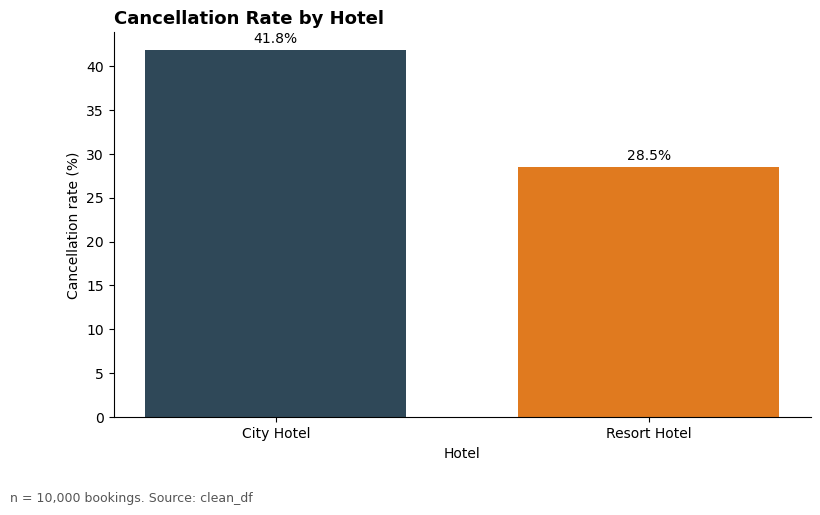

In [328]:
base = clean_df.copy()
q02 = (
    base.groupby("hotel")
    .agg(
        n_bookings=("booking_id", "count"),
        n_canceled=("is_canceled", "sum")
    )
    .reset_index()
)
q02["cancel_rate_pct"] = (
    q02["n_canceled"] / q02["n_bookings"] * 100
).round(2)
q02["shared_pct"] = (
    q02["n_bookings"] / q02["n_bookings"].sum() * 100
).round(2)
print(q02)

fig, ax = plt.subplots(figsize=(9,5))
city_color = HOTEL_COLORS["City Hotel"]
resort_color = HOTEL_COLORS["Resort Hotel"]
bars = ax.bar(
    q02["hotel"],
    q02["cancel_rate_pct"],
    width=0.7,
    color=[
        city_color if h == "City Hotel" else resort_color
        for h in q02["hotel"]
    ]
)
ax.bar_label(bars, fmt="%.1f%%", padding=3)

finish_chart(
    ax,
    "Cancellation Rate by Hotel",
    "Hotel",
    "Cancellation rate (%)",
    note=f"n = {q02['n_bookings'].sum():,} bookings. Source: clean_df"
)
save_table(q02, 'q02_hotel_cancel')
save_fig(fig, "fig01_hotel_cancel")
plt.show()

In [329]:
check('q02_hotel_cancel đã được tạo', lambda: q02 is not None and len(q02) > 0)
check('q02 có đúng 2 khách sạn', lambda: len(q02) == 2)
check('Đã lưu fig01_hotel_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig01_hotel_cancel.png').exists())

✅ q02_hotel_cancel đã được tạo
✅ q02 có đúng 2 khách sạn
✅ Đã lưu fig01_hotel_cancel.png


True

> **✍️ Nhận xét Câu 2** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
>
> 1. **Phát hiện chính:** City Hotel hủy phòng nhiều hơn Resort Hotel
> 2. **Số liệu và mẫu số:** Trong 10.000 đặt phòng sau làm sạch, City Hotel có tỷ lệ hủy 41,79% . Resort Hotel có tỷ lệ hủy 28,50%.
> 3. **So sánh làm rõ:** Chênh lệch là 13,29%, tương đương City Hotel cao khoảng 1,47 lần -> City Hotel chịu rủi ro hủy phòng cao hơn rõ rệt
> 4. **Giới hạn:** dữ liệu không cho biết lý do hủy, nên không thể kết luận loại khách sạn là nguyên nhân.
>
> *Nguồn: `q02_hotel_cancel.csv · fig01_hotel_cancel.png`*

## Câu 3 · Mùa vụ: số đặt phòng theo tháng đến năm 2016

| | |
|---|---|
| **Cần tính** | Chỉ năm **2016** (năm duy nhất đủ 12 tháng trong dữ liệu): số đặt phòng theo tháng × khách sạn; tỷ lệ hủy theo tháng. Nêu tháng cao nhất, thấp nhất của mỗi khách sạn. |
| **Mẫu số và trình bày** | Biểu đồ 2: hai đường theo tháng 1–12. Có thể dùng `monthly_summary`. Không so sánh trực tiếp với 2015, 2017 (thiếu tháng). |
| **Đầu ra** | `clean_df` → `q03_monthly_arrivals_2016` + `fig02_monthly_arrivals_2016.png` |

**Gợi ý:** Cột gợi ý: `arrival_month, City Hotel, Resort Hotel, total, cancel_rate_pct`.

,Month,City Hotel,Resort Hotel,City Hotel Cancel Rate (%),Resort Hotel Cancel Rate (%),Total Bookings
0,January,117,62,29.06,9.68,179
1,February,206,139,33.01,33.09,345
2,March,267,140,38.58,23.57,407
3,April,288,160,42.01,28.75,448
4,May,291,162,45.7,27.78,453
5,June,321,124,41.74,25.81,445
6,July,248,123,29.44,31.71,371
7,August,285,143,34.39,41.26,428
8,September,337,126,44.21,29.37,463
9,October,360,157,45.83,28.66,517


💾 outputs/tables/q03_monthly_arrivals_2016.csv  (12 dòng)
🖼️  outputs/figures/fig02_monthly_arrivals_2016.png


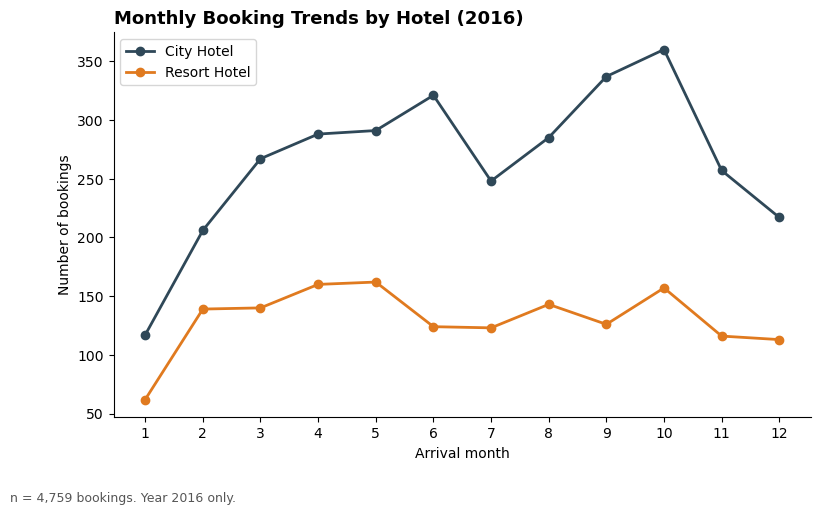

In [330]:
base1 = clean_df.copy()

monthly = base1[
    base1["arrival_date"].notna()
    & (base1["arrival_date"].dt.year == 2016)
].copy()

monthly["month"] = monthly["arrival_date"].dt.month

q03 = (
    monthly.groupby(["month", "hotel"])
    .size()
    .unstack(fill_value=0)
    .reindex(range(1, 13), fill_value=0)
)

# Sắp xếp tháng theo thứ tự thời gian
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

cancel_summary = (
    monthly.groupby(["month", "hotel"])
    .agg(
        total=("booking_id", "count"),
        canceled=("is_canceled", "sum")
    )
)

cancel_summary["cancel_rate_pct"] = (
    cancel_summary["canceled"]
    / cancel_summary["total"].replace(0, np.nan)
    * 100
).round(2)

# Chuyển thành bảng riêng cho từng khách sạn
cancel_rate = (
    cancel_summary["cancel_rate_pct"]
    .unstack()
    .reindex(range(1, 13))
)

cancel_rate.columns = [
    f"{hotel} Cancel Rate (%)"
    for hotel in cancel_rate.columns
]

# Ghép vào q03
q03 = q03.join(cancel_rate)

# Tổng booking mỗi tháng
q03["Total Bookings"] = q03["City Hotel"] + q03["Resort Hotel"]

q03.index = month_order
q03.index.name = "Month"

q03 = q03.reset_index(names="Month")

display(q03)
save_table(q03, 'q03_monthly_arrivals_2016')


# Vẽ biểu đồ
fig, ax = plt.subplots(figsize=FIGSIZE)

city_color = HOTEL_COLORS["City Hotel"]
resort_color = HOTEL_COLORS["Resort Hotel"]

for hotel in HOTEL_COLORS:
    ax.plot(
        range(1, 13),
        q03[hotel],
        marker="o",
        linewidth=2,
        label=hotel,
        color=city_color if hotel == "City Hotel" else resort_color
    )

ax.set_xticks(range(1, 13))
ax.legend()

finish_chart(
    ax,
    "Monthly Booking Trends by Hotel (2016)",
    "Arrival month",
    "Number of bookings",
    note=f"n = {len(monthly):,} bookings. Year 2016 only."
)

save_fig(fig, "fig02_monthly_arrivals_2016")
plt.show()



In [331]:
check('q03_monthly_arrivals_2016 đã được tạo', lambda: q03 is not None and len(q03) > 0)
check('q03 có đủ 12 tháng', lambda: len(q03) == 12)
check('Đã lưu fig02_monthly_arrivals_2016.png', lambda: (OUTPUT_DIR / 'figures' / 'fig02_monthly_arrivals_2016.png').exists())

✅ q03_monthly_arrivals_2016 đã được tạo
✅ q03 có đủ 12 tháng
✅ Đã lưu fig02_monthly_arrivals_2016.png


True

> **✍️ Nhận xét Câu 3** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
>
> 1. **Phát hiện chính:** Lượng đặt phòng không đồng đều quanh năm -> có những tháng có lượng đặt nhiều hơn rất nhiều đồng thời lượng booking ở City Hotel nhiều hơn hẳn Resort Hotel
> 2. **Số liệu và mẫu số:** Tỷ lệ cancel của tháng 10 của City Hotel cũng là tháng booking cao nhất cũng là xấp xỉ 45.83% còn cao nhất của Resort Hotel tỷ lệ hủy cao nhất xuất hiện vào tháng 8, đạt 41,26%.
> 3. **So sánh làm rõ:** Tại tháng 10, tỷ lệ hủy của City Hotel cao hơn Resort Hotel 17.17%. Đáng chú ý, trong tháng 8, Resort Hotel có tỷ lệ hủy cao hơn City Hotel khoảng 6,87%.
> 4. **Giới hạn:** Dữ liệu không cho biết nguyên nhân khách hủy phòng
>
> *Nguồn: `outputs/tables/q03_monthly_arrivals_2016.csv · outputs/figures/fig02_monthly_arrivals_2016.png`*


## Câu 4 · Thời gian đặt trước (lead time) và hủy phòng

| | |
|---|---|
| **Cần tính** | Thống kê `lead_time` theo khách sạn (số mẫu, trung bình, trung vị, Q1, Q3, max) và **tỷ lệ hủy theo `lead_time_group`**. |
| **Mẫu số và trình bày** | Biểu đồ 3: cột tỷ lệ hủy theo 5 nhóm, **đúng thứ tự** `0-7 → 181+`. Đây là mối liên hệ quan sát, không phải nhân quả. |
| **Đầu ra** | `clean_df` → `q04_leadtime_stats`, `q04_leadtime_cancel` + `fig03_leadtime_cancel.png` |

**Gợi ý:** Lưu **cả 2 bảng**.

LEAD TIME STATISTICS
  lead_time_group  n_bookings  mean_lead_time  median_lead_time  \
0        0-7 days        1581        2.374447               2.0   
1       8-30 days        1537       18.014964              17.0   
2      31-90 days        2542       57.175452              55.0   
3     91-180 days        2244       131.81328             131.0   
4   Over 180 days        2065      277.639709             263.0   

   min_lead_time  max_lead_time  
0              0              7  
1              8             30  
2             31             90  
3             91            180  
4            181            709  
💾 outputs/tables/q04_leadtime_stats.csv  (5 dòng)

CANCELLATION RATE BY LEAD TIME
  lead_time_group  n_bookings  n_canceled  cancel_rate_pct
0        0-7 days        1581         159            10.06
1       8-30 days        1537         425            27.65
2      31-90 days        2542         946            37.21
3     91-180 days        2244        1001            4

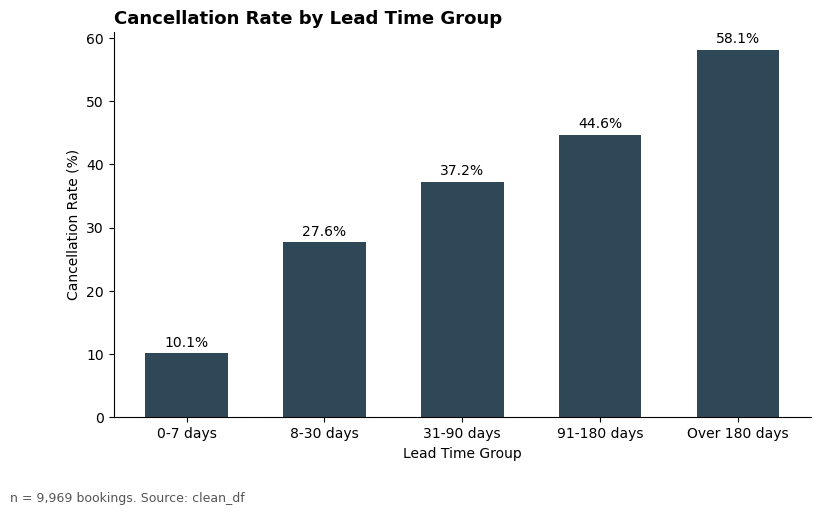

In [332]:
q04 = None
q04_b = None

base4 = clean_df.copy()

# Chia Lead Time thành 5 nhóm
bins = [-1, 7, 30, 90, 180, float("inf")]
labels = ["0-7 days", "8-30 days", "31-90 days", "91-180 days", "Over 180 days"]

base4["lead_time_group"] = pd.cut(
    base4["lead_time"],
    bins=bins,
    labels=labels
)

# Q04: Thống kê Lead Time theo nhóm
q04 = (
    base4.groupby("lead_time_group", observed=False)
    .agg(
        n_bookings=("booking_id", "count"),
        mean_lead_time=("lead_time", "mean"),
        median_lead_time=("lead_time", "median"),
        min_lead_time=("lead_time", "min"),
        max_lead_time=("lead_time", "max")
    )
    .reset_index()
)

print("LEAD TIME STATISTICS")
print(q04)

save_table(q04, "q04_leadtime_stats")


# Q04_B: Tỷ lệ hủy theo nhóm Lead Time
q04_b = (
    base4.groupby("lead_time_group", observed=False)
    .agg(
        n_bookings=("booking_id", "count"),
        n_canceled=("is_canceled", "sum")
    )
    .reset_index()
)

q04_b["cancel_rate_pct"] = (
    q04_b["n_canceled"] / q04_b["n_bookings"] * 100
).round(2)

print("\nCANCELLATION RATE BY LEAD TIME")
print(q04_b)

save_table(q04_b, "q04_leadtime_cancel")


# Vẽ biểu đồ từ q04_b
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    q04_b["lead_time_group"].astype(str),
    q04_b["cancel_rate_pct"],
    color="#2F4858",
    width=0.6
)

ax.bar_label(bars, fmt="%.1f%%", padding=3)

finish_chart(
    ax,
    "Cancellation Rate by Lead Time Group",
    "Lead Time Group",
    "Cancellation Rate (%)",
    note=f"n = {q04_b['n_bookings'].sum():,} bookings. Source: clean_df"
)

save_fig(fig, "fig03_leadtime_cancel")
plt.show()


In [333]:
check('q04_leadtime_stats đã được tạo', lambda: q04 is not None and len(q04) > 0)
check('q04_leadtime_cancel đã được tạo', lambda: q04_b is not None and len(q04_b) > 0)
check('q04_leadtime_cancel có 5 nhóm', lambda: len(q04_b) == 5)
check('Đã lưu fig03_leadtime_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig03_leadtime_cancel.png').exists())

✅ q04_leadtime_stats đã được tạo
✅ q04_leadtime_cancel đã được tạo
✅ q04_leadtime_cancel có 5 nhóm
✅ Đã lưu fig03_leadtime_cancel.png


True

> **✍️ Nhận xét Câu 4** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
>
> 1. **Phát hiện chính:** Lead time: đặt càng sớm, tỷ lệ hủy càng cao
> 2. **Số liệu và mẫu số:** Trong 9.969 booking có lead_time hợp lệ, tỷ lệ hủy tăng đều theo nhóm: 10,06% cho 0–7 ngày, 27,65% cho 8–30 ngày, 37,21% cho 31–90 ngày, 44,61% cho 91–180 ngày và 58,06% cho trên 180 ngày.
> 3. **So sánh làm rõ:** Nhóm đặt trên 180 ngày hủy cao gấp khoảng 5,8 lần nhóm đặt 0–7 ngày hơn xấp xỉ 48%. Mẫu số mỗi nhóm đều trên 1.500 nên so sánh khá ổn định.
> 4. **Giới hạn:** dữ liệu không cho biết khách đặt sớm có thể khác khách đặt sát ngày về nhiều mặt -> chưa đủ dữ liệu để kết luận đặt phòng sớm là nguyên nhân hủy phòng
>
> *Nguồn: bảng `outputs/tables/…` · `outputs/figures/fig03_leadtime_cancel.png`*

## Câu 5 · Top 10 quốc gia của khách

| | |
|---|---|
| **Cần tính** | Đếm đặt phòng theo `country`; Top 10; tỷ lệ trên **tổng số đặt phòng**; tỷ lệ hủy mỗi nước. Báo cáo riêng số đặt phòng thiếu quốc gia. Đồng hạng → sắp tiếp theo mã. |
| **Mẫu số và trình bày** | Biểu đồ 4: cột ngang, sắp theo số lượng. |
| **Đầu ra** | `clean_df` → `q05_top10_country` + `fig04_top10_country.png` |

**Gợi ý:** Cột gợi ý: `rank, country, n_bookings, pct_of_all_bookings, cancel_rate_pct`.

⏳ Chưa có bảng q05_top10_country — bỏ qua.
💾 outputs/tables/q05_top10_country.csv  (10 dòng)


,Rank,Country,Total Bookings,Booking Share (%),Canceled Bookings,Cancellation Rate (%)
0,1,PRT,4005,40.05,2310,57.68
1,2,GBR,999,9.99,197,19.72
2,3,FRA,876,8.76,167,19.06
3,4,ESP,700,7.00,172,24.57
4,5,DEU,650,6.50,121,18.62
5,6,ITA,294,2.94,99,33.67
6,7,IRL,281,2.81,67,23.84
7,8,BEL,201,2.01,37,18.41
8,9,USA,198,1.98,49,24.75
9,10,BRA,192,1.92,79,41.15


⚠️  Tên q05_ranking_top10_country.csv không có trong danh sách chuẩn: kiểm tra lại chính tả.
💾 outputs/tables/q05_ranking_top10_country.csv  (10 dòng)
🖼️  outputs/figures/fig04_top10_country.png


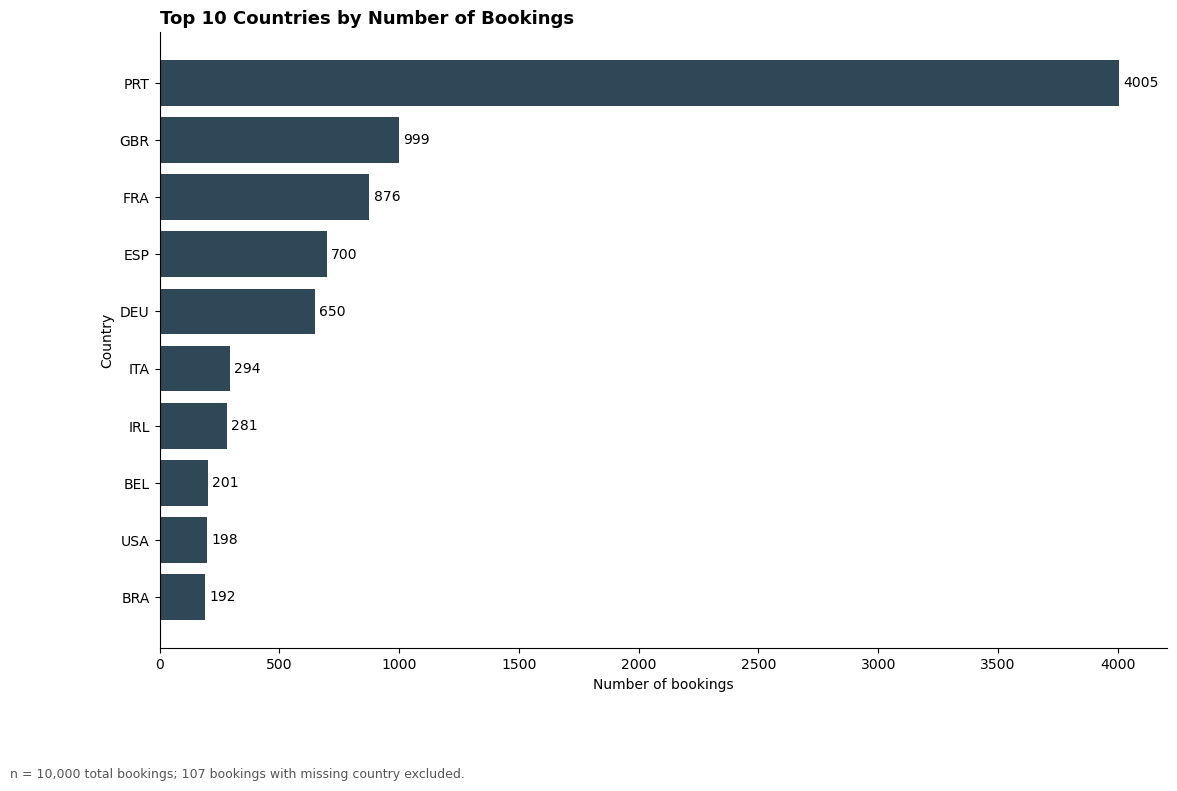

In [334]:
q05 = None   # TODO: bảng q05_top10_country

save_table(q05, 'q05_top10_country')
base3= clean_df.copy()

country_data = base3.dropna(subset=["country"]).copy()

q05 = (
    country_data.groupby("country")
    .agg(
        n_bookings=("booking_id", "count"),
        n_canceled=("is_canceled", "sum")
    )
    .reset_index()
)

# Tính tỷ lệ trên tổng số booking
q05["pct_of_all_bookings"] = (
    q05["n_bookings"] / len(base3) * 100
).round(2)

# Tỷ lệ hủy của từng quốc gia
q05["cancel_rate_pct"] = (
    q05["n_canceled"] / q05["n_bookings"] * 100
).round(2)

# Sắp xếp: số booking giảm dần, mã quốc gia tăng dần
q05 = q05.sort_values(
    ["n_bookings", "country"],
    ascending=[False, True]
).head(10).reset_index(drop=True)

q05.insert(0, "rank", range(1, len(q05) + 1))
save_table(q05, "q05_top10_country")
plot_data = q05.sort_values("n_bookings", ascending=True)

fig, ax = plt.subplots(figsize=(13, 8))

bars = ax.barh(
    plot_data["country"],
    plot_data["n_bookings"],
    color="#2F4858"
)

ax.bar_label(bars, padding=3, fmt="%d")

finish_chart(
    ax,
    "Top 10 Countries by Number of Bookings",
    "Number of bookings",
    "Country",
    note=(
        f"n = {len(clean_df):,} total bookings; "
        f"{clean_df['country'].isna().sum():,} bookings "
        "with missing country excluded."
    )
)
ranking_q05 = q05[
    [
        "rank",
        "country",
        "n_bookings",
        "pct_of_all_bookings",
        "n_canceled",
        "cancel_rate_pct"
    ]
].copy()

ranking_q05.columns = [
    "Rank",
    "Country",
    "Total Bookings",
    "Booking Share (%)",
    "Canceled Bookings",
    "Cancellation Rate (%)"
]

# Format percentages
ranking_q05["Booking Share (%)"] = (
    ranking_q05["Booking Share (%)"].round(2)
)

ranking_q05["Cancellation Rate (%)"] = (
    ranking_q05["Cancellation Rate (%)"].round(2)
)

display(ranking_q05)

# Export ranking table
save_table(ranking_q05, "q05_ranking_top10_country")


save_fig(fig, "fig04_top10_country")
plt.show()

In [335]:
check('q05_top10_country đã được tạo', lambda: q05 is not None and len(q05) > 0)
check('q05 có 10 quốc gia', lambda: len(q05) == 10)
check('Đã lưu fig04_top10_country.png', lambda: (OUTPUT_DIR / 'figures' / 'fig04_top10_country.png').exists())

✅ q05_top10_country đã được tạo
✅ q05 có 10 quốc gia
✅ Đã lưu fig04_top10_country.png


True

> **✍️ Nhận xét Câu 5** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
>
> 1. **Phát hiện chính:** Cơ cấu khách tập trung rất cao vào khách nội địa và một số thị trường Tây Âu, đặc biệt là Portugal
> 2. **Số liệu và mẫu số:** Top 5 (PRT, GBR, FRA, ESP, DEU) chiếm tổng cộng   72.30% đặt phòng, và tỷ lệ hủy phòng của các nước này, đặc biệt là portugal rất
> 3. **So sánh làm rõ:** Nhóm có tỷ lệ hủy thấp nhất là BEL (18,41%) và DEU (18,62%), cao nhất là PRT (57,68%) chênh lệch 39,27%. Cỡ mẫu nhỏ nhất trong Top 10 là BRA với 192 đặt phòng, nên các tỷ lệ ở nhóm cuối bảng kém ổn định hơn PRT hay GBR.
> 4. **Giới hạn:** dữ liệu không cho biết người của quốc gia đó hủy có liên quan gì tới bản thân quốc gia đó, đồng thời cũng không cho biết CN và CHN bị chia đôi có thể đạt tới top mấy.
>
> *Nguồn: bảng `outputs/tables/q05_top10_country.csv · outputs/figures/fig04_top10_country.png`*

## Câu 6 · Phân khúc thị trường

| | |
|---|---|
| **Cần tính** | Theo `market_segment`: số đặt phòng, tỷ trọng, tỷ lệ hủy; báo cáo riêng số thiếu phân khúc. |
| **Mẫu số và trình bày** | Biểu đồ 5: cột ngang (số đặt phòng hoặc tỷ lệ hủy), sắp theo giá trị. Nêu phân khúc nhỏ (ví dụ Aviation) có mẫu ít → tỷ lệ kém ổn định. |
| **Đầu ra** | `clean_df` → `q06_segment_cancel` + `fig05_segment_cancel.png` |

**Gợi ý:** Thêm cột `n_bookings` cạnh tỷ lệ để người đọc thấy cỡ mẫu.

In [336]:
seg_valid = clean_df.dropna(subset=["market_segment"]).copy()

q06 = seg_valid.groupby("market_segment").agg(n_bookings=("booking_id", "count"),n_canceled=("is_canceled", "sum"),).reset_index()

Nhận xét:
- `q06` hiện giờ đã có 2 cột variables là `n_booking`, `n_canceled`; tương ứng là tổng số booking id mỗi nhãn và tổng số booking bị huỷ.
- Mỗi dòng là tương ứng với một nhãn trong cột `market_segment`.

In [337]:
# tạo cột phần trăm đặt phòng và huỷ phòng theo phân khúc thị trường
q06["share_pct"] = q06["n_bookings"] / len(seg_valid) * 100
q06["cancel_rate_pct"] = (q06["n_canceled"] / q06["n_bookings"] * 100)
q06

,market_segment,n_bookings,n_canceled,share_pct,cancel_rate_pct
0,Aviation,21,5,0.210063,23.809524
1,Complementary,61,10,0.610183,16.393443
2,Corporate,441,81,4.411323,18.367347
3,Direct,1018,153,10.183055,15.02947
4,Groups,1703,1054,17.035111,61.890781
5,Offline TA/TO,2012,683,20.126038,33.946322
6,Online TA,4741,1753,47.424227,36.975322


In [338]:
q06["share_pct"] = q06["share_pct"].round(2)  # làm tròn tới 2 chữ số sau dấu "," cho dễ quan sát
q06["cancel_rate_pct"] = q06["cancel_rate_pct"].round(2)
# lưu bảng theo tên đã yêu cầu
save_table(q06, "q06_segment_cancel")

💾 outputs/tables/q06_segment_cancel.csv  (7 dòng)


🖼️  outputs/figures/fig05_segment_cancel.png


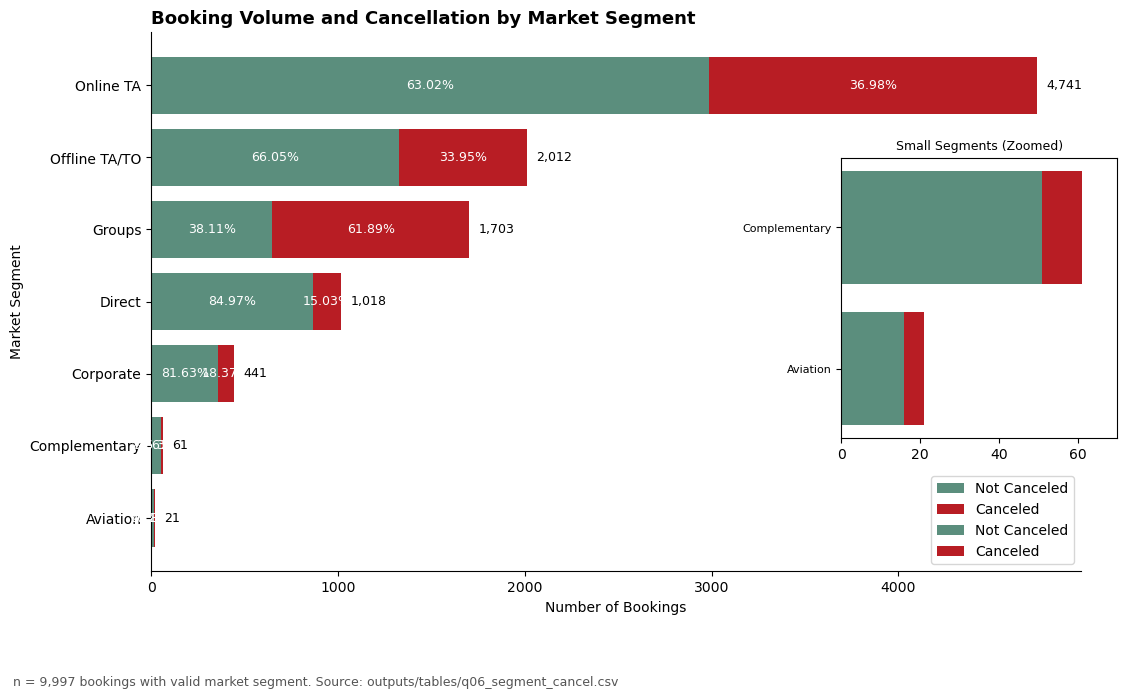

In [339]:
# Sắp xếp market segment theo tổng booking giảm dần
q06_plot = (
    q06.sort_values("n_bookings", ascending=False)
       .reset_index(drop=True)
)

not_canceled = q06_plot["n_bookings"] - q06_plot["n_canceled"]
not_cancel_pct = 100 - q06_plot["cancel_rate_pct"]

fig, ax = plt.subplots(figsize=(12, 7))

y = range(len(q06_plot))

# Vẽ hai phần của thanh ngang chồng lên nhau
ax.barh(
    y,
    not_canceled,
    color="#5B8E7D",
    label="Not Canceled"
)

ax.barh(
    y,
    q06_plot["n_canceled"],
    left=not_canceled,
    color="#B81D24",
    label="Canceled"
)

# Đưa tên market segment lên trục Y
ax.set_yticks(list(y))
ax.set_yticklabels(q06_plot["market_segment"])

# Đưa nhóm có số booking lớn nhất lên trên cùng
ax.invert_yaxis()

# Hiển thị phần trăm bên trong mỗi thanh
for i in y:
    # Tỷ lệ không hủy
    if not_canceled.iloc[i] > 0:
        ax.text(
            not_canceled.iloc[i] / 2,
            i,
            f'{not_cancel_pct.iloc[i]:.2f}%',
            ha="center",
            va="center",
            color="white",
            fontsize=9
        )

    # Tỷ lệ hủy
    if q06_plot["n_canceled"].iloc[i] > 0:
        ax.text(
            not_canceled.iloc[i] + q06_plot["n_canceled"].iloc[i] / 2,
            i,
            f'{q06_plot["cancel_rate_pct"].iloc[i]:.2f}%',
            ha="center",
            va="center",
            color="white",
            fontsize=9
        )

# Hiển thị tổng số booking ở cuối mỗi thanh
for i in y:
    ax.text(
        q06_plot["n_bookings"].iloc[i] + 50,
        i,
        f'{q06_plot["n_bookings"].iloc[i]:,}',
        ha="left",
        va="center",
        fontsize=9
    )

# Phóng to hai phân khúc có ít booking
small_segments = (
    q06_plot[
        q06_plot["market_segment"].isin(
            ["Aviation", "Complementary"]
        )
    ]
    .reset_index(drop=True)
)

small_not_canceled = (
    small_segments["n_bookings"] - small_segments["n_canceled"]
)

small_y = range(len(small_segments))

# Thu nhỏ vùng biểu đồ chính để dành chỗ bên phải
#fig.subplots_adjust(right=0.70)

# Tạo vùng zoom bên phải biểu đồ chính
axins = fig.add_axes([0.70, 0.30, 0.23, 0.40])

# Vẽ thanh ngang trong biểu đồ phóng to
ax.barh(
    y,
    not_canceled,
    color=STATUS_COLORS["Check-Out"],
    label="Not Canceled"
)

ax.barh(
    y,
    q06_plot["n_canceled"],
    left=not_canceled,
    color=STATUS_COLORS["Canceled"],
    label="Canceled"
)

axins.set_yticks(list(small_y))
axins.set_yticklabels(
    small_segments["market_segment"],
    fontsize=8
)

axins.invert_yaxis()
axins.set_xlim(0, 70)
axins.set_title("Small Segments (Zoomed)", fontsize=9)

# Hiển thị phần trăm trong biểu đồ phóng to
for i in small_y:
    axins.barh(
    small_y,
    small_not_canceled,
    color=STATUS_COLORS["Check-Out"]
)

axins.barh(
    small_y,
    small_segments["n_canceled"],
    left=small_not_canceled,
    color=STATUS_COLORS["Canceled"]
)

# Chú thích và tiêu đề
ax.legend(loc="lower right")

finish_chart(
    ax,
    "Booking Volume and Cancellation by Market Segment",
    "Number of Bookings",
    "Market Segment",
    note=(
        f"n = {len(seg_valid):,} bookings with valid market segment. "
        "Source: outputs/tables/q06_segment_cancel.csv"
    )
)

save_fig(fig, "fig05_segment_cancel")
plt.show()


In [340]:
check('q06_segment_cancel đã được tạo', lambda: q06 is not None and len(q06) > 0)
check('Đã lưu fig05_segment_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig05_segment_cancel.png').exists())

✅ q06_segment_cancel đã được tạo
✅ Đã lưu fig05_segment_cancel.png


True

> **✍️ Nhận xét Câu 6** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
>
> 1. **Phát hiện chính:** `Online TA`là phân khúc có số lượng đặt phòng lớn nhất với 4741 booking (chiếm khoảng 47.42%); `Groups` với 1703 có tỷ lệ hủy cao nhất, đạt 61.89%. `Aviation` và `Complementary` có số lượng booking rất nhỏ so với tổng số booking nên tỉ lệ huỷ phòng của 2 nhãn này có thể chưa thực sự đáng tin.
> 2. **Số liệu và mẫu số:** 9997 trên 10000 đặt phòng (đã loại 3 đặt phòng vì bị thiếu dữ liệu).
> 3. **So sánh làm rõ:** `Groups` có 1703 booking- khoảng 17% số booking và đồng thời có tỷ lệ hủy cao nhất (61.89%), trong khi `Direct`với 1018 booking có tỷ lệ hủy thấp nhất (15.03%). Chênh lệch giữa hai phân khúc là 46.86 điểm phần trăm, cho thấy tỷ lệ hủy có sự khác biệt đáng kể tùy theo phân khúc thị trường (kết luận này có tính tin cậy tương đối ổn vì lượng booking của cả 2 cột đều khá cao, nhưng vẫn cần điều tra thêm).
> 4. **Giới hạn:** dữ liệu không cho biết lý do huỷ phòng, vì vậy khó có thể đánh giá được sự tương quan thật sự giữa tỉ lệ huỷ phòng và phân khúc thị trường.
>
> *Nguồn: bảng `outputs/tables/q06_segment_cancel.csv` · `outputs/figures/fig05_segment_cancel.png`*

## Câu 7 · Loại đặt cọc và trạng thái đặt phòng

| | |
|---|---|
| **Cần tính** | Bảng chéo `deposit_type × reservation_status`; tỷ lệ **trong từng loại đặt cọc** (Check-Out, Canceled, No-Show, và `Unknown` nếu trạng thái thiếu). |
| **Mẫu số và trình bày** | Biểu đồ 6: cột chồng 100%. So sánh tỷ lệ hủy giữa các loại theo điểm phần trăm và nêu cỡ mẫu (Refundable rất ít). |
| **Đầu ra** | `clean_df` → `q07_deposit_cancel` + `fig06_deposit_cancel.png` |

**Gợi ý:** `pd.crosstab(..., normalize='index')`; điền `'Unknown'` **chỉ khi trình bày**.

In [341]:
# lấy ra 2 cột cần sử dụng, cột `deposit_type` thì bỏ NaN, cột `reservation_status` thì chuyển NaN thành `Unkown`
# Loại booking thiếu loại đặt cọc vì ta đang tập trung vào xem tỉ lệ trong các loại đặt cọc, dữ liệu thiếu loại đặt cọc có thê gây sao nhãng
dep = clean_df.dropna(subset=["deposit_type"]).copy()
# Chuyển trạng thái đặt phòng bị thiếu thành Unknown
dep["reservation_status"] = (dep["reservation_status"].fillna("Unknown"))
# xem sau khi loại bỏ những booking thiếu loại đặt cọc thì ta còn bao nhiêu dòng
dep.shape

(10000, 31)

In [342]:
# Đếm số booking theo từng loại đặt cọc và trạng thái
count_tab = (dep.groupby(["deposit_type", "reservation_status"]).size().reset_index(name="count"))
# Tính tổng booking của từng loại đặt cọc
count_tab["total"] = (count_tab.groupby("deposit_type")["count"].transform("sum"))
# Tính tỷ lệ phần trăm
count_tab["percentage(%)"] = (count_tab["count"] / count_tab["total"] * 100).round(2)
# Tạo bảng kết quả
q07 = count_tab
# Lưu CSV
save_table(q07, "q07_deposit_cancel")
q07

💾 outputs/tables/q07_deposit_cancel.csv  (9 dòng)


,deposit_type,reservation_status,count,total,percentage(%)
0,No Deposit,Canceled,2377,8728,27.23
1,No Deposit,Check-Out,6224,8728,71.31
2,No Deposit,No-Show,105,8728,1.20
3,No Deposit,Unknown,22,8728,0.25
4,Non Refund,Canceled,1244,1259,98.81
5,Non Refund,Check-Out,12,1259,0.95
6,Non Refund,Unknown,3,1259,0.24
7,Refundable,Canceled,5,13,38.46
8,Refundable,Check-Out,8,13,61.54


Nhận xét:
- Vậy là bảng đã được hoàn thành, trong bảng có cả số lượng của từng nhãn trạng thái phòng theo cách đặt trước và tỉ lệ phần trăm. Vậy là có tổng 25 Unknown

               count        mean         std   min    25%    50%    75%    max
deposit_type                                                                  
No Deposit    8701.0    89.29307   92.653835   0.0   15.0   57.0  137.0  709.0
Non Refund    1255.0  212.588845  132.479663   1.0  101.0  186.0  304.0  629.0
Refundable      13.0  166.153846   86.689913  47.0  162.0  169.0  169.0  339.0
🖼️  outputs/figures/fig06_deposit_cancel.png


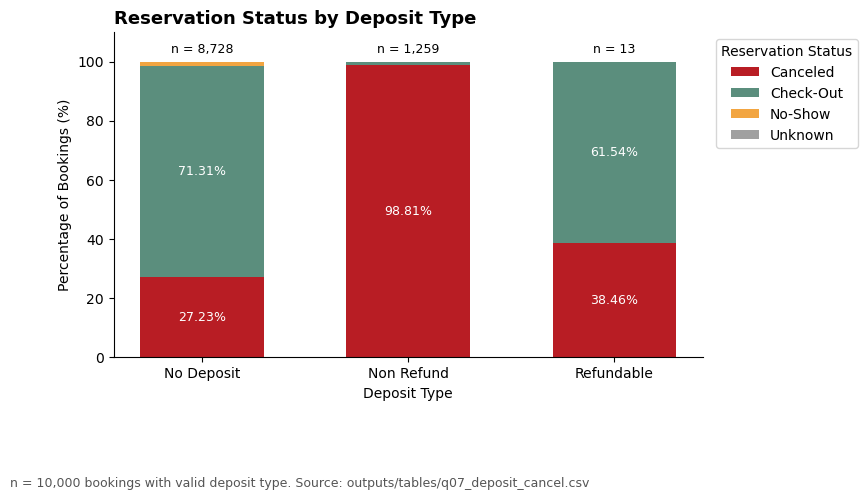

is_canceled         0     1
lead_time_group            
0-7               955   125
8-30             1112   425
31-90            1596   946
91-180           1243  1001
180+              866  1199
Chi-square: 772.9124279636299
P-value: 5.654854056859733e-166
Cramer's V: 0.28571696001154223
⚠️  Tên fig07_non_refund_lead_time_cancel.png không có trong danh sách chuẩn: kiểm tra lại chính tả.
🖼️  outputs/figures/fig07_non_refund_lead_time_cancel.png


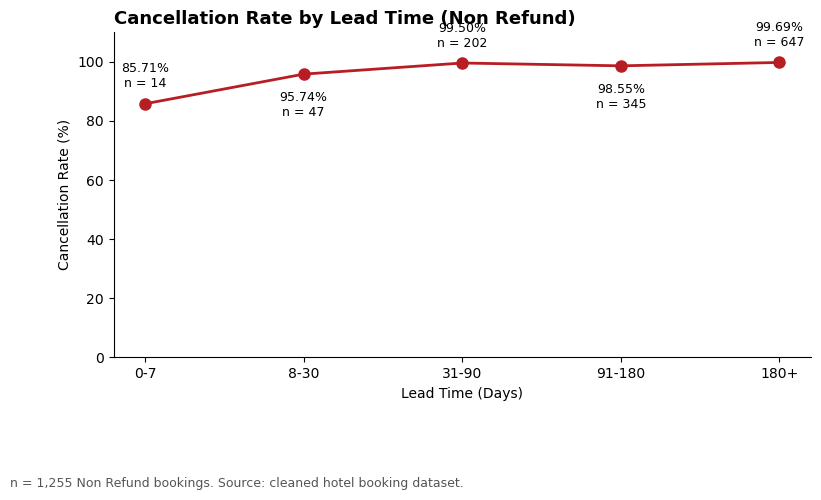

In [343]:
# Chuẩn bị dữ liệu cho biểu đồ
plot_data = q07.pivot(
    index="deposit_type",
    columns="reservation_status",
    values="percentage(%)"
)

# Quy định thứ tự các trạng thái
status_order = ["Canceled", "Check-Out", "No-Show", "Unknown"]
plot_data = plot_data.reindex(columns=status_order).fillna(0)

# Lấy số lượng booking của từng loại đặt cọc
sample_sizes = (q07.groupby("deposit_type")["total"].first().reindex(plot_data.index))

# Màu sắc đồng bộ với Figure 5
status_colors = {
    "Canceled": STATUS_COLORS["Canceled"],
    "Check-Out": STATUS_COLORS["Check-Out"],
    "No-Show": STATUS_COLORS["No-Show"],
    "Unknown": "#A0A0A0"
}

# Tạo biểu đồ
fig, ax = plt.subplots(figsize=(9, 5))

x = range(len(plot_data))
bottom = [0] * len(plot_data)

# Vẽ từng trạng thái thành một phần của cột chồng
for status in status_order:
    values = plot_data[status]

    ax.bar(
        x,
        values,
        bottom=bottom,
        color=status_colors[status],
        label=status,
        width=0.60
    )

    # Chỉ hiển thị nhãn phần trăm nếu phần đủ lớn
    for i, value in enumerate(values):
        if value >= 5:
            ax.text(
                i,
                bottom[i] + value / 2,
                f"{value:.2f}%",
                ha="center",
                va="center",
                color="white",
                fontsize=9
            )

    bottom = [
        bottom[i] + values.iloc[i]
        for i in range(len(values))
    ]

# Tên loại đặt cọc nằm ngang
ax.set_xticks(list(x))
ax.set_xticklabels(
    plot_data.index,
    rotation=0,
    ha="center"
)

# Hiển thị cỡ mẫu phía trên mỗi cột
for i, deposit_type in enumerate(plot_data.index):
    ax.text(i, 102, f'n = {sample_sizes.loc[deposit_type]:,}', ha="center", va="bottom", fontsize=9)
# Giới hạn trục Y
ax.set_ylim(0, 110)

# Chú thích
ax.legend(title="Reservation Status", loc="upper left", bbox_to_anchor=(1.01, 1))

# Tiêu đề và nhãn trục
finish_chart(
    ax,
    "Reservation Status by Deposit Type",
    "Deposit Type",
    "Percentage of Bookings (%)",
    note=(
        f"n = {len(dep):,} bookings with valid deposit type. "
        "Source: outputs/tables/q07_deposit_cancel.csv"
    ))

# Điều chỉnh bố cục
fig.subplots_adjust( right=0.78, bottom=0.20, top=0.85)
print(dep.groupby("deposit_type")["lead_time"].describe())

save_fig(fig, "fig06_deposit_cancel")
plt.show()
import pandas as pd
from scipy.stats import chi2_contingency

test_df = clean_df[
    ["lead_time", "is_canceled"]
].dropna().copy()

bins = [0, 7, 30, 90, 180, float("inf")]

labels = ["0-7", "8-30", "31-90", "91-180", "180+"]

test_df["lead_time_group"] = pd.cut(
    test_df["lead_time"],
    bins=bins,
    labels=labels
)

contingency_table = pd.crosstab(
    test_df["lead_time_group"],
    test_df["is_canceled"]
)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print(contingency_table)
print("Chi-square:", chi2)
print("P-value:", p_value)
n = contingency_table.to_numpy().sum()
min_dim = min(contingency_table.shape) - 1

cramers_v = np.sqrt(
    chi2 / (n * min_dim)
)

print("Cramer's V:", cramers_v)

# Visualize cancellation rate by lead time for Non Refund bookings

# Filter Non Refund bookings
plot_df = clean_df[
    (clean_df["deposit_type"] == "Non Refund") &
    (clean_df["lead_time"].notna()) &
    (clean_df["is_canceled"].notna())
].copy()

# Group lead time
plot_df["lead_time_group"] = pd.cut(
    plot_df["lead_time"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate cancellation rate
plot_data = (
    plot_df.groupby("lead_time_group", observed=False)
    .agg(
        total=("is_canceled", "count"),
        canceled=("is_canceled", "sum"),
        cancellation_rate=("is_canceled", "mean")
    )
    .reindex(labels)
)

plot_data["cancellation_rate"] *= 100

# Create chart
# Create chart
fig, ax = plt.subplots(figsize=(9, 5))

x = range(len(plot_data))

ax.plot(
    x,
    plot_data["cancellation_rate"],
    marker="o",
    linewidth=2,
    markersize=8,
    color=STATUS_COLORS["Canceled"]
)

# Add labels with alternating positions
for i, row in enumerate(plot_data.itertuples()):
    if pd.notna(row.cancellation_rate):
        offset = 12 if i % 2 == 0 else -30

        ax.annotate(
            f"{row.cancellation_rate:.2f}%\nn = {row.total:,}",
            (i, row.cancellation_rate),
            textcoords="offset points",
            xytext=(0, offset),
            ha="center",
            fontsize=9
        )

ax.set_xticks(list(x))
ax.set_xticklabels(labels, rotation=0, ha="center")

finish_chart(
    ax,
    "Cancellation Rate by Lead Time (Non Refund)",
    "Lead Time (Days)",
    "Cancellation Rate (%)",
    note=(
        f"n = {len(plot_df):,} Non Refund bookings. "
        "Source: cleaned hotel booking dataset."
    )
)

ax.set_ylim(0, 110)
fig.subplots_adjust(bottom=0.20, top=0.85)

save_fig(fig, "fig07_non_refund_lead_time_cancel")
plt.show()


In [344]:
check('q07_deposit_cancel đã được tạo', lambda: q07 is not None and len(q07) > 0)
check('Đã lưu fig06_deposit_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig06_deposit_cancel.png').exists())

✅ q07_deposit_cancel đã được tạo
✅ Đã lưu fig06_deposit_cancel.png


True

> **✍️ Nhận xét Câu 7** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
>
> 1. **Phát hiện chính:** Lượng đặt phòng với nhãn `No Deposit` là nhiều nhất với 8728 bookings và tỉ lệ không huỷ khoảng 71%, khá cao với số lượng booking nhiều như vậy; ngoài ra với cỡ mẫu 1259 bookings, nhóm `Non Refund` có tỉ lệ huỷ cao nhất, 98.81%, cao một cách bất thường
> 2. **Số liệu và mẫu số:** 10000 trên 10000 đặt phòng (không có đặt phòng nào bị mất thông tin ở cột `Deposiy_type`), bao gồm 8728 booking thuộc `No Deposit`, 1259 booking thuộc `Non Refund` và 13 booking thuộc `Refundable`. Có 25 booking thiếu `reservation_status` được giữ lại và phân loại thành Unknown.
> 3. **So sánh làm rõ:** Tỷ lệ hủy của nhóm Non Refund cao hơn nhóm No Deposit 71.58 điểm phần trăm, tương đương khoảng 3.63 lần. Có thể đưa ra một kết luận rằng sự khác biệt giữa các nhãn cũng ảnh hưởng đến tỉ lệ huỷ phòng.
> 4. **Giới hạn:** Kết quả chỉ phản ánh mối liên hệ giữa loại đặt cọc và trạng thái đặt phòng, không chứng minh rằng loại đặt cọc là nguyên nhân khiến khách hủy. Ngoài ra, nhóm Refundable chỉ có 13 booking nên cần được quan sát và ghi nhận thêm, con số 38.46% chưa thể hiện được chính xác xu hướng chung.
>
> *Nguồn: bảng `outputs/tables/"q07_deposit_cancel"` · `outputs/figures/fig06_deposit_cancel.png`*

## Câu 8 · Giá phòng bình quân/đêm (ADR)

| | |
|---|---|
| **Cần tính** | Chỉ đặt phòng **không hủy** có `adr` hợp lệ **và > 0**: theo khách sạn — số mẫu, trung bình, trung vị, min, max, Q1, Q3. Báo cáo riêng số `adr = 0` và số thiếu. |
| **Mẫu số và trình bày** | Biểu đồ 7: histogram độ rộng khoảng 20 EUR, tách hai khách sạn (2 panel hoặc chồng trong suốt). Không xóa giá cao trong miền. |
| **Đầu ra** | `clean_df` → `q08_adr_stats_by_hotel` + `fig07_adr_hist.png` |

**Gợi ý:** `groupby('hotel')['adr'].describe()`.

In [345]:
# Lọc booking không bị hủy
non_canceled = clean_df[clean_df["reservation_status"] != "Canceled"].copy()

# Báo cáo số ADR bằng 0 và số ADR thiếu
print("ADR = 0:", (non_canceled["adr"] == 0).sum())
print("Missing ADR:", non_canceled["adr"].isna().sum())

# Chỉ giữ booking có ADR hợp lệ và lớn hơn 0
adr_valid = non_canceled[non_canceled["adr"].notna() & (non_canceled["adr"] > 0)].copy()

print("Valid bookings:", len(adr_valid))

ADR = 0: 121
Missing ADR: 18
Valid bookings: 6235


In [346]:
q08 = (
    adr_valid.groupby("hotel")["adr"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        min="min",
        max="max",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    ).reset_index())

# Làm tròn các chỉ số giá
q08[["mean", "median", "min", "max", "Q1", "Q3"]] = ( q08[["mean", "median", "min", "max", "Q1", "Q3"]].round(2))
# Lưu bảng
save_table(q08, "q08_adr_stats_by_hotel")

q08

💾 outputs/tables/q08_adr_stats_by_hotel.csv  (2 dòng)


,hotel,count,mean,median,min,max,Q1,Q3
0,City Hotel,3915,108.11,100.67,4.5,336.00,80.75,126.9
1,Resort Hotel,2320,93.57,75.00,6.0,349.67,51.21,120.0


🖼️  outputs/figures/fig07_adr_hist.png


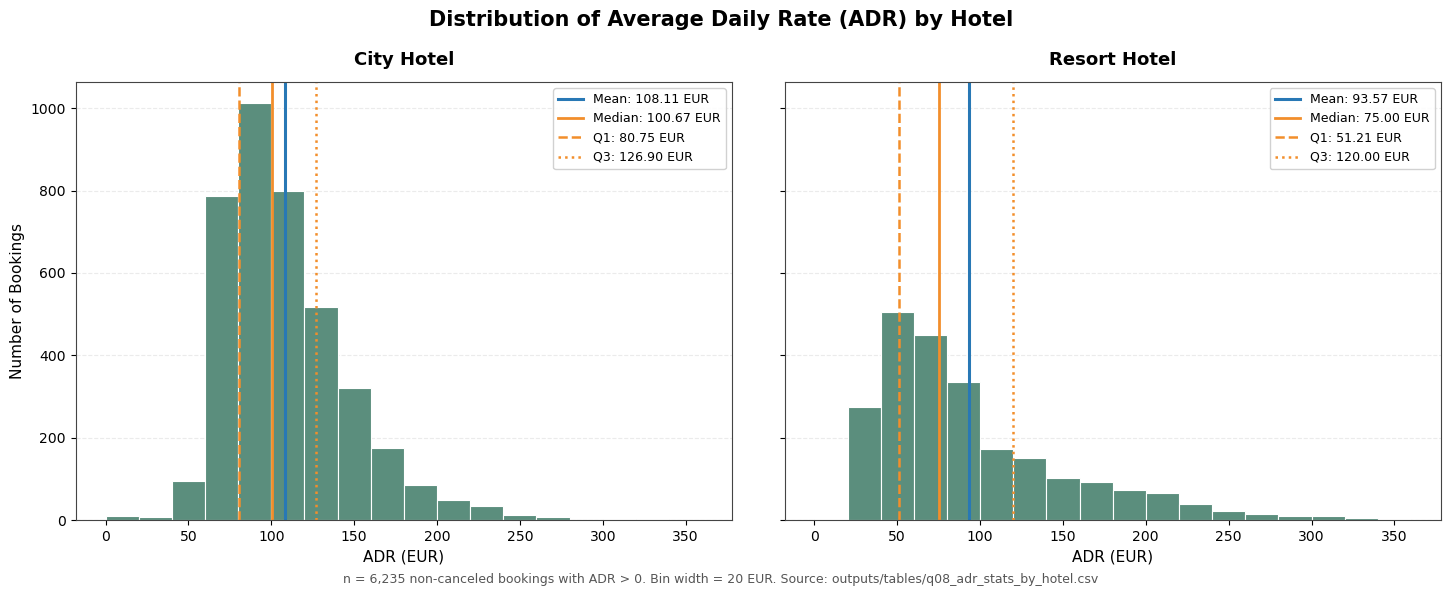

In [347]:
hist_color = HOTEL_COLORS["City Hotel"]
mean_color = HOTEL_COLORS["Resort Hotel"]
quartile_color = "#F2A541"
# Xác định khoảng giá chung, mỗi bin rộng 20 EUR
max_adr = adr_valid["adr"].max()
bins = np.arange(
    0,
    np.ceil(max_adr / 20) * 20 + 20,
    20
)

# Màu sắc
hist_color = "#5B8E7D"
mean_color = "#2878B5"
quartile_color = "#F28E2B"

# Tạo hai biểu đồ có cùng kích thước và thang đo
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    sharex=True,
    sharey=True
)

# Thứ tự khách sạn
hotel_order = adr_valid["hotel"].unique()

# Vẽ histogram và các giá trị thống kê
for ax, hotel in zip(axes, hotel_order):

    hotel_data = adr_valid[
        adr_valid["hotel"] == hotel
    ]["adr"]

    # Lấy thống kê từ bảng q08
    stats = q08.set_index("hotel").loc[hotel]

    # Histogram
    ax.hist(
        hotel_data,
        bins=bins,
        color=hist_color,
        edgecolor="white",
        linewidth=0.8
    )

    # Mean - xanh nước biển
    ax.axvline(
        stats["mean"],
        color=mean_color,
        linewidth=2.2,
        linestyle="-",
        label=f'Mean: {stats["mean"]:.2f} EUR'
    )

    # Median - cam, nét liền
    ax.axvline(
        stats["median"],
        color=quartile_color,
        linewidth=2,
        linestyle="-",
        label=f'Median: {stats["median"]:.2f} EUR'
    )

    # Q1 - cam, nét đứt
    ax.axvline(
        stats["Q1"],
        color=quartile_color,
        linewidth=1.8,
        linestyle="--",
        label=f'Q1: {stats["Q1"]:.2f} EUR'
    )

    # Q3 - cam, nét chấm
    ax.axvline(
        stats["Q3"],
        color=quartile_color,
        linewidth=1.8,
        linestyle=":",
        label=f'Q3: {stats["Q3"]:.2f} EUR'
    )

    # Tiêu đề từng panel
    ax.set_title(
        hotel,
        fontsize=13,
        fontweight="bold",
        pad=12
    )

    # Nhãn trục X
    ax.set_xlabel("ADR (EUR)", fontsize=11)

    # Chú thích
    ax.legend(
        fontsize=9,
        loc="upper right",
        frameon=True,
        framealpha=0.9
    )

    # Đồng nhất khung
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#444444")

    # Đường lưới ngang
    ax.set_axisbelow(True)
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.tick_params(axis="both", labelsize=10)

# Nhãn trục Y dùng chung
axes[0].set_ylabel(
    "Number of Bookings",
    fontsize=11
)

# Tiêu đề chung
fig.suptitle(
    "Distribution of Average Daily Rate (ADR) by Hotel",
    fontsize=15,
    fontweight="bold",
    y=0.98
)

# Ghi chú bên dưới
fig.text(
    0.5,
    0.025,
    f"n = {len(adr_valid):,} non-canceled bookings with ADR > 0. "
    "Bin width = 20 EUR. "
    "Source: outputs/tables/q08_adr_stats_by_hotel.csv",
    ha="center",
    fontsize=9,
    color="#555555"
)

# Điều chỉnh bố cục
fig.subplots_adjust(
    left=0.07,
    right=0.98,
    bottom=0.13,
    top=0.86,
    wspace=0.08
)

# Lưu biểu đồ
save_fig(fig, "fig07_adr_hist")

plt.show()

In [348]:
check('q08_adr_stats_by_hotel đã được tạo', lambda: q08 is not None and len(q08) > 0)
check('Đã lưu fig07_adr_hist.png', lambda: (OUTPUT_DIR / 'figures' / 'fig07_adr_hist.png').exists())

✅ q08_adr_stats_by_hotel đã được tạo
✅ Đã lưu fig07_adr_hist.png


True

> **✍️ Nhận xét Câu 8** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
>
> 1. **Phát hiện chính:** Với só mẫu lần lượt là 3915 và 2320, City Hotel có mức ADR cao hơn Resort Hotel, với giá trung bình lần lượt là 108.11 EUR và 93.57 EUR/đêm. Giá trung vị cũng cho thấy xu hướng tương tự, đạt 100.67 EUR tại City Hotel và 75.00 EUR tại Resort Hotel. Đáng chú ý, cả hai khách sạn đều có giá trị trung bình lớn hơn trung vị, cho thấy phân phối ADR có xu hướng lệch phải( là tâp trung về phía bên trái).
> 2. **Số liệu và mẫu số:** ** Phân tích được thực hiện trên 6235 booking không bị hủy có ADR hợp lệ và lớn hơn 0, bao gồm 3915 tại City Hotel và 2320 tại Resort Hotel. Trong nhóm booking không bị hủy, đã loại 121 booking có ADR bằng 0 và 18 booking bị thiếu ADR.
> 3. **So sánh làm rõ:** ADR trung bình của City Hotel cao hơn Resort Hotel 14.54 EUR/đêm, trong khi mức chênh lệch giữa hai giá trị trung vị là 25.67 EUR. Vùng Q1–Q3 của City Hotel nằm trong khoảng 80.75–126.90 EUR, cao hơn về mặt giá trị so với khoảng 51.21–120.00 EUR của Resort Hotel. Tuy nhiên, Resort Hotel có khoảng tứ phân vị rộng hơn (68.79 EUR so với 46.15 EUR), cho thấy mức độ phân tán giá trong 50% booking ở giữa lớn hơn.
> 4. **Giới hạn:** không có dữ liệu cho biết nguyên nhân gây chênh lệch giá giữa hai khách sạn(có thể là vào mùa du lịch, hoặc các dịp lễ khi đó ưu đãi của mỗi khách sạn sẽ khác nhau).
>
> *Nguồn: bảng `outputs/tables/…` · `outputs/figures/fig07_adr_hist.png`*

## Câu 9 · Thời gian lưu trú

| | |
|---|---|
| **Cần tính** | Đặt phòng **không hủy** có `total_nights` hợp lệ: phân bố theo số đêm (0, 1, …, 14, `15+`) và khách sạn; tỷ lệ lưu trú 1–3 đêm; số đặt phòng 0 đêm (báo cáo riêng). |
| **Mẫu số và trình bày** | Biểu đồ 8: cột theo số đêm **tăng dần**, tách khách sạn. |
| **Đầu ra** | `clean_df` → `q09_stay_nights` + `fig08_stay_nights.png` |

**Gợi ý:** Cột gợi ý: `nights_group, City Hotel, Resort Hotel, total, pct`.

In [349]:
# Lọc booking không bị hủy và có total_nights hợp lệ
not_canceled = clean_df[(clean_df["reservation_status"] != "Canceled")& (clean_df["total_nights"].notna())].copy()

# Đếm booking có 0 đêm
n_zero_nights = (not_canceled["total_nights"] == 0).sum()

print("Valid bookings:", len(not_canceled))
print("Zero-night bookings:", n_zero_nights)

Valid bookings: 6349
Zero-night bookings: 37


In [350]:
# Phân nhóm số đêm lưu trú
not_canceled["nights_group"] = not_canceled["total_nights"].apply(
    lambda x: "15+" if x >= 15 else str(int(x))
)

# Đếm số booking theo nhóm số đêm và khách sạn
night_counts = (
    not_canceled.groupby(["nights_group", "hotel"])
    .size()
    .reset_index(name="count")
)

# Chuyển dữ liệu thành bảng phân phối theo khách sạn
q09 = night_counts.pivot(index="nights_group", columns="hotel", values="count").fillna(0)

# Sắp xếp nhóm số đêm tăng dần
night_order = [str(i) for i in range(15)] + ["15+"]
q09 = q09.reindex(night_order, fill_value=0).reset_index()

# Loại bỏ tên index không cần thiết
q09.index.name = None
q09.columns.name = None

# Tính tổng booking và tỷ lệ phần trăm
q09["total"] = q09["City Hotel"] + q09["Resort Hotel"]
q09["pct"] = (q09["total"] / len(not_canceled) * 100).round(2)

# Chuyển số lượng booking về kiểu số nguyên
q09[["City Hotel", "Resort Hotel", "total"]] = (q09[["City Hotel", "Resort Hotel", "total"]].astype(int))
# Chỉ giữ lại các cột theo yêu cầu đề bài
q09 = q09[["nights_group", "City Hotel", "Resort Hotel", "total", "pct"]]
# Lưu bảng kết quả
save_table(q09, "q09_stay_nights")
# Hiển thị bảng
q09

💾 outputs/tables/q09_stay_nights.csv  (16 dòng)


,nights_group,City Hotel,Resort Hotel,total,pct
0,0,8,29,37,0.58
1,1,810,532,1342,21.14
2,2,930,366,1296,20.41
3,3,1051,307,1358,21.39
4,4,663,256,919,14.47
5,5,255,156,411,6.47
6,6,95,101,196,3.09
7,7,108,410,518,8.16
8,8,16,40,56,0.88
9,9,10,29,39,0.61


Nhận xét:
- Vậy là ta đã có bảng theo đúng yêu cầu, tiếp theo là tính tỉ lệ lưu trú 1-3 đêm ở cả hai khách sạn:

In [351]:
# Lọc booking có thời gian lưu trú từ 1 đến 3 đêm
short_stays = not_canceled[not_canceled["total_nights"].between(1, 3)]

# Tính tỷ lệ
short_stay_pct = len(short_stays) / len(not_canceled) * 100

print("Bookings staying 1-3 nights:", len(short_stays))
print(f"Share of 1-3 night stays: {short_stay_pct:.2f}%")

# so sánh số liệu để làm rõ
# Tổng booking lưu trú từ 1 đến 3 đêm
short_stays = not_canceled[not_canceled["total_nights"].between(1, 3)]
# Số booking theo từng khách sạn
short_counts = short_stays["hotel"].value_counts()
# Tổng booking hợp lệ theo từng khách sạn
hotel_totals = not_canceled["hotel"].value_counts()
# Tính tỷ lệ lưu trú 1–3 đêm
short_rates = short_counts / hotel_totals * 100
print("Bookings staying 1-3 nights:")
print(short_counts)
print("\nPercentage of 1-3 night stays:")
print(short_rates.round(2))


Bookings staying 1-3 nights: 3996
Share of 1-3 night stays: 62.94%
Bookings staying 1-3 nights:
hotel
City Hotel      2791
Resort Hotel    1205
Name: count, dtype: int64

Percentage of 1-3 night stays:
hotel
City Hotel      70.28
Resort Hotel    50.67
Name: count, dtype: float64


In [352]:
# thêm vào để nhận xét
hotel_booking_counts = not_canceled["hotel"].value_counts()
print("Valid bookings by hotel:")
print(hotel_booking_counts)

# Tổng booking lưu trú từ 1 đến 3 đêm
short_stays = not_canceled[not_canceled["total_nights"].between(1, 3)]

Valid bookings by hotel:
hotel
City Hotel      3971
Resort Hotel    2378
Name: count, dtype: int64


🖼️  outputs/figures/fig08_stay_nights.png


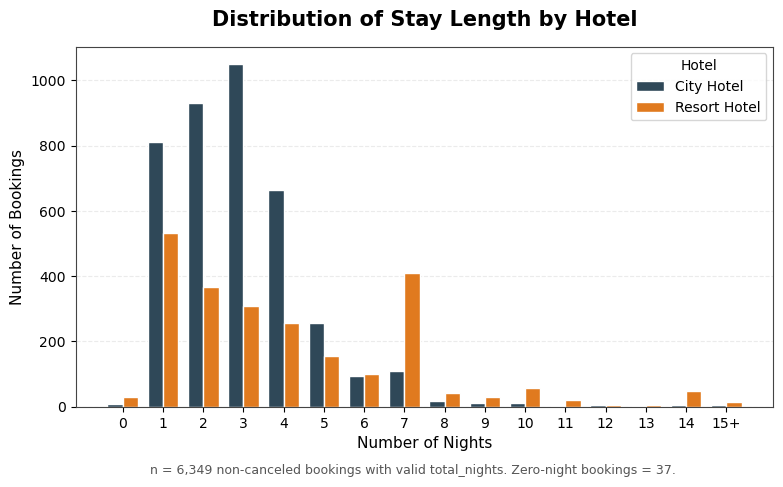

In [353]:
# Dữ liệu biểu đồ
x = np.arange(len(q09))
width = 0.38

# Màu sắc
city_color = HOTEL_COLORS["City Hotel"]
resort_color = HOTEL_COLORS["Resort Hotel"]

# Tạo biểu đồ
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    q09["City Hotel"],
    width,
    label="City Hotel",
    color=city_color,
    edgecolor="white"
)

ax.bar(
    x + width / 2,
    q09["Resort Hotel"],
    width,
    label="Resort Hotel",
    color=resort_color,
    edgecolor="white"
)

# Tiêu đề và nhãn trục
ax.set_title(
    "Distribution of Stay Length by Hotel",
    fontsize=15,
    fontweight="bold", pad=15)

ax.set_xlabel("Number of Nights", fontsize=11)
ax.set_ylabel("Number of Bookings", fontsize=11)

# Nhãn trục X
ax.set_xticks(x)
ax.set_xticklabels(q09["nights_group"])

# Chú thích
ax.legend(title="Hotel", fontsize=10)

# Đường lưới
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", alpha=0.25)

# Hiển thị viền biểu đồ
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.8)
    spine.set_color("#444444")

# Ghi chú
fig.text(
    0.5, 0.015,
    f"n = {len(not_canceled):,} non-canceled bookings with valid total_nights. "
    f"Zero-night bookings = {n_zero_nights:,}.",
    ha="center",
    fontsize=9,
    color="#555555"
)

fig.subplots_adjust(bottom=0.15, top=0.87)

# Lưu biểu đồ
save_fig(fig, "fig08_stay_nights")

plt.show()


In [354]:
check('q09_stay_nights đã được tạo', lambda: q09 is not None and len(q09) > 0)
check('Đã lưu fig08_stay_nights.png', lambda: (OUTPUT_DIR / 'figures' / 'fig08_stay_nights.png').exists())

✅ q09_stay_nights đã được tạo
✅ Đã lưu fig08_stay_nights.png


True

> **✍️ Nhận xét Câu 9** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
>
> 1. **Phát hiện chính:** Nhóm 1–3 đêm chiếm phần lớn lượng đặt phòng (3996 bookings trên tổng số 6349 bookings hợp lệ). City Hotel có số booking tập trung nhiều ở các kỳ lưu trú ngắn (1–4 đêm), trong khi Resort Hotel có xu hướng đáng chú ý ở nhóm 7 đêm: 410 booking, so với 108 booking tại City Hotel.
> 2. **Số liệu và mẫu số:** Có tổng 6349 booking không bị hủy và có dữ liệu total_nights hợp lệ, có 37 booking lưu trú 0 đêm, vẫn được giữ lại trong phân tích. Ngoài ra, 25 booking bị loại khỏi phân tích do thiếu giá trị total_nights. Tỷ lệ các booking lưu trú từ 1 đến 3 đêm được tính bằng cách lấy số booking thuộc nhóm này chia cho tổng số 6349 booking hợp lệ.
> 3. **So sánh làm rõ:** Tỷ lệ booking lưu trú từ 1–3 đêm tại City Hotel là 70.28% (2791 booking), cao hơn đáng kể so với Resort Hotel là 50.67% (1205 booking). Như vậy, tỷ lệ lưu trú ngắn tại City Hotel cao hơn Resort Hotel 19.61 điểm phần trăm, tương đương khoảng 1.39 lần. Điều này cho thấy khách tại City Hotel có xu hướng lưu trú ngắn ngày nhiều hơn, trong khi khách tại Resort Hotel có xu hướng ở lâu hơn.
> 4. **Giới hạn:** dữ liệu không phản ánh chính xác số đêm khách thực sự lưu trú. Dataset không cung cấp thông tin để xác định liệu khách có trả phòng sớm hơn so với thời gian đã đặt hay không.
>
> *Nguồn: bảng `outputs/tables/q09_stay_nights.csv` · `outputs/figures/fig08_stay_nights.png`*

## Câu 10 · Đổi loại phòng khi nhận phòng

| | |
|---|---|
| **Cần tính** | Trong đặt phòng **Check-Out** có đủ cả hai loại phòng: tỷ lệ `room_changed_flag` theo khách sạn và theo `reserved_room_type`. |
| **Mẫu số và trình bày** | Mẫu số: số đặt phòng Check-Out có đủ hai loại phòng. Biểu đồ tùy chọn (`fig09_room_change.png`). Không suy ra lý do đổi phòng (nâng hạng hay hết phòng). |
| **Đầu ra** | `clean_df` → `q10_room_change_by_hotel`, `q10_room_change_by_reserved_type` |

**Gợi ý:** Với loại phòng có rất ít đặt phòng, nêu cỡ mẫu bên cạnh tỷ lệ.

In [355]:
# Lọc booking Check-Out có đầy đủ dữ liệu cho cả hai bảng
q10_valid = clean_df[
    (clean_df["reservation_status"] == "Check-Out")
    & (clean_df["hotel"].notna())
    & (clean_df["reserved_room_type"].notna())
    & (clean_df["room_changed_flag"].notna())
].copy()

# Kiểm tra số lượng booking hợp lệ
print("Total valid bookings:", len(q10_valid))

print("\nBookings by hotel:")
print(q10_valid["hotel"].value_counts())

print("\nBookings by reserved room type:")
print(q10_valid["reserved_room_type"].value_counts())

print("\nMissing values:")
print(q10_valid[
    ["reservation_status", "hotel", "reserved_room_type", "room_changed_flag"]
].isna().sum())

Total valid bookings: 6242

Bookings by hotel:
hotel
City Hotel      3891
Resort Hotel    2351
Name: count, dtype: int64

Bookings by reserved room type:
reserved_room_type
A    4287
D    1137
E     397
F     174
G     110
B      64
C      50
H      23
Name: count, dtype: Int64

Missing values:
reservation_status    0
hotel                 0
reserved_room_type    0
room_changed_flag     0
dtype: int64


In [356]:
# Tính số booking và số booking đổi phòng theo khách sạn
q10 = (
    q10_valid.groupby("hotel")
    .agg(
        total_bookings=("room_changed_flag", "size"),
        room_changed_count=("room_changed_flag", "sum")
    )
    .reset_index()
)

# Tính tỷ lệ đổi phòng
q10["room_changed_pct"] = (
    q10["room_changed_count"]
    / q10["total_bookings"]
    * 100
).round(2)

# Hiển thị kết quả
q10

,hotel,total_bookings,room_changed_count,room_changed_pct
0,City Hotel,3891,561,14.42
1,Resort Hotel,2351,583,24.8


In [357]:
# Tính số booking và số booking đổi phòng theo loại phòng đã đặt
q10_b = (
    q10_valid.groupby("reserved_room_type")
    .agg(
        total_bookings=("room_changed_flag", "size"),
        room_changed_count=("room_changed_flag", "sum")
    )
    .reset_index()
)

# Tính tỷ lệ đổi phòng
q10_b["room_changed_pct"] = (
    q10_b["room_changed_count"]
    / q10_b["total_bookings"]
    * 100
).round(2)

# Hiển thị kết quả
q10_b

,reserved_room_type,total_bookings,room_changed_count,room_changed_pct
0,A,4287,948,22.11
1,B,64,11,17.19
2,C,50,4,8.0
3,D,1137,114,10.03
4,E,397,47,11.84
5,F,174,15,8.62
6,G,110,3,2.73
7,H,23,2,8.7


In [358]:
save_table(q10, 'q10_room_change_by_hotel')
save_table(q10_b, 'q10_room_change_by_reserved_type')

💾 outputs/tables/q10_room_change_by_hotel.csv  (2 dòng)
💾 outputs/tables/q10_room_change_by_reserved_type.csv  (8 dòng)


In [359]:
check('q10_room_change_by_hotel đã được tạo', lambda: q10 is not None and len(q10) > 0)
check('q10_room_change_by_reserved_type đã được tạo', lambda: q10_b is not None and len(q10_b) > 0)

✅ q10_room_change_by_hotel đã được tạo
✅ q10_room_change_by_reserved_type đã được tạo


True

> **✍️ Nhận xét Câu 10** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
>
> 1. **Phát hiện chính:** Resort Hotel có tỷ lệ đổi phòng cao hơn City Hotel(24.8-14.42= 10.38(%)) và loại phòng A có tỷ lệ đổi phòng cao nhất trong các nhóm loại phòng được phân tích (22,11%).
> 2. **Số liệu và mẫu số:**Phân tích được thực hiện trên tổng cộng 6242 booking Check-Out có đầy đủ thông tin về khách sạn, loại phòng đã đặt và trạng thái đổi phòng. Trong đó, City Hotel có 3891 booking và Resort Hotel có 2351 booking. Xét theo loại phòng đặt trước, loại A có số lượng booking lớn nhất với 4287 booking, trong khi loại H có số lượng nhỏ nhất với 23 booking.
> 3. **So sánh làm rõ:** Tỷ lệ đổi phòng tại Resort Hotel  cao hơn City Hotel với mức chênh lệch 10.38 điểm phần trăm, tương đương khoảng 1.72 lần. Xét theo loại phòng đặt trước, loại A có tỷ lệ đổi phòng cao nhất (22.11%), trong khi loại G có tỷ lệ thấp nhất (2.73%), chênh lệch 19.38 điểm phần trăm. Tuy nhiên, cần thận trọng khi so sánh các loại phòng có cỡ mẫu nhỏ, đặc biệt là loại G (110 booking) và H (23 booking).
> 4. **Giới hạn:** dữ liệu không cho biết nguyên nhân cụ thể dẫn đến việc thay đổi.chỉ cho biết booking có thay đổi loại phòng hay không thông qua `room_changed_flag`.
>
> *Nguồn: bảng `outputs/tables/…`*

---
## 6 INSIGHT CÓ BẰNG CHỨNG

### **INSIGHT 1**: City Hotel có mức giá phòng trung bình cao hơn Resort Hotel, nhưng sự khác biệt về giá cần được kiểm định thống kê.

In [360]:
base_adr = clean_df.copy()

# Chỉ lấy booking không bị hủy và ADR hợp lệ
adr_valid = base_adr[
    (base_adr["is_canceled"] == 0)
    & (base_adr["adr"].notna())
    & (base_adr["adr"] > 0)
].copy()

city_adr = adr_valid.loc[
    adr_valid["hotel"] == "City Hotel", "adr"
]

resort_adr = adr_valid.loc[
    adr_valid["hotel"] == "Resort Hotel", "adr"
]
from scipy.stats import f

# 1. Tính phương sai mẫu
var_city = city_adr.var(ddof=1)
var_resort = resort_adr.var(ddof=1)

# 2. Tính F-statistic
f_stat = var_city / var_resort

# 3. Bậc tự do
df1 = len(city_adr) - 1
df2 = len(resort_adr) - 1

# 4. Tính p-value (kiểm định hai phía)
p_value = 2 * min(
    f.cdf(f_stat, df1, df2),
    f.sf(f_stat, df1, df2)
)

# 5. Kết luận
alpha = 0.05

print("F-statistic:", f_stat)
print("p-value:", p_value)
print("df1:", df1)
print("df2:", df2)

if p_value < alpha:
    print("Reject H0: Hai phương sai khác nhau có ý nghĩa thống kê.")
else:
    print("Fail to reject H0: Chưa đủ bằng chứng kết luận hai phương sai khác nhau.")
# Welch's Two-Sample t-test
test_adr = ttest_ind(
    city_adr,
    resort_adr,
    equal_var=False,
    alternative="greater"
)

# Chênh lệch ADR trung bình
mean_diff = city_adr.mean() - resort_adr.mean()

# Standard error và Welch degrees of freedom
n1, n2 = len(city_adr), len(resort_adr)
v1, v2 = city_adr.var(ddof=1), resort_adr.var(ddof=1)

se = np.sqrt(v1/n1 + v2/n2)

df_welch = (v1/n1 + v2/n2)**2 / (
    (v1/n1)**2/(n1-1) +
    (v2/n2)**2/(n2-1)
)

# 95% Confidence Interval
t_critical = t.ppf(0.95, df_welch)

ci_lower = mean_diff - t_critical * se
ci_upper = mean_diff + t_critical * se

# Kết quả
print("===== WELCH TWO-SAMPLE T-TEST =====")
print(f"City Hotel mean: {city_adr.mean():.2f}")
print(f"Resort Hotel mean: {resort_adr.mean():.2f}")
print(f"Mean difference: {mean_diff:.2f}")
print(f"T-statistic: {test_adr.statistic:.4f}")
print(f"Degrees of freedom: {df_welch:.2f}")
print(f"P-value: {test_adr.pvalue:.6g}")
print(f"95% CI: [{ci_lower:.2f}, {ci_upper:.2f}]")

if test_adr.pvalue < 0.05:
    print("Reject H0: Có đủ bằng chứng để kết luận ADR trung bình của City Hotel > Hotel Resort")
else:
    print("Chưa đủ bằng chứng để kết luận về ADR trung bình của City Hotel > Hotel Resort")


F-statistic: 0.42188299469072094
p-value: 3.799704894592582e-123
df1: 3827
df2: 2292
Reject H0: Hai phương sai khác nhau có ý nghĩa thống kê.
===== WELCH TWO-SAMPLE T-TEST =====
City Hotel mean: 108.17
Resort Hotel mean: 93.61
Mean difference: 14.57
T-statistic: 10.7528
Degrees of freedom: 3464.30
P-value: 7.50514e-27
95% CI: [12.34, 16.80]
Reject H0: Có đủ bằng chứng để kết luận ADR trung bình của City Hotel > Hotel Resort


### **INSIGHT 6**: Khách hàng từng trải nghiệm dịch vụ của khách sạn thì sẽ có số ngày đặt trước ít hơn

In [361]:
# Tạo bản dữ liệu riêng phục vụ phân tích
basis = clean_df.copy()

repeat_lead = basis[
    basis["lead_time"].notna()
    & basis["is_repeated_guest"].notna()
].copy()

# Gán nhãn nhóm khách
repeat_lead["guest_type"] = repeat_lead["is_repeated_guest"].map({
    0: "New Guest",
    1: "Repeated Guest"
})

# Thống kê Lead Time theo nhóm
q_repeat_lead = (
    repeat_lead.groupby("guest_type")["lead_time"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
        max="max"
    )
    .reset_index()
)

q_repeat_lead["percentage"] = (
    q_repeat_lead["count"] / q_repeat_lead["count"].sum() * 100
).round(2)

q_repeat_lead[
    ["mean", "median", "std", "Q1", "Q3"]
] = q_repeat_lead[
    ["mean", "median", "std", "Q1", "Q3"]
].round(2)

display(q_repeat_lead)
save_table(q_repeat_lead, "q_repeat_lead")

,guest_type,count,mean,median,std,min,Q1,Q3,max,percentage
0,New Guest,9676,106.94,74.0,106.76,0,22,163,709,97.06
1,Repeated Guest,293,38.11,4.0,80.42,0,0,21,321,2.94


⚠️  Tên q_repeat_lead.csv không có trong danh sách chuẩn: kiểm tra lại chính tả.
💾 outputs/tables/q_repeat_lead.csv  (2 dòng)


C:\Users\MINH VU 2007\AppData\Local\Temp\ipykernel_36332\214619446.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = plt.boxplot(


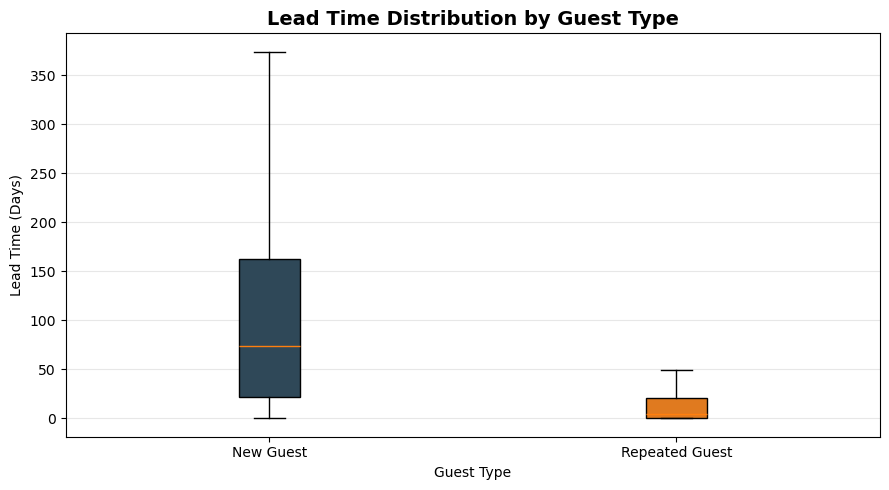

Spearman correlation: -0.1669
p-value: 3.353935080387341e-63
Có mối tương quan có ý nghĩa thống kê.


In [ ]:
GUEST_COLORS = {
    "New Guest": "#2F4858",
    "Repeated Guest": "#E07A1F"
}

plt.figure(figsize=(9, 5))

data = [
    repeat_lead.loc[
        repeat_lead["is_repeated_guest"] == 0, "lead_time"
    ],
    repeat_lead.loc[
        repeat_lead["is_repeated_guest"] == 1, "lead_time"
    ]
]

bp = plt.boxplot(
    data,
    labels=["New Guest", "Repeated Guest"],
    showfliers=False,
    patch_artist=True
)

# Tô màu từng nhóm
for patch, color in zip(bp["boxes"], GUEST_COLORS.values()):
    patch.set_facecolor(color)

plt.title(
    "Lead Time Distribution by Guest Type",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Guest Type")
plt.ylabel("Lead Time (Days)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Lưu hình
plt.savefig("outputs/figures/repeat_lead_boxplot.png")
plt.show()
corr, p_value = spearmanr(
    repeat_lead["is_repeated_guest"],
    repeat_lead["lead_time"]
)

print("Spearman correlation:", round(corr, 4))
print("p-value:", p_value)

if p_value < 0.05:
    print("Có mối tương quan có ý nghĩa thống kê.")
else:
    print("Chưa đủ bằng chứng về mối tương quan.")



---
# GIAI ĐOẠN E · XUẤT DỮ LIỆU VÀ TỰ KIỂM TRA TRƯỚC KHI NỘP

1. Chạy ô xuất bên dưới.
2. **Restart & Run all** — mọi ô phải chạy không lỗi, số thứ tự ô liên tục 1, 2, 3…
3. Xem bảng tiến độ: mục tiêu 100%.
4. (Khuyến nghị) Chạy `python tools/kiem_tra_nop_bai.py <thư mục bài nộp>` trên thư mục đã sắp xếp theo Mục 12 của đề.

In [ ]:
outputs = {
    'bookings_clean.csv': clean_df,
    'monthly_summary.csv': monthly_summary,
    'cleaning_log.csv': cleaning_log,
    'row_lineage.csv': row_lineage,
    'quality_report.csv': quality_report,
}
for filename, frame in outputs.items():
    if frame is None:
        print(f'⏳ CHƯA XUẤT {filename}: biến còn None.')
    else:
        frame.to_csv(OUTPUT_DIR / filename, index=False, encoding='utf-8-sig')
        print(f'💾 outputs/{filename}  ({len(frame)} dòng)')

💾 outputs/bookings_clean.csv  (10000 dòng)
💾 outputs/monthly_summary.csv  (52 dòng)
💾 outputs/cleaning_log.csv  (14 dòng)
💾 outputs/row_lineage.csv  (10325 dòng)
💾 outputs/quality_report.csv  (48 dòng)


In [ ]:
show_progress()

Tiến độ tệp đầu ra: 27/27 (100%)


,Nhóm,Tệp,Có
0,Dữ liệu,bookings_clean.csv,✅
1,Dữ liệu,monthly_summary.csv,✅
2,Dữ liệu,cleaning_log.csv,✅
3,Dữ liệu,row_lineage.csv,✅
4,Dữ liệu,quality_report.csv,✅
5,Bảng,a_missing_survey.csv,✅
6,Bảng,a_issue_catalog.csv,✅
7,Bảng,q01_before_after.csv,✅
8,Bảng,q02_hotel_cancel.csv,✅
9,Bảng,q03_monthly_arrivals_2016.csv,✅


In [ ]:
# # (Tùy chọn — Colab) Nén thư mục outputs để tải về máy trước khi phiên Colab kết thúc
# import shutil
# archive = shutil.make_archive('outputs_backup', 'zip', OUTPUT_DIR)
# print('Đã tạo', archive, '— tải về từ bảng Files.')

Đã tạo c:\Users\MINH VU 2007\OneDrive\Desktop\Program\FDA - Data analysis with Python\Khach_san_Sinh_vien\outputs_backup.zip — tải về từ bảng Files.
